# Lexical Profile of Kazakh Legal Language

**Programming for Data Science — Final Project**

This notebook analyzes 215,889 legal document metadata records from Kazakhstan.

The project includes data preprocessing, Kazakh NLP, morphological normalization, SQL analysis, and TF-IDF document retrieval.

**Scope:** Legal document titles and descriptions, not full legislative texts.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## Environment setup

This cell restores the verified KazStem 0.2.1 FST resources from Google Drive and validates the morphological analyzer.


In [2]:
import os
import sys
import json
import hashlib
import tarfile
import subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("=" * 65)
print("KAZSTEM — REPRODUCIBLE SETUP")
print("=" * 65)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

ARCHIVE = (
    PROJECT_DIR / "resources" /
    "kazstem-0.2.1-linux-x86_64-ubuntu24.04.tar.gz"
)

INSTALL_DIR = Path("/content/kazstem_runtime")

EXPECTED_HASH = (
    "1c0b48d949d06aab31fadf0d68da32290"
    "a865a66a1c20db8ea4c8cb45ab0f8e4"
)

assert ARCHIVE.is_file(), "KazStem archive missing"

try:
    installed = version("kazstem")
except PackageNotFoundError:
    installed = None

if installed != "0.2.1":
    subprocess.run(
        [
            sys.executable, "-m", "pip",
            "install", "kazstem==0.2.1"
        ],
        check=True
    )

print("[PASSED] KazStem Python package")

digest = hashlib.sha256()

with ARCHIVE.open("rb") as file:
    for block in iter(
        lambda: file.read(1024 * 1024), b""
    ):
        digest.update(block)

assert digest.hexdigest() == EXPECTED_HASH, (
    "Archive checksum mismatch"
)

print("[PASSED] Archive SHA-256")

INSTALL_DIR.mkdir(parents=True, exist_ok=True)
root = INSTALL_DIR.resolve()

with tarfile.open(ARCHIVE, "r:gz") as tar:
    members = tar.getmembers()
    regular_members = []
    links = []

    for member in members:
        target = root / member.name

        if not target.resolve().is_relative_to(root):
            raise ValueError("Unsafe archive path")

        if member.issym():
            link_target = (
                target.parent / member.linkname
            ).resolve()

            if not link_target.is_relative_to(root):
                raise ValueError("Unsafe symbolic link")

            links.append(member)

        elif member.isfile() or member.isdir():
            regular_members.append(member)

        else:
            raise ValueError(
                f"Unsupported archive entry: {member.name}"
            )

    tar.extractall(
        INSTALL_DIR,
        members=regular_members,
        filter="data"
    )

print("[PASSED] Resource files extracted")

pending = links.copy()
restored = 0

while pending:
    next_pending = []
    progress = False

    for member in pending:
        link = root / member.name
        target = (link.parent / member.linkname).resolve()

        if link.is_symlink():
            if os.readlink(link) != member.linkname:
                raise ValueError("Unexpected existing symlink")
            progress = True
            continue

        if link.exists():
            raise ValueError("Unexpected existing file")

        if target.exists():
            link.symlink_to(member.linkname)
            restored += 1
            progress = True
        else:
            next_pending.append(member)

    if not progress:
        raise RuntimeError(
            "Cannot restore links: "
            + str([m.name for m in next_pending])
        )

    pending = next_pending

print("[PASSED] Symbolic links restored:", restored)

resource_files = list(
    INSTALL_DIR.rglob("kaz.automorf.hfstol")
)

assert len(resource_files) == 1

resource_dir = resource_files[0].parent

os.environ["QAZMORPH_RESOURCE_DIR"] = str(resource_dir)

print("[PASSED] FST resource directory configured")

result = subprocess.run(
    [
        "kazstem",
        "--resource-dir", str(resource_dir),
        "--no-guesser",
        "--format", "json",
        "-"
    ],
    input="мемлекеттің\nзаңдар\nшешіміне\n",
    text=True,
    capture_output=True,
    timeout=90
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

data = json.loads(result.stdout)

assert len(data) == 3

for item in data:
    print(
        item["text"],
        "->",
        sorted({
            a["lex"]
            for a in item.get("analysis", [])
            if a.get("lex")
        })
    )

print("\n" + "=" * 65)
print("[PASSED] KAZSTEM REPRODUCIBLE SETUP")
print("=" * 65)

KAZSTEM — REPRODUCIBLE SETUP
[PASSED] KazStem Python package
[PASSED] Archive SHA-256
[PASSED] Resource files extracted
[PASSED] Symbolic links restored: 34
[PASSED] FST resource directory configured
мемлекеттің -> ['мемлекет']
заңдар -> ['заң']
шешіміне -> ['шешім']

[PASSED] KAZSTEM REPRODUCIBLE SETUP


In [3]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

folders = [
    "data/raw",
    "data/processed",
    "data/database",
    "results/figures",
    "results/tables",
    "notebooks"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory created successfully!")
print(PROJECT_DIR)

Project directory created successfully!
/content/drive/MyDrive/Kazakh_Legal_Language_Project


In [4]:
from pathlib import Path
import psutil
import os

CSV_PATH = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project/data/raw/kazakhlawcorpus_kk_only.csv"
)

if CSV_PATH.exists():
    print("Dataset found successfully!")
    print(f"File size: {CSV_PATH.stat().st_size / (1024**2):.2f} MB")
else:
    print("ERROR: Dataset not found!")
    print("Files in raw folder:")
    print(list(CSV_PATH.parent.glob("*")))

memory = psutil.virtual_memory()

print("\nSYSTEM INFORMATION")
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent}%")

Dataset found successfully!
File size: 321.16 MB

SYSTEM INFORMATION
Total RAM: 12.67 GB
Available RAM: 11.12 GB
RAM usage: 12.2%


In [5]:
import pandas as pd

sample_df = pd.read_csv(
    CSV_PATH,
    nrows=5,
    encoding="utf-8-sig"
)

print("Dataset columns:")
print(sample_df.columns.tolist())

print("\nDataset preview:")
display(sample_df.head())

print("\nNumber of columns:", len(sample_df.columns))

Dataset columns:
['source_id', 'law_id', 'date_adopted', 'date_modified', 'date_published', 'state_registry_number', 'law_registry_number', 'gov_registration_number', 'ministry_registration_date', 'is_archive', 'is_repealed', 'adilet_url', 'ekb_url', 'title', 'description', 'official_publication_info', 'act_form', 'legal_relation_area', 'legal_force', 'adopting_body', 'regulatory_body', 'developer_body', 'region', 'place_of_adoption', 'database_section']

Dataset preview:


,source_id,law_id,date_adopted,date_modified,date_published,state_registry_number,law_registry_number,gov_registration_number,ministry_registration_date,is_archive,...,official_publication_info,act_form,legal_relation_area,legal_force,adopting_body,regulatory_body,developer_body,region,place_of_adoption,database_section
0,223103,A04C0000417,2004-07-15,NaN,NaN,NaN,417,NaN,NaN,f,...,ЖОҚ,Бұйрық,"Нормативтік құқықтық актілер: дайындау, қабылд...",Қалғандары,Қазақстан Республикасының Ішкі істер министрлігі,ЖОҚ,NaN,Қазақстан Республикасы,Астана қаласы,Конституциялық құрылыс және мемлекеттік басқар...
1,215496,A05I0001722,2005-04-18,NaN,NaN,NaN,151-I,undefined,NaN,f,...,ЖОҚ,Бұйрық,"Су көлігі, Көліктегі қауіпсіздік, Нормативтік ...",Министрлік пен ведомствоның актісі,Қазақстан Республикасының Көлік және коммуника...,ЖОҚ,NaN,Қазақстан Республикасы,Астана қаласы,Көлік
2,214892,A06C0001819,2006-12-30,NaN,NaN,NaN,606,undefined,NaN,f,...,ЖОҚ,Бұйрық,Ішкі істер органдары. Жол полициясы,Министрлік пен ведомствоның актісі,Қазақстан Республикасының Ішкі істер министрлігі,ЖОҚ,NaN,Қазақстан Республикасы,Астана қаласы,Ұлттық қауіпсіздік. Қоғамдық тәртіпті қорғау
3,223102,A06G0002831,2006-12-29,NaN,NaN,NaN,311-ө,undefined,NaN,f,...,Қазақстан Республикасы орталық атқарушы және ө...,Бұйрық,"Зейнетақы қорлары. Әлеуметтік қорғау қорлары, ...",Қалғандары,Қазақстан Республикасының Еңбек және халықты ә...,ЖОҚ,NaN,Қазақстан Республикасы,Астана қаласы,Әлеуметтік қамсыздандыру. Сақтандыру
4,214765,A07C0001814,2007-05-10,2016-02-18,NaN,NaN,201,НЕТ,NaN,f,...,ЖОҚ,Бұйрық,Қоғамдық тәртіпті қорғау және құқық бұзушылыққ...,Министрлік пен ведомствоның актісі,Қазақстан Республикасының Ішкі істер министрлігі,ЖОҚ,NaN,Қазақстан Республикасы,Астана қаласы,Ұлттық қауіпсіздік. Қоғамдық тәртіпті қорғау



Number of columns: 25




```
# Выбран кодовый формат
```

## 1. Dataset exploration


In [6]:
print("DATASET STRUCTURE")
print("=" * 50)

for number, column in enumerate(sample_df.columns, start=1):
    print(f"{number:02d}. {column}")

print("\nTEXT FIELD PREVIEW")
print("=" * 50)

for column in ["title", "description"]:
    print(f"\n{column.upper()}:")

    for i, text in enumerate(sample_df[column].head(3), start=1):
        print(f"{i}. {str(text)[:300]}")
        print("-" * 30)

DATASET STRUCTURE
01. source_id
02. law_id
03. date_adopted
04. date_modified
05. date_published
06. state_registry_number
07. law_registry_number
08. gov_registration_number
09. ministry_registration_date
10. is_archive
11. is_repealed
12. adilet_url
13. ekb_url
14. title
15. description
16. official_publication_info
17. act_form
18. legal_relation_area
19. legal_force
20. adopting_body
21. regulatory_body
22. developer_body
23. region
24. place_of_adoption
25. database_section

TEXT FIELD PREVIEW

TITLE:
1. Қазақстан Республикасы Ішкі істер министрінің кейбір бұйрықтарының күшін жою туралы
------------------------------
2. "Кеме қатынасы және теңізде жүзу қауіпсіздігі туралы" Қазақстан Республикасы Көлік және коммуникациялар министрінің 1995 жылғы 2 мамырдағы N 94 бұйрығының күші жойылды деп тану туралы
------------------------------
3. 1999 жылдан бастап 2005 жылдар аралығында Қазақстан Республикасы Ішкі істер министрілігінің кейбір бұйрықтарының күші жойылды деп тану туралы
-------

In [7]:
import pandas as pd
import psutil
import os
import time

start_time = time.time()

CHUNK_SIZE = 10000

total_rows = 0
total_chunks = 0
max_chunk_memory = 0
missing_values = pd.Series(dtype="int64")

seen_ids = set()
duplicate_ids = 0

invalid_dates = 0

process = psutil.Process(os.getpid())

print("Starting chunk processing...\n")

for chunk in pd.read_csv(
    CSV_PATH,
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig"
):

    total_chunks += 1
    total_rows += len(chunk)

    missing_values = (
        missing_values.add(
            chunk.isna().sum(),
            fill_value=0
        )
    )

    for law_id in chunk["law_id"].dropna().astype(str):
        if law_id in seen_ids:
            duplicate_ids += 1
        else:
            seen_ids.add(law_id)

    parsed_dates = pd.to_datetime(
        chunk["date_adopted"],
        errors="coerce"
    )

    invalid_dates += (
        parsed_dates.isna() &
        chunk["date_adopted"].notna()
    ).sum()

    chunk_memory = (
        chunk.memory_usage(deep=True).sum()
        / (1024 ** 2)
    )

    max_chunk_memory = max(
        max_chunk_memory,
        chunk_memory
    )

    if total_chunks % 5 == 0:
        print(
            f"Processed {total_rows:,} rows | "
            f"Chunk {total_chunks}"
        )

elapsed_time = time.time() - start_time

print("\n" + "=" * 50)
print("CHUNK PROCESSING RESULTS")
print("=" * 50)

print(f"Total rows: {total_rows:,}")
print(f"Total chunks: {total_chunks}")
print(f"Duplicate law IDs: {duplicate_ids}")
print(f"Invalid dates: {invalid_dates}")

print(
    f"Maximum chunk memory: "
    f"{max_chunk_memory:.2f} MB"
)

print(
    f"Current RAM usage: "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print(f"Execution time: {elapsed_time:.2f} seconds")

print("\nMissing values by column:")
print(missing_values.astype(int).sort_values(ascending=False))

Starting chunk processing...

Processed 50,000 rows | Chunk 5
Processed 100,000 rows | Chunk 10
Processed 150,000 rows | Chunk 15
Processed 200,000 rows | Chunk 20

CHUNK PROCESSING RESULTS
Total rows: 215,889
Total chunks: 22
Duplicate law IDs: 0
Invalid dates: 0
Maximum chunk memory: 30.53 MB
Current RAM usage: 0.23 GB
Execution time: 24.93 seconds

Missing values by column:
date_published                190769
ministry_registration_date    186994
developer_body                148355
date_modified                 106980
ekb_url                        33742
state_registry_number          30868
gov_registration_number        25126
official_publication_info        951
adilet_url                       794
legal_relation_area              305
database_section                 134
legal_force                       78
act_form                          61
adopting_body                     28
region                            24
place_of_adoption                 19
regulatory_body             

In [8]:
from pathlib import Path
import pandas as pd

print("=" * 65)
print("GOOGLE DRIVE — CONNECTION DIAGNOSTIC")
print("=" * 65)

csv_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/raw/kazakhlawcorpus_kk_only.csv"
)

try:
    assert csv_path.is_file(), "CSV file is not accessible"

    print("[PASSED] CSV exists")
    print("Size (MB):", round(csv_path.stat().st_size / 1024**2, 2))

    sample = pd.read_csv(
        csv_path,
        nrows=5,
        encoding="utf-8-sig"
    )

    print("[PASSED] CSV can be read")
    print("Sample shape:", sample.shape)

except Exception as e:
    print("[FAILED] Google Drive connection")
    print("Error:", repr(e))

    print("\nNEXT ACTION:")
    print("Reconnect Google Drive before continuing.")

print("\nDRIVE CONNECTION DIAGNOSTIC COMPLETED")

GOOGLE DRIVE — CONNECTION DIAGNOSTIC
[PASSED] CSV exists
Size (MB): 321.16
[PASSED] CSV can be read
Sample shape: (5, 25)

DRIVE CONNECTION DIAGNOSTIC COMPLETED


In [9]:
import pandas as pd

PLACEHOLDERS = [
    "undefined",
    "null",
    "none",
    "n/a",
    "nan",
    "жоқ",
    "нет",
    "-"
]

placeholder_counts = {}

for chunk in pd.read_csv(
    CSV_PATH,
    chunksize=10000,
    encoding="utf-8-sig"
):

    for column in chunk.select_dtypes(
        include=["object", "string"]
    ).columns:

        values = (
            chunk[column]
            .astype("string")
            .str.strip()
            .str.casefold()
        )

        for placeholder in PLACEHOLDERS:

            count = (values == placeholder).sum()

            if count > 0:
                key = (column, placeholder)

                placeholder_counts[key] = (
                    placeholder_counts.get(key, 0)
                    + int(count)
                )

print("PLACEHOLDER VALUES AUDIT")
print("=" * 60)

for (column, value), count in sorted(
    placeholder_counts.items()
):
    print(
        f"{column:30} | "
        f"{value:15} | "
        f"{count:,}"
    )

PLACEHOLDER VALUES AUDIT
act_form                       | жоқ             | 2
adopting_body                  | жоқ             | 42
database_section               | жоқ             | 106
developer_body                 | жоқ             | 3,335
developer_body                 | нет             | 486
gov_registration_number        | undefined       | 23,948
gov_registration_number        | нет             | 54,826
law_registry_number            | жоқ             | 434
law_registry_number            | нет             | 12
legal_force                    | жоқ             | 2
legal_relation_area            | жоқ             | 75
official_publication_info      | жоқ             | 40,656
place_of_adoption              | жоқ             | 137
regulatory_body                | жоқ             | 93,272


In [10]:
import pandas as pd

sample_memory_df = pd.read_csv(
    CSV_PATH,
    nrows=10000,
    encoding="utf-8-sig"
)

memory_usage = (
    sample_memory_df
    .memory_usage(deep=True)
    .sort_values(ascending=False)
)

memory_report = pd.DataFrame({
    "Data Type": sample_memory_df.dtypes.astype(str),
    "Memory (MB)": (
        sample_memory_df.memory_usage(deep=True)
        / (1024 ** 2)
    )
})

print("DATA TYPES AND MEMORY USAGE")
display(memory_report.sort_values(
    by="Memory (MB)",
    ascending=False
))

print("\nTOTAL MEMORY USAGE:")
print(
    f"{sample_memory_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
)

DATA TYPES AND MEMORY USAGE


,Data Type,Memory (MB)
title,object,3.794817
legal_relation_area,object,2.943048
description,object,2.638107
adopting_body,object,1.730487
official_publication_info,object,1.584383
legal_force,object,1.236380
region,object,1.057416
database_section,object,1.038319
place_of_adoption,object,0.977755
adilet_url,object,0.867844



TOTAL MEMORY USAGE:
25.19 MB


In [11]:
import pandas as pd

profile = pd.DataFrame(index=sample_memory_df.columns)

profile["Data Type"] = sample_memory_df.dtypes.astype(str)

profile["Unique Values"] = (
    sample_memory_df.nunique(dropna=True)
)

profile["Unique Ratio (%)"] = (
    profile["Unique Values"] / len(sample_memory_df) * 100
).round(2)

profile["Memory (MB)"] = (
    sample_memory_df.memory_usage(
        index=False,
        deep=True
    ) / (1024 ** 2)
).round(3)

print("DATA TYPE PROFILING")
display(
    profile.sort_values(
        "Memory (MB)",
        ascending=False
    )
)

print("\nSOURCE_ID RANGE")
print("Minimum:", sample_memory_df["source_id"].min())
print("Maximum:", sample_memory_df["source_id"].max())

print("\nSTATE_REGISTRY_NUMBER EXAMPLES")
print(
    sample_memory_df["state_registry_number"]
    .dropna()
    .head(10)
    .tolist()
)

print("\nBOOLEAN-LIKE COLUMNS")
for column in ["is_archive", "is_repealed"]:
    print(f"\n{column}:")
    print(sample_memory_df[column].value_counts(dropna=False))

DATA TYPE PROFILING


,Data Type,Unique Values,Unique Ratio (%),Memory (MB)
title,object,7832,78.32,6.673
description,object,9800,98.00,4.426
legal_relation_area,object,1134,11.34,2.943
adopting_body,object,823,8.23,1.730
official_publication_info,object,1788,17.88,1.584
database_section,object,35,0.35,1.441
place_of_adoption,object,444,4.44,1.316
legal_force,object,20,0.20,1.236
region,object,1063,10.63,1.057
adilet_url,object,10000,100.00,0.868



SOURCE_ID RANGE
Minimum: 26249
Maximum: 381102

STATE_REGISTRY_NUMBER EXAMPLES
[63234.0, 99059.0, 66318.0, 106604.0, 100448.0, 139835.0, 150485.0, 176096.0, 175940.0, 176100.0]

BOOLEAN-LIKE COLUMNS

is_archive:
is_archive
f    10000
Name: count, dtype: int64

is_repealed:
is_repealed
f    9261
t     739
Name: count, dtype: int64


In [12]:
import pandas as pd
import numpy as np

baseline_df = pd.read_csv(
    CSV_PATH,
    nrows=10000,
    encoding="utf-8-sig"
)

memory_before = (
    baseline_df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

optimized_df = baseline_df.copy()

date_columns = [
    "date_adopted",
    "date_modified",
    "date_published",
    "ministry_registration_date"
]

date_conversion_errors = {}

for column in date_columns:

    original = optimized_df[column]

    converted = pd.to_datetime(
        original,
        errors="coerce"
    )

    date_conversion_errors[column] = int(
        (original.notna() & converted.isna()).sum()
    )

    optimized_df[column] = converted


if (
    optimized_df["source_id"].min() >= np.iinfo(np.int32).min
    and optimized_df["source_id"].max() <= np.iinfo(np.int32).max
):
    optimized_df["source_id"] = (
        optimized_df["source_id"].astype("int32")
    )


categorical_columns = [
    "act_form",
    "legal_force",
    "database_section",
    "regulatory_body"
]

for column in categorical_columns:

    unique_ratio = (
        optimized_df[column].nunique(dropna=True)
        / len(optimized_df)
    )

    if unique_ratio < 0.05:
        optimized_df[column] = (
            optimized_df[column].astype("category")
        )


boolean_columns = [
    "is_archive",
    "is_repealed"
]

boolean_mapping = {
    "t": True,
    "f": False,
    "true": True,
    "false": False
}

for column in boolean_columns:

    values = (
        optimized_df[column]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    converted = values.map(boolean_mapping)

    unexpected = (
        values.notna() & converted.isna()
    )

    if not unexpected.any():
        optimized_df[column] = converted.astype("boolean")
    else:
        print(
            f"Skipped {column}: "
            f"unexpected values found"
        )


memory_after = (
    optimized_df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

reduction = (
    (memory_before - memory_after)
    / memory_before
) * 100

print("=" * 50)
print("MEMORY OPTIMIZATION RESULTS")
print("=" * 50)

print(f"Before: {memory_before:.2f} MB")
print(f"After:  {memory_after:.2f} MB")
print(f"Memory reduction: {reduction:.2f}%")

print("\nOptimized data types:")
print(optimized_df.dtypes)

print("\nDate conversion issues:")
print(date_conversion_errors)

MEMORY OPTIMIZATION RESULTS
Before: 25.19 MB
After:  19.24 MB
Memory reduction: 23.62%

Optimized data types:
source_id                              int32
law_id                                object
date_adopted                  datetime64[ns]
date_modified                 datetime64[ns]
date_published                datetime64[ns]
state_registry_number                float64
law_registry_number                   object
gov_registration_number               object
ministry_registration_date    datetime64[ns]
is_archive                           boolean
is_repealed                          boolean
adilet_url                            object
ekb_url                               object
title                                 object
description                           object
official_publication_info             object
act_form                            category
legal_relation_area                   object
legal_force                         category
adopting_body                      

In [13]:
import pandas as pd
import numpy as np

print("=" * 55)
print("FINAL DATA INTEGRITY VALIDATION")
print("=" * 55)

assert baseline_df.shape == optimized_df.shape
print("[PASSED] 1. Dataset dimensions")

assert list(baseline_df.columns) == list(optimized_df.columns)
print("[PASSED] 2. Column names")

for column in ["law_id", "title", "description"]:
    assert baseline_df[column].equals(optimized_df[column])

print("[PASSED] 3. Original text fields")

assert np.array_equal(
    baseline_df["source_id"].to_numpy(),
    optimized_df["source_id"].to_numpy()
)

print("[PASSED] 4. Source IDs")

date_columns = [
    "date_adopted",
    "date_modified",
    "date_published",
    "ministry_registration_date"
]

for column in date_columns:
    expected = pd.to_datetime(
        baseline_df[column], errors="coerce"
    )
    actual = pd.to_datetime(
        optimized_df[column], errors="coerce"
    )

    assert expected.equals(actual)

print("[PASSED] 5. Date conversion")

categorical_columns = [
    "act_form",
    "legal_force",
    "regulatory_body",
    "database_section"
]

for column in categorical_columns:
    expected = baseline_df[column].astype("string")
    actual = optimized_df[column].astype("string")

    assert expected.equals(actual)

print("[PASSED] 6. Categorical values")

boolean_mapping = {
    "t": True,
    "f": False,
    "true": True,
    "false": False
}

for column in ["is_archive", "is_repealed"]:

    expected = (
        baseline_df[column]
        .astype("string")
        .str.strip()
        .str.casefold()
        .map(boolean_mapping)
        .astype("boolean")
    )

    actual = optimized_df[column].astype("boolean")

    assert expected.isna().equals(actual.isna())

    assert np.array_equal(
        expected.fillna(False).to_numpy(dtype=bool),
        actual.fillna(False).to_numpy(dtype=bool)
    )

print("[PASSED] 7. Boolean conversion")

print("\n" + "=" * 55)
print("ALL 7 VALIDATION CHECKS PASSED!")
print("=" * 55)


FINAL DATA INTEGRITY VALIDATION
[PASSED] 1. Dataset dimensions
[PASSED] 2. Column names
[PASSED] 3. Original text fields
[PASSED] 4. Source IDs
[PASSED] 5. Date conversion
[PASSED] 6. Categorical values
[PASSED] 7. Boolean conversion

ALL 7 VALIDATION CHECKS PASSED!


In [14]:
import pandas as pd

date_columns = [
    "date_adopted",
    "date_modified",
    "date_published",
    "ministry_registration_date"
]

boolean_columns = [
    "is_archive",
    "is_repealed"
]

check_columns = date_columns + boolean_columns

date_errors = {col: 0 for col in date_columns}
date_examples = {col: [] for col in date_columns}

boolean_values = {col: set() for col in boolean_columns}

total_checked = 0

for chunk in pd.read_csv(
    CSV_PATH,
    usecols=check_columns,
    dtype="string",
    chunksize=10000,
    encoding="utf-8-sig"
):

    total_checked += len(chunk)

    for column in date_columns:

        original = chunk[column]

        parsed = pd.to_datetime(
            original,
            errors="coerce"
        )

        invalid = original.notna() & parsed.isna()

        date_errors[column] += int(invalid.sum())

        if invalid.any() and len(date_examples[column]) < 5:
            date_examples[column].extend(
                original[invalid].head(5).tolist()
            )

    for column in boolean_columns:

        values = (
            chunk[column]
            .dropna()
            .str.strip()
            .str.casefold()
        )

        boolean_values[column].update(values.unique())

print("=" * 55)
print("FULL DATASET PREFLIGHT CHECK")
print("=" * 55)

print("Total records:", total_checked)

print("\nDATE VALIDATION")
for column in date_columns:
    print(f"{column}: {date_errors[column]} invalid values")

print("\nBOOLEAN VALUES")
for column in boolean_columns:
    print(f"{column}: {sorted(boolean_values[column])}")

print("\nInvalid date examples:")
print(date_examples)


FULL DATASET PREFLIGHT CHECK
Total records: 215889

DATE VALIDATION
date_adopted: 0 invalid values
date_modified: 0 invalid values
date_published: 0 invalid values
ministry_registration_date: 0 invalid values

BOOLEAN VALUES
is_archive: ['f']
is_repealed: ['f', 't']

Invalid date examples:
{'date_adopted': [], 'date_modified': [], 'date_published': [], 'ministry_registration_date': []}


In [15]:
try:
    import pyarrow as pa
    import pyarrow.parquet as pq

    print("PyArrow is installed!")
    print("Version:", pa.__version__)

except ImportError:
    %pip install -q pyarrow
    import pyarrow as pa
    import pyarrow.parquet as pq

    print("PyArrow installed successfully!")
    print("Version:", pa.__version__)


PyArrow is installed!
Version: 23.0.1


## 2. Data optimization


In [16]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import numpy as np
import time
import os
from pathlib import Path


OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_PATH = (
    OUTPUT_DIR / "kazakhlawcorpus_optimized.parquet"
)

TEMP_PATH = (
    OUTPUT_DIR / "kazakhlawcorpus_optimized.tmp.parquet"
)

CHUNK_SIZE = 10000


date_columns = [
    "date_adopted",
    "date_modified",
    "date_published",
    "ministry_registration_date"
]

boolean_columns = [
    "is_archive",
    "is_repealed"
]

boolean_mapping = {
    "t": True,
    "f": False
}

string_dtypes = {
    column: "string"
    for column in sample_df.columns
}


start_time = time.time()

total_rows = 0
total_chunks = 0
writer = None

if TEMP_PATH.exists():
    TEMP_PATH.unlink()

print("Starting CSV to Parquet conversion...\n")

try:

    for chunk in pd.read_csv(
        CSV_PATH,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        dtype=string_dtypes
    ):

        source_ids = pd.to_numeric(
            chunk["source_id"],
            errors="raise"
        )

        if source_ids.isna().any():
            raise ValueError("Missing source_id detected")

        if (
            source_ids.min() < np.iinfo(np.int32).min
            or source_ids.max() > np.iinfo(np.int32).max
        ):
            raise ValueError("source_id exceeds int32 range")

        chunk["source_id"] = source_ids.astype("int32")

        for column in date_columns:

            chunk[column] = pd.to_datetime(
                chunk[column],
                errors="raise"
            )

        for column in boolean_columns:

            values = (
                chunk[column]
                .str.strip()
                .str.casefold()
            )

            converted = values.map(boolean_mapping)

            invalid = values.notna() & converted.isna()

            if invalid.any():
                raise ValueError(
                    f"Unexpected Boolean values in {column}"
                )

            chunk[column] = converted.astype("boolean")

        table = pa.Table.from_pandas(
            chunk,
            preserve_index=False
        )

        if writer is None:

            writer = pq.ParquetWriter(
                TEMP_PATH,
                table.schema,
                compression="snappy",
                use_dictionary=True
            )

        if not table.schema.equals(
            writer.schema,
            check_metadata=False
        ):
            table = table.cast(writer.schema)

        writer.write_table(
            table,
            row_group_size=CHUNK_SIZE
        )

        total_rows += len(chunk)
        total_chunks += 1

        if total_chunks % 5 == 0:
            print(
                f"Processed {total_rows:,} rows | "
                f"Chunk {total_chunks}"
            )

finally:

    if writer is not None:
        writer.close()


if total_rows == 215889:

    os.replace(TEMP_PATH, PARQUET_PATH)

else:
    raise ValueError(
        f"Unexpected row count: {total_rows}"
    )


elapsed_time = time.time() - start_time

csv_size = CSV_PATH.stat().st_size / (1024 ** 2)

parquet_size = PARQUET_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 55)
print("PARQUET CONVERSION COMPLETED")
print("=" * 55)

print(f"Total rows: {total_rows:,}")
print(f"Total chunks: {total_chunks}")

print(f"CSV size: {csv_size:.2f} MB")
print(f"Parquet size: {parquet_size:.2f} MB")

print(
    f"Storage reduction: "
    f"{(1 - parquet_size / csv_size) * 100:.2f}%"
)

print(f"Execution time: {elapsed_time:.2f} seconds")

print("\nSaved file:")
print(PARQUET_PATH)


Starting CSV to Parquet conversion...

Processed 50,000 rows | Chunk 5
Processed 100,000 rows | Chunk 10
Processed 150,000 rows | Chunk 15
Processed 200,000 rows | Chunk 20

PARQUET CONVERSION COMPLETED
Total rows: 215,889
Total chunks: 22
CSV size: 321.16 MB
Parquet size: 37.22 MB
Storage reduction: 88.41%
Execution time: 21.46 seconds

Saved file:
/content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/kazakhlawcorpus_optimized.parquet


In [17]:
import pandas as pd
import pyarrow.parquet as pq
import numpy as np

parquet_file = pq.ParquetFile(PARQUET_PATH)

print("=" * 55)
print("PARQUET INTEGRITY VALIDATION")
print("=" * 55)

print("Rows:", parquet_file.metadata.num_rows)
print("Columns:", len(parquet_file.schema_arrow.names))
print("Row groups:", parquet_file.metadata.num_row_groups)

original_columns = list(
    pd.read_csv(CSV_PATH, nrows=0).columns
)

parquet_columns = parquet_file.schema_arrow.names

assert original_columns == parquet_columns
assert parquet_file.metadata.num_rows == 215889

print("\n[PASSED] Dataset dimensions")
print("[PASSED] Column names and order")

check_columns = [
    "law_id",
    "source_id",
    "title",
    "description"
]

csv_reader = pd.read_csv(
    CSV_PATH,
    usecols=check_columns,
    dtype={
        "law_id": "string",
        "source_id": "string",
        "title": "string",
        "description": "string"
    },
    chunksize=10000,
    encoding="utf-8-sig"
)

parquet_reader = parquet_file.iter_batches(
    batch_size=10000,
    columns=check_columns
)

total_checked = 0

for csv_chunk in csv_reader:

    parquet_batch = next(parquet_reader)
    parquet_chunk = parquet_batch.to_pandas()

    for column in [
        "law_id",
        "title",
        "description"
    ]:

        original = (
            csv_chunk[column]
            .astype("string")
            .reset_index(drop=True)
        )

        converted = (
            parquet_chunk[column]
            .astype("string")
            .reset_index(drop=True)
        )

        pd.testing.assert_series_equal(
            original,
            converted,
            check_names=False
        )

    original_ids = pd.to_numeric(
        csv_chunk["source_id"]
    ).astype("int64").to_numpy()

    converted_ids = pd.to_numeric(
        parquet_chunk["source_id"]
    ).astype("int64").to_numpy()

    assert np.array_equal(
        original_ids,
        converted_ids
    )

    total_checked += len(csv_chunk)

print("\n[PASSED] law_id comparison")
print("[PASSED] title comparison")
print("[PASSED] description comparison")
print("[PASSED] source_id comparison")

print("\nTotal records compared:", total_checked)

assert total_checked == 215889

print("\n" + "=" * 55)
print("ALL PARQUET VALIDATION CHECKS PASSED!")
print("=" * 55)

PARQUET INTEGRITY VALIDATION
Rows: 215889
Columns: 25
Row groups: 22

[PASSED] Dataset dimensions
[PASSED] Column names and order

[PASSED] law_id comparison
[PASSED] title comparison
[PASSED] description comparison
[PASSED] source_id comparison

Total records compared: 215889

ALL PARQUET VALIDATION CHECKS PASSED!


In [18]:
import pandas as pd
import time
import gc
import statistics

REPEATS = 3

def benchmark_read(file_type, text_only=False):

    times = []

    for run in range(REPEATS):

        start = time.perf_counter()

        if file_type == "CSV":

            if text_only:
                df = pd.read_csv(
                    CSV_PATH,
                    usecols=["title", "description"],
                    encoding="utf-8-sig"
                )
            else:
                df = pd.read_csv(
                    CSV_PATH,
                    encoding="utf-8-sig"
                )

        elif file_type == "Parquet":

            if text_only:
                df = pd.read_parquet(
                    PARQUET_PATH,
                    columns=["title", "description"]
                )
            else:
                df = pd.read_parquet(PARQUET_PATH)

        elapsed = time.perf_counter() - start

        times.append(elapsed)

        assert len(df) == 215889

        del df
        gc.collect()

    return statistics.median(times)


results = {}

results["CSV - All columns"] = benchmark_read(
    "CSV", text_only=False
)

results["Parquet - All columns"] = benchmark_read(
    "Parquet", text_only=False
)

results["CSV - Text only"] = benchmark_read(
    "CSV", text_only=True
)

results["Parquet - Text only"] = benchmark_read(
    "Parquet", text_only=True
)


print("=" * 60)
print("CSV VS PARQUET PERFORMANCE BENCHMARK")
print("=" * 60)

for name, seconds in results.items():
    print(f"{name:30} | {seconds:.3f} seconds")

print("\nSPEED COMPARISON")

full_speedup = (
    results["CSV - All columns"] /
    results["Parquet - All columns"]
)

text_speedup = (
    results["CSV - Text only"] /
    results["Parquet - Text only"]
)

print(f"All columns: {full_speedup:.2f}x")
print(f"Text columns: {text_speedup:.2f}x")

/tmp/ipykernel_485/1747542138.py:25: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(
/tmp/ipykernel_485/1747542138.py:25: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(
/tmp/ipykernel_485/1747542138.py:25: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


CSV VS PARQUET PERFORMANCE BENCHMARK
CSV - All columns              | 12.411 seconds
Parquet - All columns          | 2.911 seconds
CSV - Text only                | 10.331 seconds
Parquet - Text only            | 0.969 seconds

SPEED COMPARISON
All columns: 4.26x
Text columns: 10.66x


In [19]:
import pandas as pd
import time
import gc
import statistics

def clean_benchmark(file_type, text_only=False):

    times = []

    for run in range(5):

        start = time.perf_counter()

        if file_type == "CSV":

            columns = (
                ["title", "description"]
                if text_only else None
            )

            df = pd.read_csv(
                CSV_PATH,
                usecols=columns,
                encoding="utf-8-sig",
                low_memory=False
            )

        else:

            columns = (
                ["title", "description"]
                if text_only else None
            )

            df = pd.read_parquet(
                PARQUET_PATH,
                columns=columns
            )

        elapsed = time.perf_counter() - start

        assert len(df) == 215889

        times.append(elapsed)

        del df
        gc.collect()

    return statistics.median(times)


clean_results = {}

for scenario, file_type, text_only in [
    ("CSV - All", "CSV", False),
    ("Parquet - All", "Parquet", False),
    ("CSV - Text", "CSV", True),
    ("Parquet - Text", "Parquet", True)
]:

    clean_results[scenario] = clean_benchmark(
        file_type,
        text_only
    )

print("=" * 55)
print("FINAL BENCHMARK RESULTS")
print("=" * 55)

for name, value in clean_results.items():
    print(f"{name:25} | {value:.3f} sec")

print("\nSpeed improvements:")

print(
    "All columns:",
    round(
        clean_results["CSV - All"] /
        clean_results["Parquet - All"], 2
    ),
    "x"
)

print(
    "Text columns:",
    round(
        clean_results["CSV - Text"] /
        clean_results["Parquet - Text"], 2
    ),
    "x"
)

FINAL BENCHMARK RESULTS
CSV - All                 | 13.876 sec
Parquet - All             | 1.941 sec
CSV - Text                | 7.089 sec
Parquet - Text            | 0.654 sec

Speed improvements:
All columns: 7.15 x
Text columns: 10.84 x


In [20]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
from collections import Counter

audit_columns = [
    "law_id",
    "title",
    "description",
    "date_adopted",
    "legal_relation_area",
    "act_form",
    "legal_force",
    "region"
]

parquet_file = pq.ParquetFile(PARQUET_PATH)

total_rows = 0

missing_counts = {
    col: 0 for col in audit_columns
}

blank_counts = {
    "title": 0,
    "description": 0
}

text_lengths = {
    "title": [],
    "description": []
}

word_counts = {
    "title": [],
    "description": []
}

seen_titles = set()
duplicate_titles = 0

year_counts = Counter()
legal_area_examples = []

print("STARTING DATA QUALITY AUDIT...\n")

for batch in parquet_file.iter_batches(
    batch_size=10000,
    columns=audit_columns
):

    chunk = batch.to_pandas()
    total_rows += len(chunk)

    for column in audit_columns:
        missing_counts[column] += int(
            chunk[column].isna().sum()
        )

    for column in ["title", "description"]:

        text = chunk[column].astype("string")

        blank = (
            text.notna() &
            text.str.strip().eq("")
        )

        blank_counts[column] += int(blank.sum())

        valid_text = text.dropna()

        text_lengths[column].extend(
            valid_text.str.len().tolist()
        )

        word_counts[column].extend(
            valid_text.str.split().str.len().tolist()
        )

    for title in chunk["title"].dropna().astype(str):

        if title in seen_titles:
            duplicate_titles += 1
        else:
            seen_titles.add(title)

    dates = pd.to_datetime(
        chunk["date_adopted"],
        errors="coerce"
    )

    years = dates.dropna().dt.year

    decades = (years // 10) * 10

    year_counts.update(decades.tolist())

    for value in chunk["legal_relation_area"].dropna():

        value = str(value).strip()

        if (
            value and
            value not in legal_area_examples and
            len(legal_area_examples) < 20
        ):
            legal_area_examples.append(value)

    if total_rows % 50000 == 0:
        print(f"Processed: {total_rows:,} records")



print("\n" + "=" * 60)
print("DATA QUALITY AUDIT RESULTS")
print("=" * 60)

print(f"Total records: {total_rows:,}")

print("\nMISSING VALUES")

for column, count in missing_counts.items():

    percentage = count / total_rows * 100

    print(
        f"{column:25} | "
        f"{count:8,} | "
        f"{percentage:6.2f}%"
    )

print("\nEMPTY TEXT VALUES")

for column, count in blank_counts.items():
    print(f"{column}: {count:,}")


print("\nTEXT LENGTH STATISTICS")

for column in ["title", "description"]:

    lengths = np.array(text_lengths[column])
    words = np.array(word_counts[column])

    print(f"\n{column.upper()}")

    print("Valid records:", len(lengths))
    print("Average characters:", round(lengths.mean(), 2))
    print("Median characters:", round(np.median(lengths), 2))
    print("95th percentile:", round(np.percentile(lengths, 95), 2))
    print("Maximum characters:", lengths.max())

    print("Average words:", round(words.mean(), 2))
    print("Median words:", round(np.median(words), 2))


print("\nDUPLICATE TITLE AUDIT")
print("Unique titles:", len(seen_titles))
print("Repeated title occurrences:", duplicate_titles)


print("\nDOCUMENTS BY DECADE")

for decade in sorted(year_counts):

    print(
        f"{decade}s: "
        f"{year_counts[decade]:,}"
    )


print("\nLEGAL RELATION AREA EXAMPLES")

for i, value in enumerate(legal_area_examples, 1):

    print(f"{i}. {value[:250]}")


print("\n" + "=" * 60)
print("DATA QUALITY AUDIT COMPLETED")
print("=" * 60)

STARTING DATA QUALITY AUDIT...

Processed: 50,000 records
Processed: 100,000 records
Processed: 150,000 records
Processed: 200,000 records

DATA QUALITY AUDIT RESULTS
Total records: 215,889

MISSING VALUES
law_id                    |        0 |   0.00%
title                     |        0 |   0.00%
description               |        0 |   0.00%
date_adopted              |        0 |   0.00%
legal_relation_area       |      305 |   0.14%
act_form                  |       61 |   0.03%
legal_force               |       78 |   0.04%
region                    |       24 |   0.01%

EMPTY TEXT VALUES
title: 0
description: 0

TEXT LENGTH STATISTICS

TITLE
Valid records: 215889
Average characters: 167.58
Median characters: 157.0
95th percentile: 337.0
Maximum characters: 4071
Average words: 19.98
Median words: 19.0

DESCRIPTION
Valid records: 215889
Average characters: 179.06
Median characters: 173.0
95th percentile: 329.0
Maximum characters: 2202
Average words: 24.74
Median words: 24.0

DUPLIC

In [21]:
import pandas as pd

duplicate_df = pd.read_parquet(
    PARQUET_PATH,
    columns=[
        "law_id",
        "title",
        "description",
        "date_adopted",
        "act_form"
    ]
)


title_frequency = duplicate_df["title"].value_counts()

repeated_titles = title_frequency[
    title_frequency > 1
]

print("=" * 60)
print("DUPLICATE TITLE ANALYSIS")
print("=" * 60)

print("Unique title groups:", len(title_frequency))
print("Repeated title groups:", len(repeated_titles))

print(
    "Extra repeated occurrences:",
    int((repeated_titles - 1).sum())
)

print(
    "Documents belonging to repeated groups:",
    int(repeated_titles.sum())
)


print("\nTOP 15 REPEATED TITLES")

top_titles = repeated_titles.head(15)

display(
    top_titles.rename("Document count").to_frame()
)


exact_duplicates = duplicate_df.duplicated(
    subset=[
        "title",
        "description",
        "date_adopted"
    ],
    keep=False
)

print("\nIDENTICAL CONTENT CHECK")

print(
    "Records in identical-content groups:",
    int(exact_duplicates.sum())
)

print(
    "Extra duplicate occurrences:",
    int(
        duplicate_df.duplicated(
            subset=[
                "title",
                "description",
                "date_adopted"
            ]
        ).sum()
    )
)


duplicate_df["title_length"] = (
    duplicate_df["title"].str.len()
)

print("\nTOP 10 LONGEST TITLES")

display(
    duplicate_df.nlargest(
        10, "title_length"
    )[
        [
            "law_id",
            "date_adopted",
            "title_length",
            "title"
        ]
    ]
)


duplicate_df["description_length"] = (
    duplicate_df["description"].str.len()
)

print("\nTOP 10 LONGEST DESCRIPTIONS")

display(
    duplicate_df.nlargest(
        10, "description_length"
    )[
        [
            "law_id",
            "date_adopted",
            "description_length",
            "description"
        ]
    ]
)

DUPLICATE TITLE ANALYSIS
Unique title groups: 161973
Repeated title groups: 22544
Extra repeated occurrences: 53916
Documents belonging to repeated groups: 76460

TOP 15 REPEATED TITLES


,Document count
title,
Қауымдық сервитут белгілеу туралы,667
Шектеу іс-шараларын белгілеу туралы,588
Қазақстан Республикасы Үкіметінің резервінен қаражат бөлу туралы,410
Қазақстан Республикасы Үкіметінің кейбір шешімдерінің күші жойылды деп тану туралы,386
Қазақстан Республикасы Үкіметінің кейбір шешімдеріне өзгерістер мен толықтырулар енгізу туралы,189
Көшелерге атау беру туралы,185
Жер учаскесіне қауымдық сервитут белгілеу туралы,179
Қазақстан Республикасы Үкіметінің кейбір шешімдеріне өзгерістер енгізу туралы,172
Сайлау учаскелерін құру туралы,166



IDENTICAL CONTENT CHECK
Records in identical-content groups: 98
Extra duplicate occurrences: 66

TOP 10 LONGEST TITLES


,law_id,date_adopted,title_length,title
208044,V2500036091,2025-03-20,4071,"""Мемлекеттік қолдауға жататын жеке кәсіпкерлік..."
173243,V2000020736,2020-05-25,2401,Сақтанушының инвестицияларға немесе сақтандыру...
172740,V2000020227,2020-03-30,1487,Мемлекеттік емес облигациялар шығарылымын (обл...
203124,V2400033915,2024-01-16,1417,"""Мемлекеттік қолдауға жататын жеке кәсіпкерлік..."
74217,P2300000487,2023-06-20,1368,"""Қазақстан Республикасының ішкі істер органдар..."
185343,V2100022198,2021-02-09,1346,"""Мемлекеттік емес облигациялар шығарылымын (об..."
199812,V2300033561,2023-10-12,1341,"""Қазақстан Республикасында экологиялық қауіпсі..."
164218,V1900019137,2019-07-26,1326,"""Мемлекеттік емес облигациялар шығарылымын (об..."
155333,V1800017857,2018-10-29,1276,Жарияланған акциялар шығарылымын мемлекеттiк т...
172736,V2000020223,2020-03-30,1276,Жарияланған акциялар шығарылымын мемлекеттiк т...



TOP 10 LONGEST DESCRIPTIONS


,law_id,date_adopted,description_length,description
35522,G25E0000692,2025-11-12,2202,Қазақстан Республикасы Қаржы министрінің 2025 ...
96100,V080005222_,2008-04-28,1884,Қазақстан Республикасы Ішкі істер министрінің ...
97962,V090005697_,2009-05-05,1857,Қазақстан Республикасы Ішкі істер министрінің ...
92674,V040003651_,2004-08-02,1537,Қазақстан Республикасы Ішкі істер министрінің ...
146725,V1700015946,2017-09-09,1498,Қазақстан Республикасы Ұлттық қауіпсіздік коми...
91369,V030002341_,2003-05-12,1449,Қазақстан Республикасының Iшкi iстер министрлi...
199930,V2300033681,2023-11-21,1290,Қазақстан Республикасы Сауда және интеграция м...
203124,V2400033915,2024-01-16,1276,Қазақстан Республикасы Сауда және интеграция м...
208044,V2500036091,2025-03-20,1276,Қазақстан Республикасы Сауда және интеграция м...
76057,P920000888_,1992-10-20,1163,Қазақстан Республикасы Министрлер Кабинетiнiң ...


In [22]:
import pandas as pd

duplicate_check = pd.read_parquet(
    PARQUET_PATH,
    columns=[
        "law_id",
        "source_id",
        "title",
        "description",
        "date_adopted"
    ]
)

keys = [
    "title",
    "description",
    "date_adopted"
]

duplicate_rows = duplicate_check[
    duplicate_check.duplicated(
        subset=keys,
        keep=False
    )
].copy()

duplicate_groups = (
    duplicate_rows
    .groupby(keys, dropna=False)
    .agg(
        record_count=("law_id", "size"),
        law_ids=("law_id", list),
        source_ids=("source_id", list)
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[
    duplicate_groups["record_count"] > 1
]

print("IDENTICAL CONTENT INVESTIGATION")
print("=" * 55)

print("Records:", len(duplicate_rows))
print("Duplicate groups:", len(duplicate_groups))
print(
    "Extra occurrences:",
    int((duplicate_groups["record_count"] - 1).sum())
)

print("\nDUPLICATE GROUP DETAILS")

display(
    duplicate_groups[
        [
            "record_count",
            "date_adopted",
            "law_ids",
            "source_ids",
            "title"
        ]
    ].head(10)
)

IDENTICAL CONTENT INVESTIGATION
Records: 98
Duplicate groups: 32
Extra occurrences: 66

DUPLICATE GROUP DETAILS


,record_count,date_adopted,law_ids,source_ids,title
0,2,2024-07-22,"[G24R003411A, V24R0003411]","[164680, 105410]","""Алматы қаласының әлеуметтік маңызы бар аудана..."
1,2,2017-07-27,"[V1700015605, V17015605_1]","[187763, 187764]","""Жалпы білім беру ұйымдарына арналған жалпы бі..."
2,2,2018-09-20,"[V1800017433, V18017433_1]","[186147, 186149]","""Жалпы білім беру ұйымдарына арналған жалпы бі..."
3,3,2019-09-16,"[V1900019382, V19019382_1, V19019382_2]","[183700, 183702, 183704]","""Техникалық және кәсіптік білім беру мамандықт..."
4,5,2016-01-22,"[V1600013260, V16013260_1, V16013260_2, V16013...","[192353, 192355, 192357, 192359, 192361]","""Техникалық және кәсіптік білім беру мамандықт..."
5,2,2025-05-29,"[G25C0000399, G25C000_399]","[380868, 380871]","""Қазақстан Республикасы Ішкі істер министрлігі..."
6,2,2022-05-04,"[S220000001Z, S220000002Z]","[266910, 266911]","""Қазақстан Республикасының Конституциясына өзг..."
7,2,2005-12-12,"[F0500023505, F0500023508]","[65091, 65071]",2006 жылға арналған республикалық бюджеттік ба...
8,2,2023-12-27,"[G23SA00001M, G23SA10000M]","[316462, 316599]",2024 - 2026 жылдарға арналған Петропавл қаласы...
9,2,2024-12-30,"[G24PE25928M, G25PE25928M]","[384401, 306760]",2025-2027 жылдарға арналған Қаратомар ауылдық ...


In [23]:
pd.set_option("display.max_colwidth", None)

longest_titles = duplicate_check.assign(
    text_length=duplicate_check["title"].str.len()
).nlargest(5, "text_length")

print("TOP 5 LONGEST TITLES")
print("=" * 55)

for _, row in longest_titles.iterrows():

    print("\nLaw ID:", row["law_id"])
    print("Date:", row["date_adopted"])
    print("Length:", len(row["title"]))
    print("Full title:\n", row["title"])
    print("-" * 55)


longest_descriptions = duplicate_check.assign(
    text_length=duplicate_check["description"].str.len()
).nlargest(5, "text_length")

print("\nTOP 5 LONGEST DESCRIPTIONS")
print("=" * 55)

for _, row in longest_descriptions.iterrows():

    print("\nLaw ID:", row["law_id"])
    print("Length:", len(row["description"]))
    print("Full description:\n", row["description"])
    print("-" * 55)

TOP 5 LONGEST TITLES

Law ID: V2500036091
Date: 2025-03-20 00:00:00
Length: 4071
Full title:
 "Мемлекеттік қолдауға жататын жеке кәсіпкерлік субъектілері қызметін жүзеге асыратын экономика салаларын мемлекеттік қаржылық қолдау қағидаларын, нысандарын бекіту туралы" Қазақстан Республикасы Сауда және интеграция министрінің 2023 жылғы 21 қарашадағы № 410-НҚ, Қазақстан Республикасы Энергетика министрінің 2023 жылғы 22 қарашадағы № 412, Қазақстан Республикасы Туризм және спорт министрінің 2023 жылғы 22 қарашадағы № 299, Қазақстан Республикасы Экология және табиғи ресурстар министрінің 2023 жылғы 22 қарашадағы № 327, Қазақстан Республикасы Ауыл шаруашылығы министрінің 2023 жылғы 22 қарашадағы № 401, Қазақстан Республикасы Мәдениет және ақпарат министрінің 2023 жылғы 22 қарашадағы № 450-НҚ, Қазақстан Республикасы Су ресурстары және ирригация министрінің 2023 жылғы 22 қарашадағы № 16, Қазақстан Республикасы Көлік министрінің міндетін атқарушының 2023 жылғы 23 қарашадағы № 91, Қазақстан Республ

In [24]:
import pandas as pd


all_columns = [
    "law_id",
    "source_id",
    "title",
    "description",
    "date_adopted",
    "date_modified",
    "date_published",
    "state_registry_number",
    "law_registry_number",
    "gov_registration_number",
    "ministry_registration_date",
    "is_archive",
    "is_repealed",
    "adilet_url",
    "ekb_url",
    "official_publication_info",
    "act_form",
    "legal_relation_area",
    "legal_force",
    "adopting_body",
    "regulatory_body",
    "developer_body",
    "region",
    "place_of_adoption",
    "database_section"
]

df = pd.read_parquet(
    PARQUET_PATH,
    columns=all_columns
)


keys = [
    "title",
    "description",
    "date_adopted"
]

duplicate_mask = df.duplicated(
    subset=keys,
    keep=False
)

duplicates = df.loc[duplicate_mask].copy()

groups = duplicates.groupby(
    keys,
    dropna=False,
    sort=False
)

print("=" * 60)
print("DUPLICATE METADATA INVESTIGATION")
print("=" * 60)

print("Records:", len(duplicates))
print("Groups:", groups.ngroups)

print(
    "Repeated law IDs:",
    duplicates["law_id"].duplicated().sum()
)

print(
    "Repeated source IDs:",
    duplicates["source_id"].duplicated().sum()
)


metadata_columns = [
    column for column in all_columns
    if column not in keys + ["law_id", "source_id"]
]

variation_results = []

for column in metadata_columns:

    unique_per_group = groups[column].nunique(
        dropna=False
    )

    variation_results.append({
        "column": column,
        "groups_with_differences": int(
            (unique_per_group > 1).sum()
        ),
        "total_groups": groups.ngroups
    })

variation_df = pd.DataFrame(
    variation_results
).sort_values(
    "groups_with_differences",
    ascending=False
)

print("\nMETADATA DIFFERENCES")
display(variation_df)


group_summary = groups.agg(
    record_count=("law_id", "size"),
    law_ids=(
        "law_id",
        lambda x: " | ".join(x.astype(str))
    ),
    source_ids=(
        "source_id",
        lambda x: " | ".join(x.astype(str))
    ),
    adilet_url_count=(
        "adilet_url",
        lambda x: x.nunique(dropna=False)
    ),
    ekb_url_count=(
        "ekb_url",
        lambda x: x.nunique(dropna=False)
    )
).reset_index()

print("\nDUPLICATE GROUP SUMMARY")

display(
    group_summary[
        [
            "record_count",
            "date_adopted",
            "law_ids",
            "source_ids",
            "adilet_url_count",
            "ekb_url_count"
        ]
    ].head(15)
)

print("\nINVESTIGATION COMPLETED")

DUPLICATE METADATA INVESTIGATION
Records: 98
Groups: 32
Repeated law IDs: 0
Repeated source IDs: 0

METADATA DIFFERENCES


,column,groups_with_differences,total_groups
8,adilet_url,32,32
9,ekb_url,15,32
2,state_registry_number,13,32
10,official_publication_info,11,32
12,legal_relation_area,9,32
1,date_published,6,32
0,date_modified,5,32
14,adopting_body,4,32
11,act_form,3,32
13,legal_force,3,32



DUPLICATE GROUP SUMMARY


,record_count,date_adopted,law_ids,source_ids,adilet_url_count,ekb_url_count
0,2,2014-11-17,A1400000095 | A14N0000095,222132 | 222748,2,1
1,2,2005-12-12,F0500023505 | F0500023508,65091 | 65071,2,1
2,2,2015-11-09,G15GR000851 | G15R0000851,222491 | 222414,2,2
3,2,2021-09-28,G21VL007157 | G21VL00715M,351485 | 351435,2,2
4,2,2023-10-31,G23CJ08427M | V23CJ008427,321121 | 236211,2,1
5,2,2023-12-27,G23SA00001M | G23SA10000M,316462 | 316599,2,1
6,2,2023-04-21,G23VA00217M | G23VA02170M,332659 | 332660,2,2
7,2,2024-12-30,G24PE25928M | G25PE25928M,384401 | 306760,2,1
8,2,2024-07-22,G24R003411A | V24R0003411,164680 | 105410,2,1
9,2,2025-05-29,G25C0000399 | G25C000_399,380868 | 380871,2,2



INVESTIGATION COMPLETED


In [25]:
import pandas as pd
import numpy as np

category_columns = [
    "act_form",
    "legal_relation_area",
    "legal_force",
    "adopting_body",
    "regulatory_body",
    "developer_body",
    "region",
    "place_of_adoption",
    "database_section"
]

category_df = pd.read_parquet(
    PARQUET_PATH,
    columns=category_columns
)


print("=" * 65)
print("CATEGORICAL DATA PROFILING")
print("=" * 65)

for column in category_columns:

    series = category_df[column]

    print(f"\n{column.upper()}")
    print("-" * 50)

    print("Total records:", len(series))

    print(
        "Missing values:",
        series.isna().sum()
    )

    print(
        "Unique values:",
        series.nunique()
    )

    print("\nTOP 10 VALUES:")

    print(
        series.value_counts(
            dropna=False
        ).head(10).to_string()
    )



area = category_df[
    "legal_relation_area"
].dropna().astype("string")

print("\n" + "=" * 65)
print("LEGAL RELATION AREA STRUCTURE")
print("=" * 65)

print("Total non-missing values:", len(area))

print(
    "Unique complete values:",
    area.nunique()
)

print(
    "Values containing commas:",
    area.str.contains(
        ",",
        regex=False
    ).sum()
)

print(
    "Values containing semicolons:",
    area.str.contains(
        ";",
        regex=False
    ).sum()
)

print(
    "Values containing pipes:",
    area.str.contains(
        "|",
        regex=False
    ).sum()
)

print("\nCOMMA COUNT DISTRIBUTION")

comma_counts = area.str.count(",")

print(
    comma_counts.value_counts()
    .sort_index()
    .head(15)
    .to_string()
)


print("\n" + "=" * 65)
print("EXAMPLES OF MULTI-VALUE RECORDS")
print("=" * 65)

examples = area[
    comma_counts >= 2
].head(15)

for i, value in enumerate(examples, 1):

    print(f"\nExample {i}:")
    print(value[:500])
    print("-" * 50)



print("\n" + "=" * 65)
print("CATEGORICAL PROFILING COMPLETED")
print("=" * 65)

CATEGORICAL DATA PROFILING

ACT_FORM
--------------------------------------------------
Total records: 215889
Missing values: 61
Unique values: 862

TOP 10 VALUES:
act_form
Шешім              58192
Қаулы              47794
Шешім, Өзгерту     16970
Өзгерту, Шешім      9418
Бұйрық              7314
Бұйрық, Өзгерту     6341
Өкім                3948
Қаулы, Жоба         3900
Қаулы, Өзгерту      3459
Қағида, Бұйрық      3091

LEGAL_RELATION_AREA
--------------------------------------------------
Total records: 215889
Missing values: 305
Unique values: 25284

TOP 10 VALUES:
legal_relation_area
Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу           20653
Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер                                                                                                                   11306
Нормативтік құқықтық актілер: 

In [26]:
import pandas as pd
import numpy as np
import re
import unicodedata


text_df = pd.read_parquet(
    PARQUET_PATH,
    columns=["law_id", "title", "description"]
)

print("=" * 65)
print("TEXT PREPROCESSING")
print("=" * 65)

print("Total records:", len(text_df))



def normalize_text(text):

    if pd.isna(text):
        return pd.NA

    text = unicodedata.normalize("NFC", str(text))

    text = re.sub(r"\s+", " ", text)

    text = text.strip()

    return text if text else pd.NA


text_df["title_clean"] = text_df["title"].apply(
    normalize_text
)

text_df["description_clean"] = text_df["description"].apply(
    normalize_text
)



for original, cleaned in [
    ("title", "title_clean"),
    ("description", "description_clean")
]:

    changed = (
        text_df[original].fillna("").astype(str)
        != text_df[cleaned].fillna("").astype(str)
    )

    print("\n", original.upper())

    print("Original missing:", text_df[original].isna().sum())

    print("Cleaned missing:", text_df[cleaned].isna().sum())

    print("Changed records:", changed.sum())

    print(
        "Original characters:",
        text_df[original].fillna("").str.len().sum()
    )

    print(
        "Cleaned characters:",
        text_df[cleaned].fillna("").str.len().sum()
    )



kazakh_chars = "әғқңөұүһіӘҒҚҢӨҰҮҺІ"

for column in ["title_clean", "description_clean"]:

    contains_kazakh = text_df[column].str.contains(
        "[" + kazakh_chars + "]",
        regex=True,
        na=False
    )

    print("\n" + column.upper())
    print("Records with Kazakh-specific characters:",
          contains_kazakh.sum())

    print("Percentage:",
          round(contains_kazakh.mean() * 100, 2), "%")



print("\n" + "=" * 65)
print("CLEANING PREVIEW")
print("=" * 65)

preview = text_df[
    ["law_id", "title", "title_clean",
     "description", "description_clean"]
].head(10)

display(preview)



print("\n" + "=" * 65)
print("TEXT PREPROCESSING CHECK COMPLETED")
print("=" * 65)

print("Dataset shape:", text_df.shape)

print("Original columns preserved: YES")

print("Cleaned columns created: YES")

TEXT PREPROCESSING
Total records: 215889

 TITLE
Original missing: 0
Cleaned missing: 0
Changed records: 2789
Original characters: 36178505
Cleaned characters: 36174138

 DESCRIPTION
Original missing: 0
Cleaned missing: 0
Changed records: 2500
Original characters: 38656965
Cleaned characters: 38653482

TITLE_CLEAN
Records with Kazakh-specific characters: 215509
Percentage: 99.82 %

DESCRIPTION_CLEAN
Records with Kazakh-specific characters: 215848
Percentage: 99.98 %

CLEANING PREVIEW


,law_id,title,title_clean,description,description_clean
0,A04C0000417,Қазақстан Республикасы Ішкі істер министрінің кейбір бұйрықтарының күшін жою туралы,Қазақстан Республикасы Ішкі істер министрінің кейбір бұйрықтарының күшін жою туралы,Қазақстан Республикасы Ішкі істер министрінің 2004 жылғы 15 шілдедегі № 417 бұйрығы,Қазақстан Республикасы Ішкі істер министрінің 2004 жылғы 15 шілдедегі № 417 бұйрығы
1,A05I0001722,"""Кеме қатынасы және теңізде жүзу қауіпсіздігі туралы"" Қазақстан Республикасы Көлік және коммуникациялар министрінің 1995 жылғы 2 мамырдағы N 94 бұйрығының күші жойылды деп тану туралы","""Кеме қатынасы және теңізде жүзу қауіпсіздігі туралы"" Қазақстан Республикасы Көлік және коммуникациялар министрінің 1995 жылғы 2 мамырдағы N 94 бұйрығының күші жойылды деп тану туралы",Қазақстан Республикасы Көлік және коммуникациялар министрінің 2005 жылғы 18 сәуірдегі N 151-I Бұйрығы.,Қазақстан Республикасы Көлік және коммуникациялар министрінің 2005 жылғы 18 сәуірдегі N 151-I Бұйрығы.
2,A06C0001819,1999 жылдан бастап 2005 жылдар аралығында Қазақстан Республикасы Ішкі істер министрілігінің кейбір бұйрықтарының күші жойылды деп тану туралы,1999 жылдан бастап 2005 жылдар аралығында Қазақстан Республикасы Ішкі істер министрілігінің кейбір бұйрықтарының күші жойылды деп тану туралы,Қазақстан Республикасы Ішкі істер министрінің м.а. 2006 жылғы 30 желтоқсандағы N 606 Бұйрығы,Қазақстан Республикасы Ішкі істер министрінің м.а. 2006 жылғы 30 желтоқсандағы N 606 Бұйрығы
3,A06G0002831,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің кейбір бұйрықтарының күші жойылған деп тану туралы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің кейбір бұйрықтарының күші жойылған деп тану туралы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің 2006 жылғы 29 желтоқсандағы № 311-ө Бұйрығы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің 2006 жылғы 29 желтоқсандағы № 311-ө Бұйрығы
4,A07C0001814,Экологиялық құқық бұзушылықтарға қарсы күрес және карантиндік іс-шараларға қатысу жөніндегі ішкі істер органдарының жұмысын ұйымдастыру туралы,Экологиялық құқық бұзушылықтарға қарсы күрес және карантиндік іс-шараларға қатысу жөніндегі ішкі істер органдарының жұмысын ұйымдастыру туралы,Қазақстан Республикасы Ішкі істер министрінің 2007 жылғы 10 мамырдағы № 201 бұйрығы. Күші жойылды - Қазақстан Республикасы Ішкі істер министрінің 2016 жылғы 18 ақпандағы № 152 бұйрығымен,Қазақстан Республикасы Ішкі істер министрінің 2007 жылғы 10 мамырдағы № 201 бұйрығы. Күші жойылды - Қазақстан Республикасы Ішкі істер министрінің 2016 жылғы 18 ақпандағы № 152 бұйрығымен
5,A07G0002789,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің кейбір бұйрықтарының күші жойылғанын тану туралы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің кейбір бұйрықтарының күші жойылғанын тану туралы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің 2007 жылғы 19 сәуірдегі № 90-ө Бұйрығы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің 2007 жылғы 19 сәуірдегі № 90-ө Бұйрығы
6,A07G0002825,"""Еңбек кітапшасының нысанын және Еңбек кітапшаларын жүргізу және сақтау ережесін бекіту туралы"" Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің міндетін атқарушының 2005 жылғы 24 наурыздағы № 75-ө бұйрығының күші жойылған деп тану туралы","""Еңбек кітапшасының нысанын және Еңбек кітапшаларын жүргізу және сақтау ережесін бекіту туралы"" Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің міндетін атқарушының 2005 жылғы 24 наурыздағы № 75-ө бұйрығының күші жойылған деп тану туралы",Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің м.а. 2007 жылғы 3 қазандағы № 231-ө Бұйрығы,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің м.а. 2007 жылғы 3 қазандағы № 231-ө Бұйрығы
7,A08D0000133,Қазақстан Республикасы Әділет министрінің кейбір бұйрықтарын күші жойылды деп 


TEXT PREPROCESSING CHECK COMPLETED
Dataset shape: (215889, 5)
Original columns preserved: YES
Cleaned columns created: YES


In [27]:
import re
import pandas as pd


kazakh_pattern = re.compile(
    r"[әғқңөұүһіӘҒҚҢӨҰҮҺІ]"
)

cyrillic_pattern = re.compile(
    r"[А-Яа-яЁё]"
)

latin_pattern = re.compile(
    r"[A-Za-z]"
)

def profile_text(series):

    texts = series.fillna("").astype(str)

    results = {
        "Total records": len(texts),
        "Kazakh-specific characters": 0,
        "Cyrillic characters": 0,
        "Latin characters": 0,
        "No alphabetic characters": 0
    }

    for text in texts:

        has_kazakh = bool(kazakh_pattern.search(text))
        has_cyrillic = bool(cyrillic_pattern.search(text))
        has_latin = bool(latin_pattern.search(text))

        if has_kazakh:
            results["Kazakh-specific characters"] += 1

        if has_cyrillic:
            results["Cyrillic characters"] += 1

        if has_latin:
            results["Latin characters"] += 1

        if not has_cyrillic and not has_latin:
            results["No alphabetic characters"] += 1

    return results



for column in ["title_clean", "description_clean"]:

    print("\n" + "=" * 60)
    print(column.upper())
    print("=" * 60)

    results = profile_text(text_df[column])

    for metric, value in results.items():

        percentage = value / len(text_df) * 100

        print(
            f"{metric}: {value:,} "
            f"({percentage:.2f}%)"
        )



combined_text = (
    text_df["title_clean"].fillna("")
    + " "
    + text_df["description_clean"].fillna("")
)

no_kazakh_marker = ~combined_text.str.contains(
    kazakh_pattern,
    na=False
)

print("\n" + "=" * 60)
print("RECORDS WITHOUT KAZAKH-SPECIFIC CHARACTERS")
print("=" * 60)

print("Total:", no_kazakh_marker.sum())

print(
    "Percentage:",
    round(no_kazakh_marker.mean() * 100, 2),
    "%"
)

display(
    text_df.loc[
        no_kazakh_marker,
        ["law_id", "title_clean", "description_clean"]
    ].head(20)
)

print("\nLANGUAGE PROFILING COMPLETED")


TITLE_CLEAN
Total records: 215,889 (100.00%)
Kazakh-specific characters: 215,509 (99.82%)
Cyrillic characters: 215,888 (100.00%)
Latin characters: 40,271 (18.65%)
No alphabetic characters: 1 (0.00%)

DESCRIPTION_CLEAN
Total records: 215,889 (100.00%)
Kazakh-specific characters: 215,848 (99.98%)
Cyrillic characters: 215,889 (100.00%)
Latin characters: 69,586 (32.23%)
No alphabetic characters: 0 (0.00%)

RECORDS WITHOUT KAZAKH-SPECIFIC CHARACTERS
Total: 28
Percentage: 0.01 %


,law_id,title_clean,description_clean
534,B940003800_,О ратификации Соглашения о сотрудничестве и взаимопомощи в таможенных делах,Постановление Веpховного Совета Республики Казахстан от 14 сентябpя 1994 года № 146
535,B940004200_,О ратификации Соглашения о сотрудничестве таможенных служб по вопросам задержания и возврата незаконно вывозимых и ввозимых культурных ценностей,Постановление Веpховного Совета Республики Казахстан от 22 сентябpя 1994 года № 165
46606,K930001165_,"Об упорядочении выплаты денежного довольствия военнослужащим, лицам рядового и начальствующего состава органов внутренних дел и усилении их социальной защиты <*>",Постановление Президента Республики Казахстан от 2 апреля 1993 года N 1165
47356,P00000007S_,Об избрании в состав Научно-консультативного совета при Верховном суде Республики Казахстан,Постановление Пленума Верховного суда Республики Казахстан от 28 апреля 2000 года N 7.
49106,P010000676_,О заключении международных договоров на двадцать четвертом заседании Интеграционного Комитета государств-участников Таможенного союза,Постановление Правительства Республики Казахстан от 21 мая 2001 года N 676
49259,P010000883_,О внесении изменения в постановление Правительства Республики Казахстан от 31 марта 1999 года N 329,Постановление Правительства Республики Казахстан от 27 июня 2001 года N 883. Утратило силу - постановлением Правительства РК от 22 июня 2005 г. N 607
76291,P930000454_,Об утверждении Правил пользования общежитиями,Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 454
76292,P930000455_,"Об утверждении Перечня категорий работников, которым предоставляются служебные жилые помещения",Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 455. Утратило силу постановлением Правительства Республики Казахстан от 13 сентября 2010 года N 930
77326,P950001021_,О нормативах затрат на содержание объектов государственной социальной сферы,Постановление Правительства Республики Казахстан от 26 июля 1995 года N 1021. Утратило силу - постановлением Правительства РК от 9 февраля 2005 г. N 124
78103,P960000765_,"О создании Республиканского государственного казенного предприятия ""Резиденция Президента Республики Казахстан""",Постановление Правительства Республики Казахстан от 20 июня 1996 г. N 765



LANGUAGE PROFILING COMPLETED


In [28]:
!pip -q install langid

import langid
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/kazakhlawcorpus_optimized.parquet"

lang_df = pd.read_parquet(file_path)

print("Dataset loaded:", lang_df.shape)

title_col = "title_clean" if "title_clean" in lang_df.columns else "title"
description_col = "description_clean" if "description_clean" in lang_df.columns else "description"

print("Title column:", title_col)
print("Description column:", description_col)


def detect_language(text):

    if pd.isna(text) or not str(text).strip():
        return ("empty", None, None)

    text = str(text).replace("\n", " ").strip()

    results = langid.rank(text[:5000])

    language = results[0][0]
    score = results[0][1]

    margin = score - results[1][1] if len(results) > 1 else None

    return language, round(score, 3), round(margin, 3)


sample = lang_df.sample(
    n=min(20, len(lang_df)),
    random_state=42
).copy()


title_results = sample[title_col].apply(detect_language)

sample["title_language"] = title_results.apply(lambda x: x[0])
sample["title_score"] = title_results.apply(lambda x: x[1])
sample["title_margin"] = title_results.apply(lambda x: x[2])


description_results = sample[description_col].apply(detect_language)

sample["description_language"] = description_results.apply(lambda x: x[0])
sample["description_score"] = description_results.apply(lambda x: x[1])
sample["description_margin"] = description_results.apply(lambda x: x[2])


print("\nLANGUAGE DETECTION TEST")
print("=" * 65)

display(
    sample[
        [
            title_col,
            "title_language",
            "title_score",
            description_col,
            "description_language",
            "description_score"
        ]
    ]
)

print("\nTITLE LANGUAGE DISTRIBUTION")
print(sample["title_language"].value_counts())

print("\nDESCRIPTION LANGUAGE DISTRIBUTION")
print(sample["description_language"].value_counts())

print("\nLANGUAGE DETECTION TEST COMPLETED")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dataset loaded: (215889, 25)
Title column: title
Description column: description

LANGUAGE DETECTION TEST


,title,title_language,title_score,description,description_language,description_score
62914,"""Сәйкестікті растау саласындағы модульдік тәсіл"" техникалық регламентін бекіту туралы» Қазақстан Республикасы Үкіметінің 2010 жылғы 18 қарашадағы № 1218 қаулысының күші жойылды деп тану туралы",kk,-1907.283,Қазақстан Республикасы Үкіметінің 2011 жылғы 13 желтоқсандағы № 1519 Қаулысы,kk,-677.795
208655,"""Жеке тұлғаға банктік қарыз немесе микрокредит беруге жұбайының (зайыбының) келісімін алу қағидаларын, жеке тұлғаға банктік қарыз немесе микрокредит беруге жұбайының (зайыбының) келісімі қажет болатын банктік қарыздың немесе микрокредиттің ең төменгі мөлшерін бекіту туралы"" Қазақстан Республикасы Қаржы нарығын реттеу және дамыту агенттігі Басқармасының 2024 жылғы 16 тамыздағы № 55 қаулысына өзгерістер енгізу туралы",kk,-5157.493,Қазақстан Республикасы Қаржы нарығын реттеу және дамыту агенттігі Басқармасының 2025 жылғы 28 тамыздағы № 50 қаулысы. Қазақстан Республикасының Әділет министрлігінде 2025 жылғы 29 тамызда № 36739 болып тіркелді,kk,-2193.741
192901,"""Электр энергиясына шекті тарифтерді бекіту туралы"" Қазақстан Республикасы Энергетика министрінің 2018 жылғы 14 желтоқсандағы № 514 бұйрығына өзгеріс енгізу туралы",kk,-1878.213,Қазақстан Республикасы Энергетика министрінің 2022 жылғы 25 қаңтардағы № 26 бұйрығы. Қазақстан Республикасының Әділет министрлігінде 2022 жылғы 26 қаңтарда № 26644 болып тіркелді.,kk,-1858.558
27845,"""2024-2026 жылдарға арналған қалалық бюджет туралы"" Саран қалалық мәслихатының 2023 жылғы 21 желтоқсандағы № 84 шешіміне өзгерістер енгізу туралы",kk,-1270.817,Қарағанды облысы Саран қалалық мәслихатының 2024 жылғы 15 мамырдағы № 117 шешімі,kk,-584.189
124867,"Ғабит Мүсірепов атындағы ауданы мәслихатының 2013 жылғы 24 желтоқсандағы N 22-1 ""2014-2016 жылдарға арналған Ғабит Мүсірепов атындағы ауданының бюджеті туралы"" шешіміне өзгерістер енгізу туралы",kk,-1899.889,Солтүстік Қазақстан облысы Ғабит Мүсірепов атындағы ауданы мәслихатының 2014 жылғы 21 сәуірдегі N 25-1 шешімі. Солтүстік Қазақстан облысының Әділет департаментінде 2014 жылғы 29 сәуірде N 2693 болып тіркелді. Қолданылу мерзімінің өтуіне байланысты күші жойылды (Солтүстік Қазақстан облысы Ғабит Мүсірепов атындағы аудан мәслихатының 2015 жылғы 10 наурыздағы N 6.2.1-22/37 хаты),kk,-3765.689
55022,"""Монғолияны операциялар елi ретiнде қабылдау мақсатында Еуропа Қайта Құру және Даму Банкiн құру туралы келiсiмге түзетудi ратификациялау туралы"" Қазақстан Республикасы Заңының жобасы туралы",kk,-2241.381,Қазақстан Республикасы Үкіметінің 2005 жылғы 15 қарашадағы N 1129 Қаулысы,kk,-555.597
68370,Қазақстан Республикасының Үкiметi мен Сауд Арабиясы Корольдігінің Үкіметі арасындағы Инвестицияларды көтермелеу және өзара қорғау туралы келісімге қол қою туралы,kk,-1900.735,Қазақстан Республикасы Үкіметінің 2015 жылғы 10 желтоқсандағы № 987 қаулысы,kk,-676.348
134021,"Мәслихаттың 2014 жылғы 24 желтоқсандағы № 312 ""Қарабалық ауданының 2015-2017 жылдарға арналған аудандық бюджеті туралы"" шешіміне өзгерістер мен толықтырулар енгізу туралы",kk,-1492.942,Қостанай облысы Қарабалық ауданы мәслихатының 2015 жылғы 18 тамыздағы № 383 шешімі. Қостанай облысының Әділет департаментінде 2015 жылғы 21 тамызда № 5818 болып тіркелді,kk,-1740.521
16096,"Бұланды аудандық мәслихатының 2022 жылғы 26 желтоқсандағы № 7С-31/12 ""2023-2025 жылдарға арналған Новобратск ауылдық округінің бюджеті туралы"" шешіміне өзгерістер енгізу туралы",kk,-1685.637,Ақмола облысы Бұланды аудандық мәслихатының 2023 жылғы 27 сәуірдегі № 8С-3/8 шешімі,kk,-654.963
182357,"Созақ ауданы әкімінің 2019 жылғы 27 желтоқсандағы № 20 ""Созақ ауданының аумағында сайлау учаскелерін құру туралы"" шешіміне өзгеріс енгізу туралы",kk,-1469.424,Түркістан облысы Созақ ауданы әкімінің 2020 жылғы 19 қарашадағы № 20 шешімі. Түркістан облысының Әділет департаментінде 2020 жылғы 19 қарашада № 5894 болып тіркелді. Күші жойылды - Түркістан облысы Созақ ауданы әкімінің 2021 жылғы 16 шілдедегі № 19 шешімімен,kk,-2217.908



TITLE LANGUAGE DISTRIBUTION
title_language
kk    20
Name: count, dtype: int64

DESCRIPTION LANGUAGE DISTRIBUTION
description_language
kk    20
Name: count, dtype: int64

LANGUAGE DETECTION TEST COMPLETED


In [29]:
import langid
import pandas as pd

test_texts = {
    "Kazakh": "Қазақстан Республикасы Үкіметінің 2011 жылғы 13 желтоқсандағы Қаулысы",
    "Russian": "О ратификации Соглашения о сотрудничестве и взаимопомощи в таможенных делах",
    "Russian 2": "Об упорядочении выплаты денежного довольствия военнослужащим",
    "Kazakh 2": "Қазақстан Республикасының мемлекеттік бюджеті"
}

print("KNOWN TEXT VALIDATION")
print("=" * 60)

for name, text in test_texts.items():
    language, score = langid.classify(text)
    print(f"{name}: predicted={language}, score={score:.2f}")


kazakh_letters = "әғқңөұүһіӘҒҚҢӨҰҮҺІ"

title_text = lang_df[title_col].fillna("").astype(str)
description_text = lang_df[description_col].fillna("").astype(str)

title_has_kazakh = title_text.str.contains(
    f"[{kazakh_letters}]", regex=True
)

description_has_kazakh = description_text.str.contains(
    f"[{kazakh_letters}]", regex=True
)

print("\nDATASET LANGUAGE INDICATOR AUDIT")
print("=" * 60)

print("Titles without Kazakh-specific letters:",
      (~title_has_kazakh).sum())

print("Descriptions without Kazakh-specific letters:",
      (~description_has_kazakh).sum())

print("Both fields without Kazakh-specific letters:",
      (~title_has_kazakh & ~description_has_kazakh).sum())


candidates = lang_df[
    (~title_has_kazakh) & (~description_has_kazakh)
].copy()

print("\nPOTENTIAL NON-KAZAKH RECORDS")
print("Total candidates:", len(candidates))

if len(candidates) > 0:

    candidates["title_language"] = candidates[title_col].apply(
        lambda x: langid.classify(str(x))[0]
    )

    candidates["description_language"] = candidates[description_col].apply(
        lambda x: langid.classify(str(x))[0]
    )

    display(
        candidates[
            [
                "law_id",
                title_col,
                "title_language",
                description_col,
                "description_language"
            ]
        ].head(30)
    )

    print("\nTITLE LANGUAGE COUNTS")
    print(candidates["title_language"].value_counts())

    print("\nDESCRIPTION LANGUAGE COUNTS")
    print(candidates["description_language"].value_counts())

print("\nVALIDATION COMPLETED")

KNOWN TEXT VALIDATION
Kazakh: predicted=kk, score=-672.37
Russian: predicted=ru, score=-1445.20
Russian 2: predicted=ru, score=-1212.30
Kazakh 2: predicted=kk, score=-715.55

DATASET LANGUAGE INDICATOR AUDIT
Titles without Kazakh-specific letters: 380
Descriptions without Kazakh-specific letters: 41
Both fields without Kazakh-specific letters: 28

POTENTIAL NON-KAZAKH RECORDS
Total candidates: 28


,law_id,title,title_language,description,description_language
534,B940003800_,О ратификации Соглашения о сотрудничестве и взаимопомощи в таможенных делах,ru,Постановление Веpховного Совета Республики Казахстан от 14 сентябpя 1994 года № 146,ru
535,B940004200_,О ратификации Соглашения о сотрудничестве таможенных служб по вопросам задержания и возврата незаконно вывозимых и ввозимых культурных ценностей,ru,Постановление Веpховного Совета Республики Казахстан от 22 сентябpя 1994 года № 165,ru
46606,K930001165_,"Об упорядочении выплаты денежного довольствия военнослужащим, лицам рядового и начальствующего состава органов внутренних дел и усилении их социальной защиты <*>",ru,Постановление Президента Республики Казахстан от 2 апреля 1993 года N 1165,bg
47356,P00000007S_,Об избрании в состав Научно-консультативного совета при Верховном суде Республики Казахстан,ru,Постановление Пленума Верховного суда Республики Казахстан от 28 апреля 2000 года N 7.,ru
49106,P010000676_,О заключении международных договоров на двадцать четвертом заседании Интеграционного Комитета государств-участников Таможенного союза,ru,Постановление Правительства Республики Казахстан от 21 мая 2001 года N 676,ru
49259,P010000883_,О внесении изменения в постановление Правительства Республики Казахстан от 31 марта 1999 года N 329,ru,Постановление Правительства Республики Казахстан от 27 июня 2001 года N 883. Утратило силу - постановлением Правительства РК от 22 июня 2005 г. N 607,ru
76291,P930000454_,Об утверждении Правил пользования общежитиями,ru,Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 454,ru
76292,P930000455_,"Об утверждении Перечня категорий работников, которым предоставляются служебные жилые помещения",ru,Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 455. Утратило силу постановлением Правительства Республики Казахстан от 13 сентября 2010 года N 930,ru
77326,P950001021_,О нормативах затрат на содержание объектов государственной социальной сферы,ru,Постановление Правительства Республики Казахстан от 26 июля 1995 года N 1021. Утратило силу - постановлением Правительства РК от 9 февраля 2005 г. N 124,ru
78103,P960000765_,"О создании Республиканского государственного казенного предприятия ""Резиденция Президента Республики Казахстан""",ru,Постановление Правительства Республики Казахстан от 20 июня 1996 г. N 765,ru



TITLE LANGUAGE COUNTS
title_language
ru    28
Name: count, dtype: int64

DESCRIPTION LANGUAGE COUNTS
description_language
ru    27
bg     1
Name: count, dtype: int64

VALIDATION COMPLETED


In [30]:
import pandas as pd
import langid
from tqdm.auto import tqdm
import os

print("=" * 65)
print("FULL DATASET LANGUAGE CLASSIFICATION")
print("=" * 65)

langid.set_languages(["kk", "ru"])

full_lang_df = lang_df.copy()

titles = (
    full_lang_df[title_col]
    .fillna("")
    .astype(str)
    .str.strip()
)

descriptions = (
    full_lang_df[description_col]
    .fillna("")
    .astype(str)
    .str.strip()
)

combined_text = (titles + " " + descriptions).str.strip()

print("Total records:", len(full_lang_df))
print("Unique combined texts:", combined_text.nunique())

unique_texts = pd.unique(combined_text)

language_map = {}

for text in tqdm(unique_texts, desc="Detecting languages"):

    if not text.strip():
        language_map[text] = "empty"
    else:
        language_map[text] = langid.classify(text)[0]

full_lang_df["document_language"] = combined_text.map(language_map)


print("\n" + "=" * 65)
print("LANGUAGE DISTRIBUTION RESULTS")
print("=" * 65)

language_summary = (
    full_lang_df["document_language"]
    .value_counts()
    .rename_axis("language")
    .reset_index(name="documents")
)

language_summary["percentage"] = (
    language_summary["documents"] /
    len(full_lang_df) * 100
).round(3)

display(language_summary)


print("\nKAZAKH DOCUMENTS — SAMPLE")

display(
    full_lang_df[
        full_lang_df["document_language"] == "kk"
    ][["law_id", title_col, description_col]]
    .sample(n=min(10, (full_lang_df["document_language"] == "kk").sum()),
            random_state=42)
)

print("\nRUSSIAN DOCUMENTS — SAMPLE")

display(
    full_lang_df[
        full_lang_df["document_language"] == "ru"
    ][["law_id", title_col, description_col]]
    .sample(n=min(10, (full_lang_df["document_language"] == "ru").sum()),
            random_state=42)
)


output_path = (
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project/"
    "data/processed/kazakhlawcorpus_language_classified.parquet"
)

full_lang_df.to_parquet(output_path, index=False)

print("\n" + "=" * 65)
print("LANGUAGE CLASSIFICATION COMPLETED")
print("=" * 65)
print("Saved:", output_path)
print("Total classified records:", len(full_lang_df))

FULL DATASET LANGUAGE CLASSIFICATION
Total records: 215889
Unique combined texts: 215823


Detecting languages:   0%|          | 0/215823 [00:00<?, ?it/s]


LANGUAGE DISTRIBUTION RESULTS


,language,documents,percentage
0,kk,215720,99.922
1,ru,169,0.078



KAZAKH DOCUMENTS — SAMPLE


,law_id,title,description
36891,G25IF00469A,Жетісу облысы Қаратал ауданының елді мекендерінде салық салу объектісінің орналасуын ескеретін аймаққа бөлу коэффициенттерін бекіту туралы,Жетісу облысы Қаратал ауданы әкімдігінің 2025 жылғы 24 қазандағы № 469 қаулысы
54986,P050001092_,"""Балалы отбасыларға берiлетiн мемлекеттiк жәрдемақылар туралы"" Қазақстан Республикасының Заңын iске асыру жөнiндегi кейбiр шаралар туралы",Қазақстан Республикасы Үкіметінің 2005 жылғы 2 қарашадағы N 1092 Қаулысы. Күші жойылды - Қазақстан Республикасы Үкіметінің 2015 жылғы 28 тамыздағы № 676 қаулысымен
127832,V1500011375,Жоғары технологиялық өнімдер өндіру жөніндегі қызмет түрлерінің тізбесін бекіту туралы,Қазақстан Республикасы Инвестициялар және даму министрінің м.а. 2015 жылғы 23 ақпандағы № 141 бұйрығы. Қазақстан Республикасының Әділет министрлігінде 2015 жылы 17 маусымда № 11375 болып тіркелді. Күші жойылды - Қазақстан Республикасы Инвестициялар және даму министрінің 2016 жылғы 24 маусымдағы № 521 бұйрығымен
149759,V17L0006092,"""2017 жылға арналған мемлекеттік инвестициялық жобалардың кейбір мәселелері туралы"" Қызылорда облысы әкімдігінің 2017 жылғы 23 қаңтардағы № 690 қаулысына өзгерістер енгізу туралы",Қызылорда облысы әкімдігінің 2017 жылғы 20 желтоқсандағы № 984 қаулысы. Қызылорда облысының Әділет департаментінде 2017 жылғы 26 желтоқсанда № 6092 болып тіркелді. Мерзімі біткендіктен қолданыс тоқтатылды
212267,V990001016_,Екінші деңгейдегі банктердің аударым және жай вексельдермен операциялар жүргізу ережесін бекіту жөнінде,Қазақстан Республикасының Ұлттық Банкі Басқармасы 1999 жылғы 15 қарашадағы N 397 Қаулысы. Қазақстан Республикасы Әділет министрлігінде 1999 жылғы 12 желтоқсанда тіркелді. Тіркеу N 1016. Күші жойылды - Қазақстан Республикасы Ұлттық Банкі Басқармасының 2015 жылғы 31 желтоқсандағы № 261 қаулысымен
189223,V21LI008253,"""Бәйгеқұм ауылдық округінің 2021-2023 жылдарға арналған бюджеті туралы"" Шиелі аудандық мәслихатының 2020 жылғы 29 желтоқсандағы №65/5 шешіміне өзгерістер енгізу туралы",Қызылорда облысы Шиелі аудандық мәслихатының 2021 жылғы 31 наурыздағы № 4/5 шешімі. Қызылорда облысының Әділет департаментінде 2021 жылғы 2 сәуірде № 8253 болып тіркелді. Мерзімі біткендіктен қолданыс тоқтатылды
211872,V980000687_,Кедендік жүк декларациясы мен кедендік құн декларациясының электронды көшірмелерінің құрылымдарын бекіту туралы,Бұйрық Қазақстан Республикасының Мемлекеттік Кіріс министрлігінің Кеден комитеті 1998 жылғы 30 қараша N 240. Қазақстан Республикасының Әділет министрлігінде 1998 жылғы 2 желтоқсанда N 687 тіркелді. Күші жойылды - ҚР Кедендік бақылау агенттігі төрағасының 2003 жылғы 22 мамырдағы N 232 бұйрығымен.
148262,V17CK005723,Айына салық салу бірлігі үшін тіркелген салық мөлшерлемелерінің мөлшерін белгілеу туралы,Ақтөбе облысы Ойыл аудандық мәслихатының 2017 жылғы 15 қарашадағы № 126 шешімі. Ақтөбе облысының Әділет департаментінде 2017 жылғы 5 желтоқсанда № 5723 болып тіркелді. Күші жойылды - Ақтөбе облысы Ойыл аудандық мәслихатының 2018 жылғы 26 наурыздағы № 180 шешімімен
36616,G25H004802A,Әлеуметтік маңызы бар азық-түлік тауарларына бөлшек сауда бағаларының шекті рұқсат етілген мөлшерін бекіту туралы,Ұлытау облысының әкімдігінің 2025 жылғы 10 маусымдағы № 48/02 қаулысы
64685,P1200001708,"""Қазақстан Республикасының кейбір заңнамалық актілеріне жер қатынастарын реттеу мәселелері бойынша өзгерістер мен толықтырулар енгізу туралы"" Қазақстан Республикасы Заңының жобасы туралы",Қазақстан Республикасы Үкіметінің 2012 жылғы 28 желтоқсандағы № 1708 Қаулысы



RUSSIAN DOCUMENTS — SAMPLE


,law_id,title,description
84616,R9400005_1_,Консультативтiк комитетiнiң кұрамы,Қазақстан Республикасы Премьер-министрi Орынбасарының Өкiмi 11 қазан 1994 ж. N 5-1-ө
47093,N990000013_,Вопросы совершенствования работы с кадрами государственной службы,Распоряжение Президента Республики Казахстан от 24 февраля 1999 года N 13. Күші жойылды - Қазақстан Республикасы Президентінің 2000.03.14. N 358 Жарлығымен. ~U000358
82802,R080000076_,Э.Р. Хамитова туралы,Қазақстан Республикасы Премьер-Министрінің 2008 жылғы 31 наурыздағы N 76-ө Өкімі
46841,N060000058_,В.П.Зверьков туралы,Қазақстан Республикасы Президентінің 2006 жылғы 20 маусымдағы N 58 Өкімі
84841,R960000495_,О реорганизации центральных исполнительных органов,Распоряжение Премьер-Министра Республики Казахстан от 30 октября 1996 г. N 495-р
211531,V970000372_,"Ескерту: Құжаттың қазақша аудармасы жоқ, сондықтан мәтінді орысшадан қараңыз. О Правилах о порядке создания, функционирования и закрытия расчетно-кассовых отделов (сберегательных касс) банков второго уровня",Постановление Правления Национального Банка Республики Казахстан от 29 августа 1997 г. N 311 Зарегистрирован в Министерстве юстиции Республики Казахстан 12.09.1997г. за N 372. Күші жойылды - ҚР Қаржы рыногын және қаржылық ұйымдарды реттеу мен қадағалау жөніндегі агенттігі Басқармасының 2004 жылғы 12 шілдедегі N 197 (V043034) қаулысымен.
213506,Z1000000364,Еуропа мәдени конвенциясын ратификациялау туралы,Қазақстан Республикасының 2010 жылғы 22 желтоқсандағы № 364-IV Заңы
76292,P930000455_,"Об утверждении Перечня категорий работников, которым предоставляются служебные жилые помещения",Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 455. Утратило силу постановлением Правительства Республики Казахстан от 13 сентября 2010 года N 930
81415,P990001703_,"""Степногор подшипник зауыты"" акционерлік қоғамы туралы",Қазақстан Республикасы Үкіметінің Қаулысы 1999 жылғы 13 қараша N 1703
76893,P940001001_,О Межведомственной комиссии по санации и ликвидации несостоятельных государственных предприятий Республики Казахстан,"Постановление Кабинета Министров Республики Казахстан от 7 сентября 1994 г. N 1001 (САПП Республики Казахстан, 1994 г., N 1001). Күші жойылды - ҚР Үкіметінің 2005 жылғы 9 ақпандағы N 124 қаулысымен"



LANGUAGE CLASSIFICATION COMPLETED
Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/kazakhlawcorpus_language_classified.parquet
Total classified records: 215889


In [31]:
import pandas as pd

print("=" * 65)
print("LANGUAGE CLASSIFICATION ERROR AUDIT")
print("=" * 65)

ru_audit = full_lang_df[
    full_lang_df["document_language"] == "ru"
].copy()

kazakh_chars = set("әғқңөұүһіӘҒҚҢӨҰҮҺІ")

def contains_kazakh_chars(text):
    if pd.isna(text):
        return False
    return any(char in kazakh_chars for char in str(text))

ru_audit["title_has_kk_chars"] = (
    ru_audit[title_col].apply(contains_kazakh_chars)
)

ru_audit["description_has_kk_chars"] = (
    ru_audit[description_col].apply(contains_kazakh_chars)
)

total_ru = len(ru_audit)

title_kk = ru_audit["title_has_kk_chars"].sum()
description_kk = ru_audit["description_has_kk_chars"].sum()

both_kk = (
    ru_audit["title_has_kk_chars"] &
    ru_audit["description_has_kk_chars"]
).sum()

print("\nRUSSIAN CLASSIFICATION AUDIT")
print("-" * 50)

print("Documents classified as Russian:", total_ru)
print("Titles containing Kazakh characters:", title_kk)
print("Descriptions containing Kazakh characters:", description_kk)
print("Both fields containing Kazakh characters:", both_kk)

print("\nPOTENTIAL MISCLASSIFICATIONS")

potential_errors = ru_audit[
    ru_audit["title_has_kk_chars"] |
    ru_audit["description_has_kk_chars"]
]

print("Potential misclassifications:", len(potential_errors))

display(
    potential_errors[
        [
            "law_id",
            title_col,
            description_col,
            "title_has_kk_chars",
            "description_has_kk_chars"
        ]
    ].head(30)
)

print("\nDOCUMENTS WITHOUT KAZAKH-SPECIFIC CHARACTERS")

display(
    ru_audit[
        ~ru_audit["title_has_kk_chars"] &
        ~ru_audit["description_has_kk_chars"]
    ][["law_id", title_col, description_col]].head(20)
)

print("\n" + "=" * 65)
print("ERROR AUDIT COMPLETED")
print("=" * 65)

LANGUAGE CLASSIFICATION ERROR AUDIT

RUSSIAN CLASSIFICATION AUDIT
--------------------------------------------------
Documents classified as Russian: 169
Titles containing Kazakh characters: 80
Descriptions containing Kazakh characters: 133
Both fields containing Kazakh characters: 72

POTENTIAL MISCLASSIFICATIONS
Potential misclassifications: 141


,law_id,title,description,title_has_kk_chars,description_has_kk_chars
5741,G21NP000005,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігі Жауапты хатшысының м.а. 2021 жылғы 14 қаңтардағы № 5-Ө бұйрығы. Күші жойылды - Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2022 жылғы 20 шiлдедегi № 543-Ө бұйрығымен",True,True
5746,G21NP000269,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 23 шiлдедегi № 269-п бұйрығы.",True,True
5750,G21NP000497,Қазақстан Республикасы Экология және табиғи ресурстар министрлігінің арнайы көлік құралдарының заттай нормаларын бекіту туралы,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 15 желтоқсандағы № 497-п бұйрығы.",True,True
6432,G21SL00613M,"О внесении изменений в решение Тимирязевского районного маслихата Северо-Казахстанской области от 15 июня 2018 года № 24/5 ""Об утверждении Регламента собрания местного сообщества сельских округов Тимирязевского района Северо-Казахстанской области""",Солтүстік Қазақстан облысы Тимирязев аудандық мәслихатының 2021 жылғы 24 қыркүйектегі № 6/13 шешімі,False,True
10542,G22KOR0004B,Қарағанды облысы Осакаров ауданының Родников ауылдық округі аумағында жария сервитут белгілеу туралы,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі,True,True
12488,G22PC18225M,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы,Решение Экибастузского городского маслихата Павлодарской области от 22 желтоқсандағы 2022 года № 182/25.,True,True
13012,G22SD00298M,2023-2025 жылдарға арналған Ақжар ауданы Ленинград ауылдық округінің бюджетін бекіту туралы,Решение Акжарского районного маслихата Северо-Казахстанской области от 28 декабря 2022 года № 29-8,True,False
13320,G22SH01910M,2023-2025 жылдарға арналған Қызылжар ауданының Бугровое ауылдық округінің бюджетін бекіту туралы,Решение Кызылжарского районного маслихата Северо-Казахстанской области от 29 декабря 2022 года № 19/10.,True,False
16425,G23BR05218A,Жер учаскелерін шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/218,True,False
16426,G23BR05219A,Жер учаскелеріне шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/219,True,False



DOCUMENTS WITHOUT KAZAKH-SPECIFIC CHARACTERS


,law_id,title,description
534,B940003800_,О ратификации Соглашения о сотрудничестве и взаимопомощи в таможенных делах,Постановление Веpховного Совета Республики Казахстан от 14 сентябpя 1994 года № 146
535,B940004200_,О ратификации Соглашения о сотрудничестве таможенных служб по вопросам задержания и возврата незаконно вывозимых и ввозимых культурных ценностей,Постановление Веpховного Совета Республики Казахстан от 22 сентябpя 1994 года № 165
46606,K930001165_,"Об упорядочении выплаты денежного довольствия военнослужащим, лицам рядового и начальствующего состава органов внутренних дел и усилении их социальной защиты <*>",Постановление Президента Республики Казахстан от 2 апреля 1993 года N 1165
47356,P00000007S_,Об избрании в состав Научно-консультативного совета при Верховном суде Республики Казахстан,Постановление Пленума Верховного суда Республики Казахстан от 28 апреля 2000 года N 7.
49106,P010000676_,О заключении международных договоров на двадцать четвертом заседании Интеграционного Комитета государств-участников Таможенного союза,Постановление Правительства Республики Казахстан от 21 мая 2001 года N 676
49259,P010000883_,О внесении изменения в постановление Правительства Республики Казахстан от 31 марта 1999 года N 329,Постановление Правительства Республики Казахстан от 27 июня 2001 года N 883. Утратило силу - постановлением Правительства РК от 22 июня 2005 г. N 607
76291,P930000454_,Об утверждении Правил пользования общежитиями,Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 454
76292,P930000455_,"Об утверждении Перечня категорий работников, которым предоставляются служебные жилые помещения",Постановление Кабинета Министров Республики Казахстан от 3 июня 1993 года N 455. Утратило силу постановлением Правительства Республики Казахстан от 13 сентября 2010 года N 930
77326,P950001021_,О нормативах затрат на содержание объектов государственной социальной сферы,Постановление Правительства Республики Казахстан от 26 июля 1995 года N 1021. Утратило силу - постановлением Правительства РК от 9 февраля 2005 г. N 124
78103,P960000765_,"О создании Республиканского государственного казенного предприятия ""Резиденция Президента Республики Казахстан""",Постановление Правительства Республики Казахстан от 20 июня 1996 г. N 765



ERROR AUDIT COMPLETED


In [32]:
print("=" * 70)
print("DETAILED LANGUAGE CLASSIFICATION REVIEW")
print("=" * 70)

both_fields = potential_errors[
    potential_errors["title_has_kk_chars"] &
    potential_errors["description_has_kk_chars"]
]

title_only = potential_errors[
    potential_errors["title_has_kk_chars"] &
    ~potential_errors["description_has_kk_chars"]
]

description_only = potential_errors[
    ~potential_errors["title_has_kk_chars"] &
    potential_errors["description_has_kk_chars"]
]

print("\nGROUP 1: KAZAKH CHARACTERS IN BOTH FIELDS")
print("Records:", len(both_fields))

print("\nGROUP 2: KAZAKH CHARACTERS IN TITLE ONLY")
print("Records:", len(title_only))

print("\nGROUP 3: KAZAKH CHARACTERS IN DESCRIPTION ONLY")
print("Records:", len(description_only))

review_columns = [
    "law_id",
    title_col,
    "title_language",
    description_col,
    "description_language"
]

available_columns = [
    col for col in review_columns
    if col in potential_errors.columns
]

print("\n" + "=" * 70)
print("SAMPLE: BOTH FIELDS")
display(both_fields[available_columns].head(15))

print("\n" + "=" * 70)
print("SAMPLE: TITLE ONLY")
display(title_only[available_columns].head(15))

print("\n" + "=" * 70)
print("SAMPLE: DESCRIPTION ONLY")
display(description_only[available_columns].head(15))

print("\n" + "=" * 70)
print("DETAILED REVIEW COMPLETED")
print("=" * 70)

DETAILED LANGUAGE CLASSIFICATION REVIEW

GROUP 1: KAZAKH CHARACTERS IN BOTH FIELDS
Records: 72

GROUP 2: KAZAKH CHARACTERS IN TITLE ONLY
Records: 8

GROUP 3: KAZAKH CHARACTERS IN DESCRIPTION ONLY
Records: 61

SAMPLE: BOTH FIELDS


,law_id,title,description
5741,G21NP000005,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігі Жауапты хатшысының м.а. 2021 жылғы 14 қаңтардағы № 5-Ө бұйрығы. Күші жойылды - Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2022 жылғы 20 шiлдедегi № 543-Ө бұйрығымен"
5746,G21NP000269,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 23 шiлдедегi № 269-п бұйрығы."
5750,G21NP000497,Қазақстан Республикасы Экология және табиғи ресурстар министрлігінің арнайы көлік құралдарының заттай нормаларын бекіту туралы,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 15 желтоқсандағы № 497-п бұйрығы."
10542,G22KOR0004B,Қарағанды облысы Осакаров ауданының Родников ауылдық округі аумағында жария сервитут белгілеу туралы,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі
12488,G22PC18225M,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы,Решение Экибастузского городского маслихата Павлодарской области от 22 желтоқсандағы 2022 года № 182/25.
27430,G24HN000116,Республикалық терминология комиссиясы туралы,Қазақстан Республикасы Ғылым және жоғары білім министрінің 2024 жылғы 18 наурыздағы № 116 бұйрығы
34959,G25CL00191A,"""Казахстанская горнодобывающая компания Чжуннань"" ЖШС-ға қауымдық сервитут белгілеу туралы",Ақтөбе облысы Хромтау ауданы әкімдігінің 2025 жылғы 17 шілдедегі № 191 қаулысы
36888,G25IF00038B,Қаратал ауданы Бастөбе ауылдық округінің Бастөбе ауылының көшелерін қайта атау туралы,Решение акима Бастобинского сельского округа Каратальского района области Жетісу от 12 августа 2025 года № 38
39121,G25NP000062,"""Гидрометеорология және экология"" кәсіптік стандартын бекіту туралы",Қазақстан Республикасы Экология және табиғи ресурстар министрінің 2025 жылғы 13 ақпандағы № 62-Ө бұйрығы
43453,G26NB00085A,Владимир Владимирович Журиловқа жер учаскесіне қауымдық сервитут белгілеу туралы,Қостанай облысы Рудный қаласы әкімдігінің 2026 жылғы 9 ақпандағы № 85 қаулысы



SAMPLE: TITLE ONLY


,law_id,title,description
13012,G22SD00298M,2023-2025 жылдарға арналған Ақжар ауданы Ленинград ауылдық округінің бюджетін бекіту туралы,Решение Акжарского районного маслихата Северо-Казахстанской области от 28 декабря 2022 года № 29-8
13320,G22SH01910M,2023-2025 жылдарға арналған Қызылжар ауданының Бугровое ауылдық округінің бюджетін бекіту туралы,Решение Кызылжарского районного маслихата Северо-Казахстанской области от 29 декабря 2022 года № 19/10.
16425,G23BR05218A,Жер учаскелерін шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/218
16426,G23BR05219A,Жер учаскелеріне шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/219
19974,G23MD00322M,"Қарақия аудандық мәслихатының 2023 жылғы 5 қаңтардағы № 22/218 ""2023 - 2025 жылдарға арналған ауылдардың, ауылдық округтердің бюджеттері туралы"" шешіміне өзгерістер енгізу туралы",Решение Каракиянского районного маслихата Мангистауской области от 17 мая 2023 года № 3/22
21861,G23SE00335M,"Ғабит Мүсірепов атындағы ауданы мәслихатының 2022 жылғы 29 желтоқсандағы № 25-14 ""2023-2025 жылдарға арналған Ғабит Мүсірепов атындағы ауданы Червонный ауылдық округінің бюджетін бекіту туралы"" шешіміне өзгерістер енгізу туралы",Решение маслихата района имени Габита Мусрепова Северо-Казахстанской области от 23 мая 2023 года № 3-35
89532,U970003399_,"О внесении дополнений и изменений в Указ Президента Республики Казахстан от 13 декабря 1995 г. N 2680 ""О Программе действий Правительства Республики Казахстан по углублению реформ на 1996-1998 годы"" (Қазақша аудармасы жоқ, текстi орысшадан қараңыз)",Указ Президента Республики Казахстан от 6 марта 1997 г. N 3399
190060,V21P0025996,"Павлодар облыстық мәслихатының 2015 жылғы 10 желтоқсандағы ""Павлодар облысы бойынша 2015 - 2024 жылдарға арналған қоршаған орта сапасының нысаналы көрсеткіштерін бекіту туралы"" № 403/46 шешімінің күшін жою туралы",Решение Павлодарского областного маслихата от 23 декабря 2021 года № 124/10. Зарегистрировано в Министерстве юстиции Республики Казахстан 24 декабря 2021 года № 25996



SAMPLE: DESCRIPTION ONLY


,law_id,title,description
6432,G21SL00613M,"О внесении изменений в решение Тимирязевского районного маслихата Северо-Казахстанской области от 15 июня 2018 года № 24/5 ""Об утверждении Регламента собрания местного сообщества сельских округов Тимирязевского района Северо-Казахстанской области""",Солтүстік Қазақстан облысы Тимирязев аудандық мәслихатының 2021 жылғы 24 қыркүйектегі № 6/13 шешімі
26680,G24FG00192M,"""Об утверждении тарифов для населения на сбор, транспортировку, сортировку и захоронение твердых бытовых отходов по Бородулихинскому району""",Абай облысы Бородулиха аудандық мәслихатының 2024 жылғы 5 шілдедегі № 19-2-VIII шешімі
27159,G24GB00412M,О бюджете сельских округов Байзакского района на 2025-2027 годы,Жамбыл облысы Байзақ аудандық мәслихатының 2024 жылғы 30 желтоқсандағы № 41-2 шешімі
28885,G24MC16129M,"О внесении изменений в решение Бейнеуского районного маслихата от 28 декабря 2023 года № 11/92 ""О бюджете села Боранкул на 2024 – 2026 годы""",Маңғыстау облысы Бейнеу аудандық мәслихатының 2024 жылғы 29 сәуірдегі № 16/129 шешімі
32263,G24VM24275M,О бюджете Белкарагайского сельского округа на 2025-2027 годы,Шығыс Қазақстан облысы Катонқарағай аудандық мәслихатының 2024 жылғы 27 желтоқсанағы № 24/275-VIII шешімі
46636,K940001493_,Об имуществе Веpховного Совета Республики Казахстан,ПОСТАНОВЛЕНИЕ Пpезидента Республики Казахстан от 10 янваpя 1994 г. N 1493. Күші жойылды - ҚР Президентінің 2006.01.09. N 1696 жарлығымен.
46841,N060000058_,В.П.Зверьков туралы,Қазақстан Республикасы Президентінің 2006 жылғы 20 маусымдағы N 58 Өкімі
47093,N990000013_,Вопросы совершенствования работы с кадрами государственной службы,Распоряжение Президента Республики Казахстан от 24 февраля 1999 года N 13. Күші жойылды - Қазақстан Республикасы Президентінің 2000.03.14. N 358 Жарлығымен. ~U000358
75949,P920000199_,Об оплате расходов слушателей курсов и других учебных заведений системы повышения квалификации и переподготовки кадров,Постановление Кабинета Министров Республики Казахстан от 5 марта 1992 года N 199. (Құжаттың қазақша мәтіні жоқ) Күшi жойылды - Қазақстан Республикасы Министрлер Кабинетiнiң 1993.04.23. N 327 қаулысымен. ~P930327
76162,P930000129_,О декларировании и порядке перемещения товаров через границу Республики Казахстан,Постановление Кабинета Министров Республики Казахстан от 19 февраля 1993 года N 129. Күші жойылды - ҚР Үкіметінің 2002.06.19. N 675 қаулысымен. ~P020675±±



DETAILED REVIEW COMPLETED


In [33]:
print("POTENTIAL_ERRORS COLUMNS:")
print(potential_errors.columns.tolist())

print("\nALL DATAFRAMES CONTAINING LANGUAGE COLUMNS:")
print("-" * 60)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        language_cols = [
            col for col in obj.columns
            if "language" in str(col).lower()
        ]

        if language_cols:
            print(f"\nDataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Language columns: {language_cols}")


POTENTIAL_ERRORS COLUMNS:
['source_id', 'law_id', 'date_adopted', 'date_modified', 'date_published', 'state_registry_number', 'law_registry_number', 'gov_registration_number', 'ministry_registration_date', 'is_archive', 'is_repealed', 'adilet_url', 'ekb_url', 'title', 'description', 'official_publication_info', 'act_form', 'legal_relation_area', 'legal_force', 'adopting_body', 'regulatory_body', 'developer_body', 'region', 'place_of_adoption', 'database_section', 'document_language', 'title_has_kk_chars', 'description_has_kk_chars']

ALL DATAFRAMES CONTAINING LANGUAGE COLUMNS:
------------------------------------------------------------

DataFrame: sample
Shape: (20, 31)
Language columns: ['title_language', 'description_language']

DataFrame: candidates
Shape: (28, 27)
Language columns: ['title_language', 'description_language']

DataFrame: full_lang_df
Shape: (215889, 26)
Language columns: ['document_language']

DataFrame: language_summary
Shape: (2, 3)
Language columns: ['language']


## 3. Language quality analysis


In [34]:
print("=" * 70)
print("FIELD-LEVEL LANGUAGE COMPARISON")
print("=" * 70)

print("\nLANGUAGE COMBINATIONS")
print("-" * 50)

language_combinations = (
    candidates.groupby(
        ["title_language", "description_language"],
        dropna=False
    )
    .size()
    .reset_index(name="documents")
    .sort_values("documents", ascending=False)
)

language_combinations["percentage"] = (
    language_combinations["documents"]
    / len(candidates) * 100
).round(2)

print(language_combinations.to_string(index=False))

print("\n" + "=" * 70)
print("FIELD-LEVEL COMPARISON COMPLETED")
print("=" * 70)

FIELD-LEVEL LANGUAGE COMPARISON

LANGUAGE COMBINATIONS
--------------------------------------------------
title_language description_language  documents  percentage
            ru                   ru         27       96.43
            ru                   bg          1        3.57

FIELD-LEVEL COMPARISON COMPLETED


In [35]:
print("=" * 70)
print("LANGUAGE MISMATCH INVESTIGATION")
print("=" * 70)

mismatch = candidates[
    candidates["title_language"] !=
    candidates["description_language"]
]

columns_to_show = [
    col for col in [
        "law_id",
        "title",
        "title_language",
        "title_score",
        "description",
        "description_language",
        "description_score",
        "document_language"
    ]
    if col in mismatch.columns
]

display(mismatch[columns_to_show])

print("\nNumber of mismatched documents:", len(mismatch))

LANGUAGE MISMATCH INVESTIGATION


,law_id,title,title_language,description,description_language
46606,K930001165_,"Об упорядочении выплаты денежного довольствия военнослужащим, лицам рядового и начальствующего состава органов внутренних дел и усилении их социальной защиты <*>",ru,Постановление Президента Республики Казахстан от 2 апреля 1993 года N 1165,bg



Number of mismatched documents: 1


In [36]:
candidates_reviewed = candidates.copy()

candidates_reviewed["title_language_verified"] = (
    candidates_reviewed["title_language"]
)

candidates_reviewed["description_language_verified"] = (
    candidates_reviewed["description_language"]
)

candidates_reviewed["manual_review"] = "Not reviewed"

mask = (
    candidates_reviewed["law_id"].astype(str).str.strip()
    == "K930001165_"
)

candidates_reviewed.loc[
    mask, "description_language_verified"
] = "ru"

candidates_reviewed.loc[
    mask, "manual_review"
] = "Manually verified: Russian"

display(
    candidates_reviewed.loc[
        mask,
        [
            "law_id",
            "title_language",
            "description_language",
            "title_language_verified",
            "description_language_verified",
            "manual_review"
        ]
    ]
)

print("MANUAL CORRECTION COMPLETED")

,law_id,title_language,description_language,title_language_verified,description_language_verified,manual_review
46606,K930001165_,ru,bg,ru,ru,Manually verified: Russian


MANUAL CORRECTION COMPLETED


In [37]:
import numpy as np
import pandas as pd

potential_errors_review = potential_errors.copy()

conditions = [
    (
        potential_errors_review["title_has_kk_chars"]
        & potential_errors_review["description_has_kk_chars"]
    ),
    potential_errors_review["title_has_kk_chars"],
    potential_errors_review["description_has_kk_chars"]
]

labels = [
    "BOTH_FIELDS",
    "TITLE_ONLY",
    "DESCRIPTION_ONLY"
]

potential_errors_review["error_group"] = np.select(
    conditions,
    labels,
    default="NO_KAZAKH_SPECIFIC_CHARS"
)

print("=" * 70)
print("POTENTIAL MISCLASSIFICATION GROUP ANALYSIS")
print("=" * 70)

group_summary = (
    potential_errors_review["error_group"]
    .value_counts()
    .rename_axis("group")
    .reset_index(name="documents")
)

group_summary["percentage"] = (
    group_summary["documents"] /
    len(potential_errors_review) * 100
).round(2)

display(group_summary)

print("\nTotal documents:", len(potential_errors_review))

POTENTIAL MISCLASSIFICATION GROUP ANALYSIS


,group,documents,percentage
0,BOTH_FIELDS,72,51.06
1,DESCRIPTION_ONLY,61,43.26
2,TITLE_ONLY,8,5.67



Total documents: 141


In [38]:
columns = [
    "law_id",
    "title",
    "description",
    "document_language",
    "title_has_kk_chars",
    "description_has_kk_chars"
]

for group in ["BOTH_FIELDS", "TITLE_ONLY", "DESCRIPTION_ONLY"]:

    print("\n" + "=" * 70)
    print(f"GROUP: {group}")
    print("=" * 70)

    subset = potential_errors_review[
        potential_errors_review["error_group"] == group
    ]

    display(subset[columns].head(5))


GROUP: BOTH_FIELDS


,law_id,title,description,document_language,title_has_kk_chars,description_has_kk_chars
5741,G21NP000005,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігі Жауапты хатшысының м.а. 2021 жылғы 14 қаңтардағы № 5-Ө бұйрығы. Күші жойылды - Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2022 жылғы 20 шiлдедегi № 543-Ө бұйрығымен",ru,True,True
5746,G21NP000269,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 23 шiлдедегi № 269-п бұйрығы.",ru,True,True
5750,G21NP000497,Қазақстан Республикасы Экология және табиғи ресурстар министрлігінің арнайы көлік құралдарының заттай нормаларын бекіту туралы,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 15 желтоқсандағы № 497-п бұйрығы.",ru,True,True
10542,G22KOR0004B,Қарағанды облысы Осакаров ауданының Родников ауылдық округі аумағында жария сервитут белгілеу туралы,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі,ru,True,True
12488,G22PC18225M,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы,Решение Экибастузского городского маслихата Павлодарской области от 22 желтоқсандағы 2022 года № 182/25.,ru,True,True



GROUP: TITLE_ONLY


,law_id,title,description,document_language,title_has_kk_chars,description_has_kk_chars
13012,G22SD00298M,2023-2025 жылдарға арналған Ақжар ауданы Ленинград ауылдық округінің бюджетін бекіту туралы,Решение Акжарского районного маслихата Северо-Казахстанской области от 28 декабря 2022 года № 29-8,ru,True,False
13320,G22SH01910M,2023-2025 жылдарға арналған Қызылжар ауданының Бугровое ауылдық округінің бюджетін бекіту туралы,Решение Кызылжарского районного маслихата Северо-Казахстанской области от 29 декабря 2022 года № 19/10.,ru,True,False
16425,G23BR05218A,Жер учаскелерін шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/218,ru,True,False
16426,G23BR05219A,Жер учаскелеріне шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,Постановление акимата Шортандинского района Акмолинской области от 21 ноября 2023 года № А-5/219,ru,True,False
19974,G23MD00322M,"Қарақия аудандық мәслихатының 2023 жылғы 5 қаңтардағы № 22/218 ""2023 - 2025 жылдарға арналған ауылдардың, ауылдық округтердің бюджеттері туралы"" шешіміне өзгерістер енгізу туралы",Решение Каракиянского районного маслихата Мангистауской области от 17 мая 2023 года № 3/22,ru,True,False



GROUP: DESCRIPTION_ONLY


,law_id,title,description,document_language,title_has_kk_chars,description_has_kk_chars
6432,G21SL00613M,"О внесении изменений в решение Тимирязевского районного маслихата Северо-Казахстанской области от 15 июня 2018 года № 24/5 ""Об утверждении Регламента собрания местного сообщества сельских округов Тимирязевского района Северо-Казахстанской области""",Солтүстік Қазақстан облысы Тимирязев аудандық мәслихатының 2021 жылғы 24 қыркүйектегі № 6/13 шешімі,ru,False,True
26680,G24FG00192M,"""Об утверждении тарифов для населения на сбор, транспортировку, сортировку и захоронение твердых бытовых отходов по Бородулихинскому району""",Абай облысы Бородулиха аудандық мәслихатының 2024 жылғы 5 шілдедегі № 19-2-VIII шешімі,ru,False,True
27159,G24GB00412M,О бюджете сельских округов Байзакского района на 2025-2027 годы,Жамбыл облысы Байзақ аудандық мәслихатының 2024 жылғы 30 желтоқсандағы № 41-2 шешімі,ru,False,True
28885,G24MC16129M,"О внесении изменений в решение Бейнеуского районного маслихата от 28 декабря 2023 года № 11/92 ""О бюджете села Боранкул на 2024 – 2026 годы""",Маңғыстау облысы Бейнеу аудандық мәслихатының 2024 жылғы 29 сәуірдегі № 16/129 шешімі,ru,False,True
32263,G24VM24275M,О бюджете Белкарагайского сельского округа на 2025-2027 годы,Шығыс Қазақстан облысы Катонқарағай аудандық мәслихатының 2024 жылғы 27 желтоқсанағы № 24/275-VIII шешімі,ru,False,True


In [39]:
print("=" * 70)
print("BOTH FIELDS LANGUAGE INVESTIGATION")
print("=" * 70)

both_sample = potential_errors_review[
    potential_errors_review["error_group"] == "BOTH_FIELDS"
]

print("Total documents:", len(both_sample))

display(
    both_sample[
        [
            "law_id",
            "title",
            "description",
            "document_language"
        ]
    ].head(10)
)

print("\n" + "=" * 70)
print("DOCUMENT LANGUAGE BY GROUP")
print("=" * 70)

language_crosscheck = pd.crosstab(
    potential_errors_review["error_group"],
    potential_errors_review["document_language"],
    margins=True
)

display(language_crosscheck)

BOTH FIELDS LANGUAGE INVESTIGATION
Total documents: 72


,law_id,title,description,document_language
5741,G21NP000005,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігі Жауапты хатшысының м.а. 2021 жылғы 14 қаңтардағы № 5-Ө бұйрығы. Күші жойылды - Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2022 жылғы 20 шiлдедегi № 543-Ө бұйрығымен",ru
5746,G21NP000269,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы","Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 23 шiлдедегi № 269-п бұйрығы.",ru
5750,G21NP000497,Қазақстан Республикасы Экология және табиғи ресурстар министрлігінің арнайы көлік құралдарының заттай нормаларын бекіту туралы,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрінің 2021 жылғы 15 желтоқсандағы № 497-п бұйрығы.",ru
10542,G22KOR0004B,Қарағанды облысы Осакаров ауданының Родников ауылдық округі аумағында жария сервитут белгілеу туралы,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі,ru
12488,G22PC18225M,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы,Решение Экибастузского городского маслихата Павлодарской области от 22 желтоқсандағы 2022 года № 182/25.,ru
27430,G24HN000116,Республикалық терминология комиссиясы туралы,Қазақстан Республикасы Ғылым және жоғары білім министрінің 2024 жылғы 18 наурыздағы № 116 бұйрығы,ru
34959,G25CL00191A,"""Казахстанская горнодобывающая компания Чжуннань"" ЖШС-ға қауымдық сервитут белгілеу туралы",Ақтөбе облысы Хромтау ауданы әкімдігінің 2025 жылғы 17 шілдедегі № 191 қаулысы,ru
36888,G25IF00038B,Қаратал ауданы Бастөбе ауылдық округінің Бастөбе ауылының көшелерін қайта атау туралы,Решение акима Бастобинского сельского округа Каратальского района области Жетісу от 12 августа 2025 года № 38,ru
39121,G25NP000062,"""Гидрометеорология және экология"" кәсіптік стандартын бекіту туралы",Қазақстан Республикасы Экология және табиғи ресурстар министрінің 2025 жылғы 13 ақпандағы № 62-Ө бұйрығы,ru
43453,G26NB00085A,Владимир Владимирович Журиловқа жер учаскесіне қауымдық сервитут белгілеу туралы,Қостанай облысы Рудный қаласы әкімдігінің 2026 жылғы 9 ақпандағы № 85 қаулысы,ru



DOCUMENT LANGUAGE BY GROUP


document_language,ru,All
error_group,,
BOTH_FIELDS,72,72
DESCRIPTION_ONLY,61,61
TITLE_ONLY,8,8
All,141,141


In [40]:
print("=" * 70)
print("LANGUAGE DETECTOR AND MODEL INSPECTION")
print("=" * 70)

keywords = [
    "detect", "language", "classif",
    "predict", "model", "fasttext", "lid"
]

for name, obj in list(globals().items()):

    if any(word in name.lower() for word in keywords):

        if callable(obj):
            print(f"FUNCTION: {name}")

        elif (
            hasattr(obj, "predict")
            or hasattr(obj, "predict_proba")
        ):
            print(f"MODEL: {name} | Type: {type(obj)}")

        elif isinstance(obj, str):
            print(f"VARIABLE: {name} | Value: {obj[:100]}")

print("\nCANDIDATES COLUMNS:")
print(candidates.columns.tolist())

print("\nFULL_LANG_DF COLUMNS:")
print(full_lang_df.columns.tolist())

LANGUAGE DETECTOR AND MODEL INSPECTION
FUNCTION: detect_language
VARIABLE: language | Value: kk

CANDIDATES COLUMNS:
['source_id', 'law_id', 'date_adopted', 'date_modified', 'date_published', 'state_registry_number', 'law_registry_number', 'gov_registration_number', 'ministry_registration_date', 'is_archive', 'is_repealed', 'adilet_url', 'ekb_url', 'title', 'description', 'official_publication_info', 'act_form', 'legal_relation_area', 'legal_force', 'adopting_body', 'regulatory_body', 'developer_body', 'region', 'place_of_adoption', 'database_section', 'title_language', 'description_language']

FULL_LANG_DF COLUMNS:
['source_id', 'law_id', 'date_adopted', 'date_modified', 'date_published', 'state_registry_number', 'law_registry_number', 'gov_registration_number', 'ministry_registration_date', 'is_archive', 'is_repealed', 'adilet_url', 'ekb_url', 'title', 'description', 'official_publication_info', 'act_form', 'legal_relation_area', 'legal_force', 'adopting_body', 'regulatory_body', 'de

In [41]:
import inspect

print("=" * 70)
print("EXISTING LANGUAGE DETECTOR")
print("=" * 70)

print("\nFUNCTION SIGNATURE:")
print(inspect.signature(detect_language))

print("\nFUNCTION SOURCE CODE:")
print(inspect.getsource(detect_language))

EXISTING LANGUAGE DETECTOR

FUNCTION SIGNATURE:
(text)

FUNCTION SOURCE CODE:
def detect_language(text):

    if pd.isna(text) or not str(text).strip():
        return ("empty", None, None)

    text = str(text).replace("\n", " ").strip()

    results = langid.rank(text[:5000])

    language = results[0][0]
    score = results[0][1]

    margin = score - results[1][1] if len(results) > 1 else None

    return language, round(score, 3), round(margin, 3)



In [43]:
import json
import re
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "notebooks/KazakhLegalLanguage.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=" * 65)
print("AUDIT VARIABLE — DEPENDENCY CHECK")
print("=" * 65)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    matches = [
        line.strip()
        for line in source.splitlines()
        if re.search(r"\baudit\s*=|\baudit_lang\s*=", line)
    ]

    if matches:
        print(f"\nCELL {i}")
        for line in matches:
            print(line[:180])

print("\nRUNTIME VARIABLE STATUS")
print("audit exists:", "audit" in globals())
print("potential_errors exists:", "potential_errors" in globals())
print("detect_language exists:", "detect_language" in globals())

print("\nAUDIT VARIABLE DIAGNOSTIC COMPLETED")

AUDIT VARIABLE — DEPENDENCY CHECK

CELL 47
audit = potential_errors.copy()

CELL 48
audit_lang = potential_errors.copy()

RUNTIME VARIABLE STATUS
audit exists: False
potential_errors exists: True
detect_language exists: True

AUDIT VARIABLE DIAGNOSTIC COMPLETED


In [44]:
import pandas as pd

print("=" * 65)
print("LANGUAGE AUDIT — DEPENDENCY FIX")
print("=" * 65)

required_columns = ["law_id", "title", "description"]

print("Available columns:")
print(potential_errors.columns.tolist())

missing = [
    col for col in required_columns
    if col not in potential_errors.columns
]

if missing:
    print("\n[FAILED] Missing columns:", missing)
    print("No audit variable created.")
else:
    audit = potential_errors.copy()

    print("\n[PASSED] Audit dataframe created")
    print("Rows:", len(audit))
    print("Columns:", len(audit.columns))
    print("Required columns available:", required_columns)

print("\nLANGUAGE AUDIT DEPENDENCY CHECK COMPLETED")

LANGUAGE AUDIT — DEPENDENCY FIX
Available columns:
['source_id', 'law_id', 'date_adopted', 'date_modified', 'date_published', 'state_registry_number', 'law_registry_number', 'gov_registration_number', 'ministry_registration_date', 'is_archive', 'is_repealed', 'adilet_url', 'ekb_url', 'title', 'description', 'official_publication_info', 'act_form', 'legal_relation_area', 'legal_force', 'adopting_body', 'regulatory_body', 'developer_body', 'region', 'place_of_adoption', 'database_section', 'document_language', 'title_has_kk_chars', 'description_has_kk_chars']

[PASSED] Audit dataframe created
Rows: 141
Columns: 28
Required columns available: ['law_id', 'title', 'description']

LANGUAGE AUDIT DEPENDENCY CHECK COMPLETED


In [45]:
required_columns = ["law_id", "title", "description"]

missing_columns = [
    column for column in required_columns
    if column not in potential_errors.columns
]

if missing_columns:
    raise KeyError(
        f"Missing language audit columns: {missing_columns}"
    )

audit_lang = potential_errors.copy()


for field in ["title", "description"]:

    results = audit_lang[field].apply(detect_language)

    audit_lang[
        [f"{field}_detected_language",
         f"{field}_langid_score",
         f"{field}_langid_margin"]
    ] = pd.DataFrame(
        results.tolist(),
        index=audit_lang.index
    )


print("=" * 70)
print("INDEPENDENT LANGUAGE DETECTION RESULTS")
print("=" * 70)

print("\nTITLE LANGUAGE:")
print(audit_lang["title_detected_language"].value_counts())

print("\nDESCRIPTION LANGUAGE:")
print(audit_lang["description_detected_language"].value_counts())


print("\nLANGUAGE COMBINATIONS:")

print(
    audit_lang.groupby(
        ["title_detected_language",
         "description_detected_language"]
    ).size().rename("documents")
)


print("\nCOMPARISON WITH ORIGINAL DOCUMENT LANGUAGE:")

print(
    "Title disagreements:",
    (audit_lang["title_detected_language"] !=
     audit_lang["document_language"]).sum()
)

print(
    "Description disagreements:",
    (audit_lang["description_detected_language"] !=
     audit_lang["document_language"]).sum()
)

print("\nINDEPENDENT DETECTION COMPLETED")

INDEPENDENT LANGUAGE DETECTION RESULTS

TITLE LANGUAGE:
title_detected_language
ru    127
kk     14
Name: count, dtype: int64

DESCRIPTION LANGUAGE:
description_detected_language
kk    93
ru    48
Name: count, dtype: int64

LANGUAGE COMBINATIONS:
title_detected_language  description_detected_language
kk                       ru                               14
ru                       kk                               93
                         ru                               34
Name: documents, dtype: int64

COMPARISON WITH ORIGINAL DOCUMENT LANGUAGE:
Title disagreements: 14
Description disagreements: 93

INDEPENDENT DETECTION COMPLETED


In [46]:
print("=" * 70)
print("LANGUAGE DETECTION CONFIDENCE ANALYSIS")
print("=" * 70)

for field in ["title", "description"]:

    print(f"\n{'=' * 60}")
    print(f"{field.upper()} CONFIDENCE")
    print("=" * 60)

    score_col = f"{field}_langid_score"
    margin_col = f"{field}_langid_margin"

    print("\nSCORE STATISTICS:")
    print(audit_lang[score_col].describe())

    print("\nMARGIN STATISTICS:")
    print(audit_lang[margin_col].describe())

    print("\nLOWEST CONFIDENCE CASES:")

    columns = [
        "law_id",
        "document_language",
        f"{field}_detected_language",
        score_col,
        margin_col,
        field
    ]

    display(
        audit_lang
        .sort_values(margin_col, ascending=True)[columns]
        .head(15)
    )

print("\nCONFIDENCE ANALYSIS COMPLETED")

LANGUAGE DETECTION CONFIDENCE ANALYSIS

TITLE CONFIDENCE

SCORE STATISTICS:
count     141.000000
mean    -1501.142950
std       939.478395
min     -5185.417000
25%     -1940.002000
50%     -1454.737000
75%      -739.515000
max      -124.325000
Name: title_langid_score, dtype: float64

MARGIN STATISTICS:
count     141.000000
mean      205.399780
std       226.519919
min         0.143000
25%        39.081000
50%        82.623000
75%       335.299000
max      1154.599000
Name: title_langid_margin, dtype: float64

LOWEST CONFIDENCE CASES:


,law_id,document_language,title_detected_language,title_langid_score,title_langid_margin,title
5741,G21NP000005,ru,ru,-1858.172,0.143,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы"
5746,G21NP000269,ru,kk,-1718.933,0.890,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы"
84595,R940000323_,ru,kk,-774.564,4.067,"Теннистi, стол теннисiн және бадминтонды дамыту туралы"
84536,R930000240_,ru,ru,-124.325,13.036,Аpхив туралы
76937,P940001136_,ru,ru,-903.019,15.252,"Мемлекеттiң қатысуымен ""Азия-лизинг"" лизинг компаниясын құру туралы"
84588,R940000295_,ru,ru,-414.123,15.859,Каспий теңiзiнiң проблемасы
39121,G25NP000062,ru,ru,-912.516,17.581,"""Гидрометеорология және экология"" кәсіптік стандартын бекіту туралы"
84583,R940000238_,ru,ru,-534.959,19.267,"""Каратау"" акционерлiк холдинг компаниясы туралы"
84534,R930000232_,ru,ru,-449.624,20.567,Әскери техниканы экспорттау туралы
47199,O1600000002,ru,ru,-1891.269,21.330,Қазақстан Республикасы Әділет министрлігі мен Босния және Герцеговина Әділет министрлігі арасындағы ынтымақтастық туралы МЕМОРАНДУМ



DESCRIPTION CONFIDENCE

SCORE STATISTICS:
count     141.000000
mean    -1198.222823
std       665.936971
min     -4167.727000
25%     -1577.412000
50%      -843.210000
75%      -759.820000
max      -222.785000
Name: description_langid_score, dtype: float64

MARGIN STATISTICS:
count    141.000000
mean      83.897546
std       86.981755
min        1.569000
25%       20.939000
50%       50.023000
75%      118.238000
max      517.900000
Name: description_langid_margin, dtype: float64

LOWEST CONFIDENCE CASES:


,law_id,document_language,description_detected_language,description_langid_score,description_langid_margin,description
84745,R960000279_,ru,kk,-815.320,1.569,Қазақстан Республикасы Премьер-Министрiнiң Өкiмi 1996 жылғы 14 маусым N 179
45312,H19EK000207,ru,kk,-914.516,2.900,Еуразиялық экономикалық комиссия Алқасының 2019 жылғы 3 желтоқсандағы № 207 шешімі
84583,R940000238_,ru,kk,-831.015,5.120,Қазақстан Республикасы Премьер-министрiнiң өкiмi 8 маусым 1994 ж. N 238-ө
84534,R930000232_,ru,kk,-831.015,5.120,Қазақстан Республикасы Премьер-министрiнiң өкiмi 1993 ж. 7 маусым N 232-ө
76937,P940001136_,ru,kk,-771.640,5.186,Қазақстан Республикасы Министрлер Кабинетiнiң Қаулысы 10 қазан 1994 ж. N 1136
84536,R930000240_,ru,kk,-801.008,5.765,Қазақстан Республикасы Премьер-Министрiнiң өкiмi 14 маусым 1993 ж. N 240-ө
84616,R9400005_1_,ru,kk,-879.463,7.028,Қазақстан Республикасы Премьер-министрi Орынбасарының Өкiмi 11 қазан 1994 ж. N 5-1-ө
10542,G22KOR0004B,ru,kk,-941.445,8.216,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі
84595,R940000323_,ru,ru,-843.210,8.772,Қазақстан Республикасы Премьер-Министрiнiң өкiмi 1994 жылғы 15 август N 323
44481,H17EK000037,ru,kk,-857.069,8.856,Еуразиялық экономикалық комиссия Алқасының 2017 жылғы 24 сәуірдегі № 37 шешімі



CONFIDENCE ANALYSIS COMPLETED


In [47]:
print("=" * 75)
print("MANUAL VALIDATION: LOW CONFIDENCE CASES")
print("=" * 75)

for field in ["title", "description"]:

    margin_col = f"{field}_langid_margin"
    detected_col = f"{field}_detected_language"

    print(f"\n{'=' * 65}")
    print(f"FIELD: {field.upper()}")
    print("=" * 65)

    review = audit_lang.copy()

    review[f"{field}_length"] = (
        review[field].fillna("").astype(str).str.len()
    )

    columns = [
        "law_id",
        "document_language",
        detected_col,
        margin_col,
        f"{field}_length",
        field
    ]

    low_confidence = (
        review.sort_values(margin_col, ascending=True)
        [columns]
        .head(20)
    )

    print("\n20 LOWEST CONFIDENCE CASES:")
    display(low_confidence)

    disagreements = review[
        review["document_language"] != review[detected_col]
    ]

    disagreements = disagreements.sort_values(
        margin_col, ascending=False
    )

    print("\nHIGHER CONFIDENCE DISAGREEMENTS:")
    display(disagreements[columns].head(15))

print("\nMANUAL VALIDATION SAMPLE GENERATED")

MANUAL VALIDATION: LOW CONFIDENCE CASES

FIELD: TITLE

20 LOWEST CONFIDENCE CASES:


,law_id,document_language,title_detected_language,title_langid_margin,title_length,title
5741,G21NP000005,ru,ru,0.143,134,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің Балық шаруашылығы комитеті туралы ережені бекіту туралы"
5746,G21NP000269,ru,kk,0.890,120,"Қазақстан Республикасы Экология, геология және табиғи ресурстар министрлігінің жобалық басқару регламентін бекіту туралы"
84595,R940000323_,ru,kk,4.067,54,"Теннистi, стол теннисiн және бадминтонды дамыту туралы"
84536,R930000240_,ru,ru,13.036,12,Аpхив туралы
76937,P940001136_,ru,ru,15.252,67,"Мемлекеттiң қатысуымен ""Азия-лизинг"" лизинг компаниясын құру туралы"
84588,R940000295_,ru,ru,15.859,27,Каспий теңiзiнiң проблемасы
39121,G25NP000062,ru,ru,17.581,67,"""Гидрометеорология және экология"" кәсіптік стандартын бекіту туралы"
84583,R940000238_,ru,ru,19.267,47,"""Каратау"" акционерлiк холдинг компаниясы туралы"
84534,R930000232_,ru,ru,20.567,34,Әскери техниканы экспорттау туралы
47199,O1600000002,ru,ru,21.330,131,Қазақстан Республикасы Әділет министрлігі мен Босния және Герцеговина Әділет министрлігі арасындағы ынтымақтастық туралы МЕМОРАНДУМ



HIGHER CONFIDENCE DISAGREEMENTS:


,law_id,document_language,title_detected_language,title_langid_margin,title_length,title
19974,G23MD00322M,ru,kk,216.092,178,"Қарақия аудандық мәслихатының 2023 жылғы 5 қаңтардағы № 22/218 ""2023 - 2025 жылдарға арналған ауылдардың, ауылдық округтердің бюджеттері туралы"" шешіміне өзгерістер енгізу туралы"
190060,V21P0025996,ru,kk,169.671,212,"Павлодар облыстық мәслихатының 2015 жылғы 10 желтоқсандағы ""Павлодар облысы бойынша 2015 - 2024 жылдарға арналған қоршаған орта сапасының нысаналы көрсеткіштерін бекіту туралы"" № 403/46 шешімінің күшін жою туралы"
36888,G25IF00038B,ru,kk,159.187,85,Қаратал ауданы Бастөбе ауылдық округінің Бастөбе ауылының көшелерін қайта атау туралы
21861,G23SE00335M,ru,kk,146.402,227,"Ғабит Мүсірепов атындағы ауданы мәслихатының 2022 жылғы 29 желтоқсандағы № 25-14 ""2023-2025 жылдарға арналған Ғабит Мүсірепов атындағы ауданы Червонный ауылдық округінің бюджетін бекіту туралы"" шешіміне өзгерістер енгізу туралы"
202295,V23SJ757915,ru,kk,113.855,103,Солтүстік Қазақстан облысы Мамлют ауданы мәслихатының кейбір шешімдерінің күші жойылған деп тану туралы
13012,G22SD00298M,ru,kk,105.754,91,2023-2025 жылдарға арналған Ақжар ауданы Ленинград ауылдық округінің бюджетін бекіту туралы
44813,H18EK000043,ru,kk,98.533,92,Ресей Федерациясының өнеркәсіптік субсидиялар беруге қатысты міндеттемелерді орындауы туралы
13320,G22SH01910M,ru,kk,93.659,96,2023-2025 жылдарға арналған Қызылжар ауданының Бугровое ауылдық округінің бюджетін бекіту туралы
12488,G22PC18225M,ru,kk,81.987,62,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы
16425,G23BR05218A,ru,kk,55.509,75,Жер учаскелерін шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы



FIELD: DESCRIPTION

20 LOWEST CONFIDENCE CASES:


,law_id,document_language,description_detected_language,description_langid_margin,description_length,description
84745,R960000279_,ru,kk,1.569,75,Қазақстан Республикасы Премьер-Министрiнiң Өкiмi 1996 жылғы 14 маусым N 179
45312,H19EK000207,ru,kk,2.900,82,Еуразиялық экономикалық комиссия Алқасының 2019 жылғы 3 желтоқсандағы № 207 шешімі
84583,R940000238_,ru,kk,5.120,73,Қазақстан Республикасы Премьер-министрiнiң өкiмi 8 маусым 1994 ж. N 238-ө
84534,R930000232_,ru,kk,5.120,73,Қазақстан Республикасы Премьер-министрiнiң өкiмi 1993 ж. 7 маусым N 232-ө
76937,P940001136_,ru,kk,5.186,77,Қазақстан Республикасы Министрлер Кабинетiнiң Қаулысы 10 қазан 1994 ж. N 1136
84536,R930000240_,ru,kk,5.765,74,Қазақстан Республикасы Премьер-Министрiнiң өкiмi 14 маусым 1993 ж. N 240-ө
84616,R9400005_1_,ru,kk,7.028,84,Қазақстан Республикасы Премьер-министрi Орынбасарының Өкiмi 11 қазан 1994 ж. N 5-1-ө
10542,G22KOR0004B,ru,kk,8.216,106,Қарағанды облысы Осакаров ауданы Родников ауылдық округінің әкімінің 2022 жылғы 14 қарашадағы № ш-4 шешімі
84595,R940000323_,ru,ru,8.772,75,Қазақстан Республикасы Премьер-Министрiнiң өкiмi 1994 жылғы 15 август N 323
44481,H17EK000037,ru,kk,8.856,78,Еуразиялық экономикалық комиссия Алқасының 2017 жылғы 24 сәуірдегі № 37 шешімі



HIGHER CONFIDENCE DISAGREEMENTS:


,law_id,document_language,description_detected_language,description_langid_margin,description_length,description
201694,V23MG462912,ru,kk,309.113,278,Маңғыстау облысы Мұнайлы аудандық мәслихатының 2023 жылғы 23 қазандағы № 6/40 шешімі. Маңғыстау облысы Әділет департаментінде 2023 жылғы 2 қарашада № 4629-12 болып тіркелді. Күші жойылды - Маңғыстау облысы Мұнайлы аудандық мәслихатының 31 мамырдағы 2024 жылғы № 16/97 шешімімен.
162746,V18VQL00208,ru,kk,291.637,237,Шығыс Қазақстан облысы Ұлан ауданы Бозанбай ауылдық округі әкімінің 2018 жылғы 27 қарашадағы № 7 шешімі. Шығыс Қазақстан облысы Әділет департаментінің Ұлан аудандық Әділет басқармасында 2018 жылғы 11 желтоқсанда № 5-17-208 болып тіркелді
167009,V19GF004178,ru,kk,227.162,164,Жамбыл облысы Меркі аудандық мәслихатының 2019 жылғы 3 сәуірдегі № 45-2 шешімі. Жамбыл облысының Әділет департаментінде 2019 жылғы 4 сәуірдегі № 4178 болып тіркелді
190089,V21PB025189,ru,kk,144.080,175,Павлодар облысы Ақсу қаласы әкімдігінің 2021 жылғы 1 қарашадағы № 724/16 қаулысы. Қазақстан Республикасының Әділет министрлігінде 2021 жылғы 17 қарашада № 25189 болып тіркелді
186351,V2100023857,ru,kk,133.963,181,Қазақстан Республикасы Білім және ғылым министрінің 2021 жылғы 3 тамыздағы № 379 бұйрығы. Қазақстан Республикасының Әділет министрлігінде 2021 жылғы 4 тамызда № 23857 болып тіркелді
78861,P970000398_,ru,kk,131.027,132,Қазақстан Республикасы Үкіметінің 1997 жылғы 21 наурыздағы № 398 қаулысы. Күші жойылды - ҚР Үкіметінің 1997.11.12. N 1551 қаулысымен
77359,P950001120_,ru,kk,118.996,151,Қазақстан Республикасы Министрлер Кабинетiнiң Қаулысы 1995 жылғы 14 тамыз N 1120. Күші жойылды - ҚР Үкіметінің 2005 жылғы 9 ақпандағы N 124 қаулысымен.
78891,P970000480_,ru,kk,118.238,124,Қазақстан Республикасы Үкіметінің 1997 жылғы 4 сәуірдегі № 480 қаулысы. Күшi жойылды - ҚРҮ-нiң 1997.11.12. N 1551 қаулысымен
78990,P970000801_,ru,kk,112.444,124,Қазақстан Республикасы Үкіметінің 1997 жылғы 7 мамырдағы № 801 қаулысы. Күшi жойылды - ҚРҮ-нiң 1997.11.12. N 1551 қаулысымен
78907,P970000528_,ru,kk,111.411,125,Қазақстан Республикасы Үкіметінің 1997 жылғы 10 сәуірдегі N 528 қаулысы. Күшi жойылды - ҚРҮ-нiң 1998.12.31. N 1389 қаулысымен



MANUAL VALIDATION SAMPLE GENERATED


In [48]:
import pandas as pd

def create_review_queue(df, field, n=10):

    detected_col = f"{field}_detected_language"
    margin_col = f"{field}_langid_margin"

    low = df.sort_values(
        margin_col, ascending=True
    ).head(n).copy()

    low["selection_reason"] = "LOW_CONFIDENCE"

    disagreements = df[
        df["document_language"] != df[detected_col]
    ].copy()

    high = disagreements.sort_values(
        margin_col, ascending=False
    ).head(n).copy()

    high["selection_reason"] = "HIGH_CONFIDENCE_DISAGREEMENT"

    result = pd.concat([high, low])
    result = result.drop_duplicates(subset=["law_id"])

    result["field"] = field
    result["detected_language"] = result[detected_col]
    result["margin"] = result[margin_col]
    result["text"] = result[field]

    result["manual_language"] = ""
    result["notes"] = ""

    return result[
        [
            "law_id",
            "field",
            "document_language",
            "detected_language",
            "margin",
            "selection_reason",
            "text",
            "manual_language",
            "notes"
        ]
    ]


title_review = create_review_queue(audit_lang, "title")
description_review = create_review_queue(
    audit_lang, "description"
)

manual_review = pd.concat(
    [title_review, description_review],
    ignore_index=True
)

print("=" * 70)
print("MANUAL VALIDATION QUEUE")
print("=" * 70)

print("Total records:", len(manual_review))
print("\nRecords by field:")
print(manual_review["field"].value_counts())

display(manual_review)

manual_review.to_csv(
    "language_manual_review.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nManual review file created successfully!")

MANUAL VALIDATION QUEUE
Total records: 40

Records by field:
field
title          20
description    20
Name: count, dtype: int64


,law_id,field,document_language,detected_language,margin,selection_reason,text,manual_language,notes
0,G23MD00322M,title,ru,kk,216.092,HIGH_CONFIDENCE_DISAGREEMENT,"Қарақия аудандық мәслихатының 2023 жылғы 5 қаңтардағы № 22/218 ""2023 - 2025 жылдарға арналған ауылдардың, ауылдық округтердің бюджеттері туралы"" шешіміне өзгерістер енгізу туралы",,
1,V21P0025996,title,ru,kk,169.671,HIGH_CONFIDENCE_DISAGREEMENT,"Павлодар облыстық мәслихатының 2015 жылғы 10 желтоқсандағы ""Павлодар облысы бойынша 2015 - 2024 жылдарға арналған қоршаған орта сапасының нысаналы көрсеткіштерін бекіту туралы"" № 403/46 шешімінің күшін жою туралы",,
2,G25IF00038B,title,ru,kk,159.187,HIGH_CONFIDENCE_DISAGREEMENT,Қаратал ауданы Бастөбе ауылдық округінің Бастөбе ауылының көшелерін қайта атау туралы,,
3,G23SE00335M,title,ru,kk,146.402,HIGH_CONFIDENCE_DISAGREEMENT,"Ғабит Мүсірепов атындағы ауданы мәслихатының 2022 жылғы 29 желтоқсандағы № 25-14 ""2023-2025 жылдарға арналған Ғабит Мүсірепов атындағы ауданы Червонный ауылдық округінің бюджетін бекіту туралы"" шешіміне өзгерістер енгізу туралы",,
4,V23SJ757915,title,ru,kk,113.855,HIGH_CONFIDENCE_DISAGREEMENT,Солтүстік Қазақстан облысы Мамлют ауданы мәслихатының кейбір шешімдерінің күші жойылған деп тану туралы,,
5,G22SD00298M,title,ru,kk,105.754,HIGH_CONFIDENCE_DISAGREEMENT,2023-2025 жылдарға арналған Ақжар ауданы Ленинград ауылдық округінің бюджетін бекіту туралы,,
6,H18EK000043,title,ru,kk,98.533,HIGH_CONFIDENCE_DISAGREEMENT,Ресей Федерациясының өнеркәсіптік субсидиялар беруге қатысты міндеттемелерді орындауы туралы,,
7,G22SH01910M,title,ru,kk,93.659,HIGH_CONFIDENCE_DISAGREEMENT,2023-2025 жылдарға арналған Қызылжар ауданының Бугровое ауылдық округінің бюджетін бекіту туралы,,
8,G22PC18225M,title,ru,kk,81.987,HIGH_CONFIDENCE_DISAGREEMENT,2023 - 2025 жылдарға арналған Екібастұз қалалық бюджеті туралы,,
9,G23BR05218A,title,ru,kk,55.509,HIGH_CONFIDENCE_DISAGREEMENT,Жер учаскелерін шектеулі пайдалану құқығын (жария сервитут) белгілеу туралы,,



Manual review file created successfully!


In [49]:

import pandas as pd
from pathlib import Path

print("=" * 65)
print("LANGUAGE AUDIT REVIEW")
print("=" * 65)

review_df = manual_review.copy()

review_df["suggested_language"] = "kk"

review_df["manual_language"] = pd.NA
review_df["review_status"] = "pending_confirmation"

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

review_path = output_dir / "language_review_40.csv"

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Total text fields:", len(review_df))

print("\nModel predictions:")
print(review_df["detected_language"].value_counts())

print("\nSuggested language labels:")
print(review_df["suggested_language"].value_counts())

print("\nReview status:")
print(review_df["review_status"].value_counts())

print("\nSaved:", review_path)

assert len(review_df) == 40
assert review_df["law_id"].notna().all()

print("\nLANGUAGE REVIEW FILE CREATED")

LANGUAGE AUDIT REVIEW
Total text fields: 40

Model predictions:
detected_language
kk    31
ru     9
Name: count, dtype: int64

Suggested language labels:
suggested_language
kk    40
Name: count, dtype: int64

Review status:
review_status
pending_confirmation    40
Name: count, dtype: int64

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/language_review_40.csv

LANGUAGE REVIEW FILE CREATED


# NLP

## 4. Tokenization and vocabulary



In [50]:
import pandas as pd
import re
from collections import Counter
from tqdm.auto import tqdm

print("=" * 65)
print("KAZAKH NLP — TOKENIZATION")
print("=" * 65)

nlp_df = pd.read_parquet(
    PARQUET_PATH,
    columns=["law_id", "date_adopted", "title", "description"]
)

print("Total documents:", len(nlp_df))

def clean_nlp_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

TOKEN_PATTERN = re.compile(
    r"[а-яёәғқңөұүһі]+",
    re.IGNORECASE
)

def tokenize_kazakh(text):
    text = clean_nlp_text(text)
    return TOKEN_PATTERN.findall(text)

tqdm.pandas(desc="Tokenizing titles")
nlp_df["title_tokens"] = (
    nlp_df["title"].progress_apply(tokenize_kazakh)
)

tqdm.pandas(desc="Tokenizing descriptions")
nlp_df["description_tokens"] = (
    nlp_df["description"].progress_apply(tokenize_kazakh)
)

nlp_df["title_token_count"] = (
    nlp_df["title_tokens"].str.len()
)

nlp_df["description_token_count"] = (
    nlp_df["description_tokens"].str.len()
)

title_counter = Counter(
    token
    for tokens in nlp_df["title_tokens"]
    for token in tokens
)

description_counter = Counter(
    token
    for tokens in nlp_df["description_tokens"]
    for token in tokens
)

print("\n" + "=" * 65)
print("TOKENIZATION RESULTS")
print("=" * 65)

print("Total documents:", len(nlp_df))

print("\nTITLE")
print("Total tokens:", sum(title_counter.values()))
print("Unique tokens:", len(title_counter))
print(
    "Average tokens per document:",
    round(nlp_df["title_token_count"].mean(), 2)
)

print("\nDESCRIPTION")
print("Total tokens:", sum(description_counter.values()))
print("Unique tokens:", len(description_counter))
print(
    "Average tokens per document:",
    round(nlp_df["description_token_count"].mean(), 2)
)

print("\nTOP 20 TITLE WORDS")
print(title_counter.most_common(20))

print("\nTOP 20 DESCRIPTION WORDS")
print(description_counter.most_common(20))

print("\nTOKENIZATION COMPLETED")

KAZAKH NLP — TOKENIZATION
Total documents: 215889


Tokenizing titles:   0%|          | 0/215889 [00:00<?, ?it/s]

Tokenizing descriptions:   0%|          | 0/215889 [00:00<?, ?it/s]


TOKENIZATION RESULTS
Total documents: 215889

TITLE
Total tokens: 3965957
Unique tokens: 34361
Average tokens per document: 18.37

DESCRIPTION
Total tokens: 3681040
Unique tokens: 4476
Average tokens per document: 17.05

TOP 20 TITLE WORDS
[('туралы', 324798), ('жылғы', 99959), ('енгізу', 92170), ('және', 90032), ('қазақстан', 88012), ('бекіту', 83459), ('өзгерістер', 71554), ('арналған', 64971), ('жылдарға', 51984), ('республикасы', 50044), ('шешіміне', 49950), ('мен', 49047), ('аудандық', 47643), ('мәслихатының', 43617), ('желтоқсандағы', 42310), ('ауылдық', 38139), ('мемлекеттік', 36071), ('ауданы', 31978), ('бюджеті', 25261), ('республикасының', 23328)]

TOP 20 DESCRIPTION WORDS
[('жылғы', 398631), ('қазақстан', 220377), ('облысы', 181332), ('әділет', 124970), ('тіркелді', 116292), ('мәслихатының', 104267), ('республикасы', 101009), ('болып', 95784), ('шешімі', 92248), ('қаулысы', 78813), ('жойылды', 73433), ('аудандық', 72203), ('күші', 72129), ('департаментінде', 70722), ('облыс

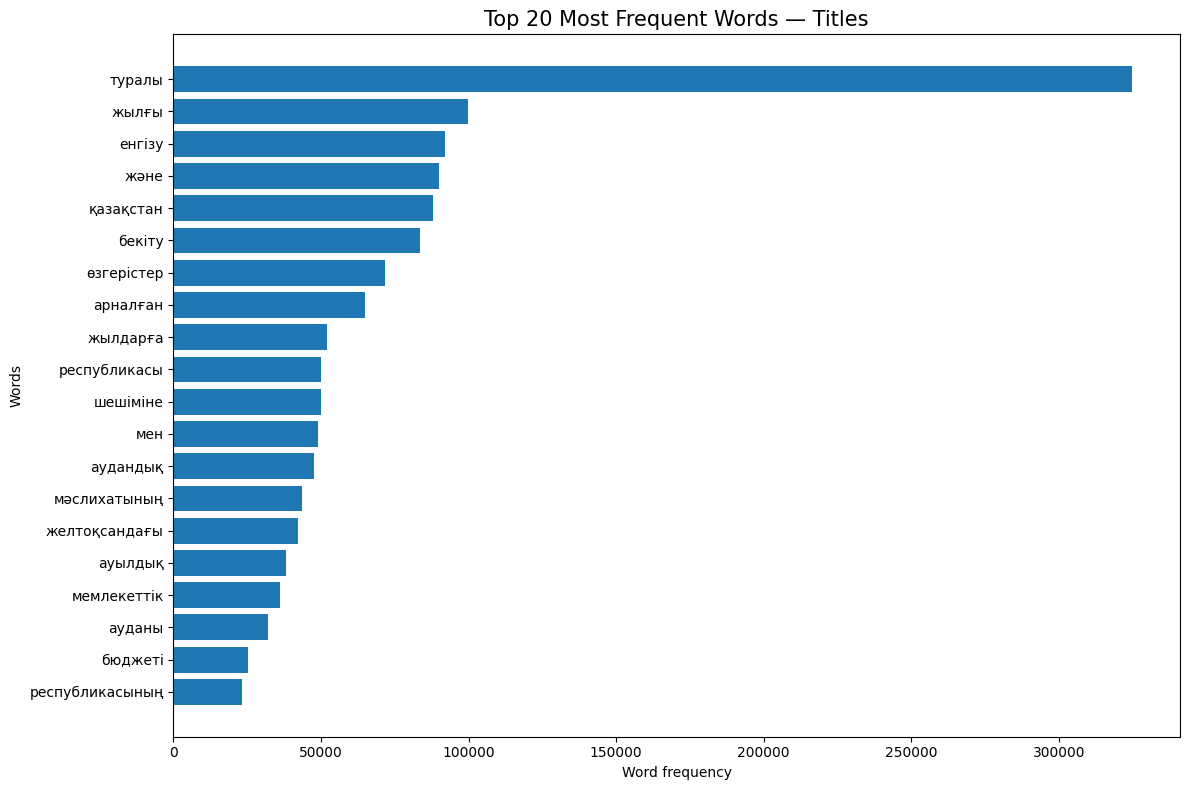

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/top20_title_words.png


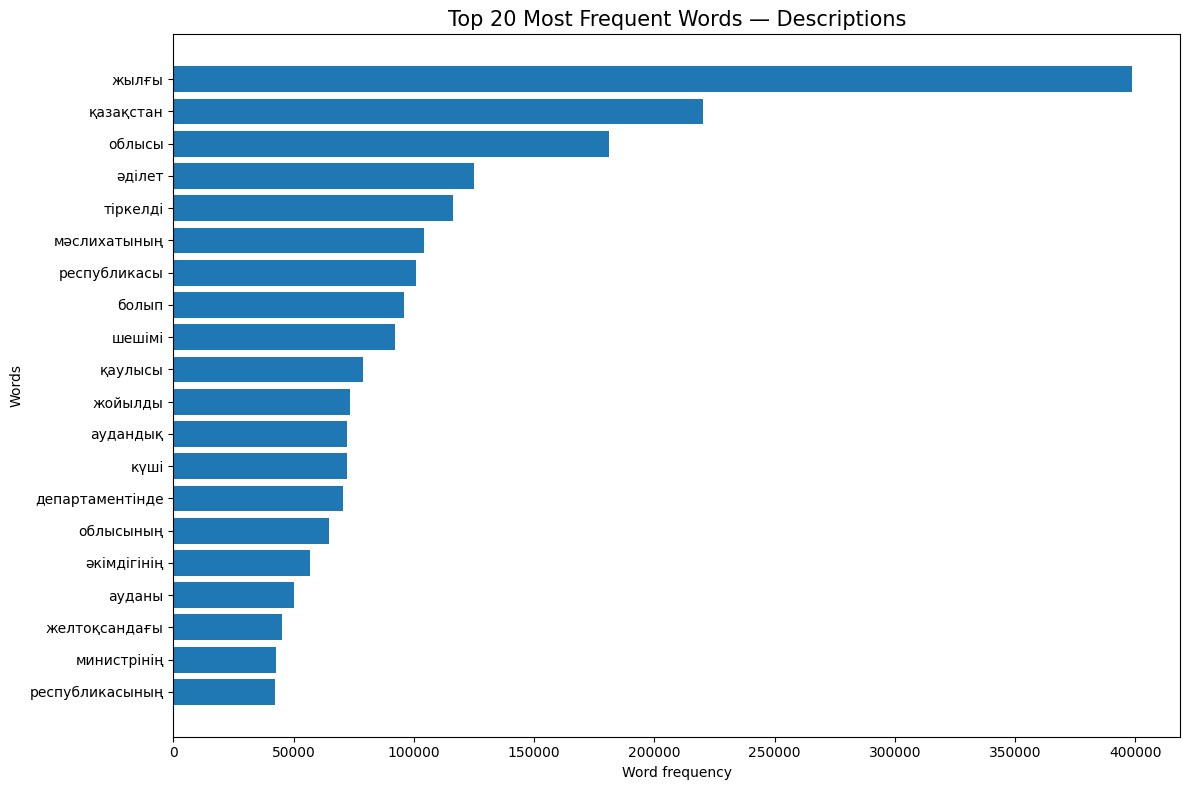

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/top20_description_words.png


In [51]:
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/outputs/figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_top_words(counter, title, filename, top_n=20):

    top_words = counter.most_common(top_n)

    words = [word for word, count in top_words][::-1]
    counts = [count for word, count in top_words][::-1]

    plt.figure(figsize=(12, 8))

    plt.barh(words, counts)

    plt.title(title, fontsize=15)
    plt.xlabel("Word frequency")
    plt.ylabel("Words")

    plt.tight_layout()

    save_path = OUTPUT_DIR / filename

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)


plot_top_words(
    title_counter,
    "Top 20 Most Frequent Words — Titles",
    "top20_title_words.png"
)

plot_top_words(
    description_counter,
    "Top 20 Most Frequent Words — Descriptions",
    "top20_description_words.png"
)

## 5. Stopwords


In [52]:
from collections import Counter

kazakh_stopwords = {
    "және", "мен", "бен", "пен",
    "туралы", "үшін", "бойынша",
    "да", "де", "та", "те",
    "ғана", "әрі", "немесе",
    "осы", "сол", "бұл", "бір",
    "ретінде", "арқылы"
}

nlp_df["title_tokens_filtered"] = (
    nlp_df["title_tokens"].apply(
        lambda tokens: [
            word for word in tokens
            if word not in kazakh_stopwords
        ]
    )
)

nlp_df["description_tokens_filtered"] = (
    nlp_df["description_tokens"].apply(
        lambda tokens: [
            word for word in tokens
            if word not in kazakh_stopwords
        ]
    )
)

title_filtered_counter = Counter(
    word
    for tokens in nlp_df["title_tokens_filtered"]
    for word in tokens
)

description_filtered_counter = Counter(
    word
    for tokens in nlp_df["description_tokens_filtered"]
    for word in tokens
)

print("=" * 65)
print("STOPWORD ANALYSIS RESULTS")
print("=" * 65)

for name, original, filtered in [
    ("TITLE", title_counter, title_filtered_counter),
    ("DESCRIPTION", description_counter,
     description_filtered_counter)
]:

    original_tokens = sum(original.values())
    filtered_tokens = sum(filtered.values())

    removed = original_tokens - filtered_tokens

    print(f"\n{name}")
    print("Original tokens:", original_tokens)
    print("Filtered tokens:", filtered_tokens)
    print("Removed tokens:", removed)
    print(
        "Removed percentage:",
        round(removed / original_tokens * 100, 2),
        "%"
    )

    print("Original vocabulary:", len(original))
    print("Filtered vocabulary:", len(filtered))

    print("\nTop 20 filtered words:")
    print(filtered.most_common(20))

print("\nSTOPWORD ANALYSIS COMPLETED")

STOPWORD ANALYSIS RESULTS

TITLE
Original tokens: 3965957
Filtered tokens: 3452117
Removed tokens: 513840
Removed percentage: 12.96 %
Original vocabulary: 34361
Filtered vocabulary: 34341

Top 20 filtered words:
[('жылғы', 99959), ('енгізу', 92170), ('қазақстан', 88012), ('бекіту', 83459), ('өзгерістер', 71554), ('арналған', 64971), ('жылдарға', 51984), ('республикасы', 50044), ('шешіміне', 49950), ('аудандық', 47643), ('мәслихатының', 43617), ('желтоқсандағы', 42310), ('ауылдық', 38139), ('мемлекеттік', 36071), ('ауданы', 31978), ('бюджеті', 25261), ('республикасының', 23328), ('ауданының', 22482), ('облысы', 21378), ('беру', 21284)]

DESCRIPTION
Original tokens: 3681040
Filtered tokens: 3655075
Removed tokens: 25965
Removed percentage: 0.71 %
Original vocabulary: 4476
Filtered vocabulary: 4462

Top 20 filtered words:
[('жылғы', 398631), ('қазақстан', 220377), ('облысы', 181332), ('әділет', 124970), ('тіркелді', 116292), ('мәслихатының', 104267), ('республикасы', 101009), ('болып', 95

## 6. Zipf's law

This section investigates word-frequency distributions using log-log regression. Both full-range and mid-rank fits are compared.



TITLES
Total unique tokens: 34361
Tokens used in regression: 22923
Zipf exponent (alpha): 1.6855
R-squared: 0.9786
Regression slope: -1.6855


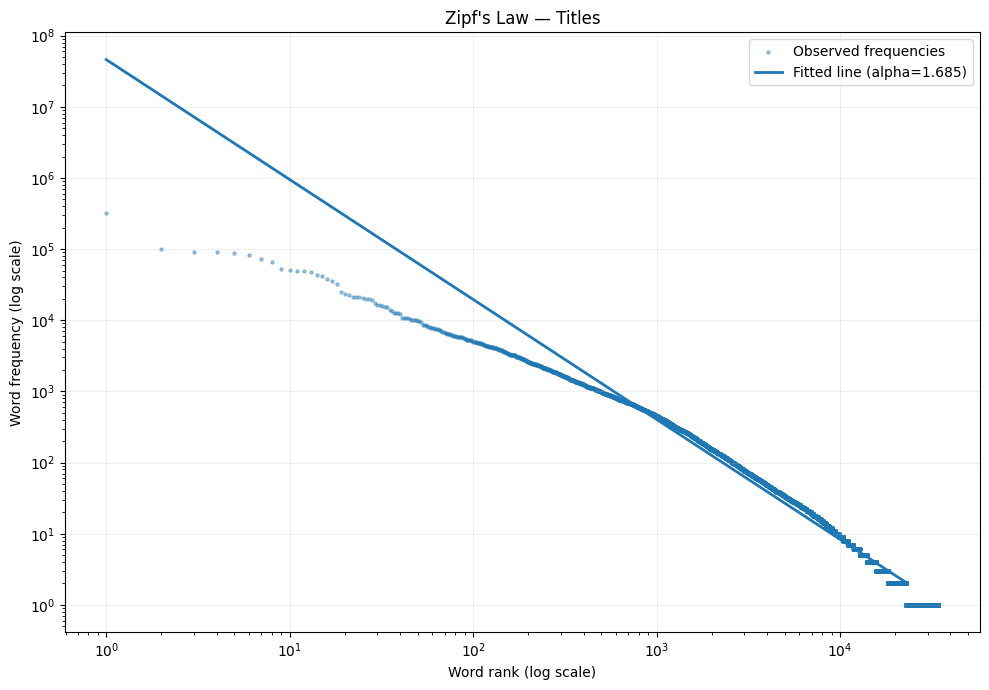

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/zipf_titles.png

DESCRIPTIONS
Total unique tokens: 4476
Tokens used in regression: 3015
Zipf exponent (alpha): 2.3406
R-squared: 0.9617
Regression slope: -2.3406


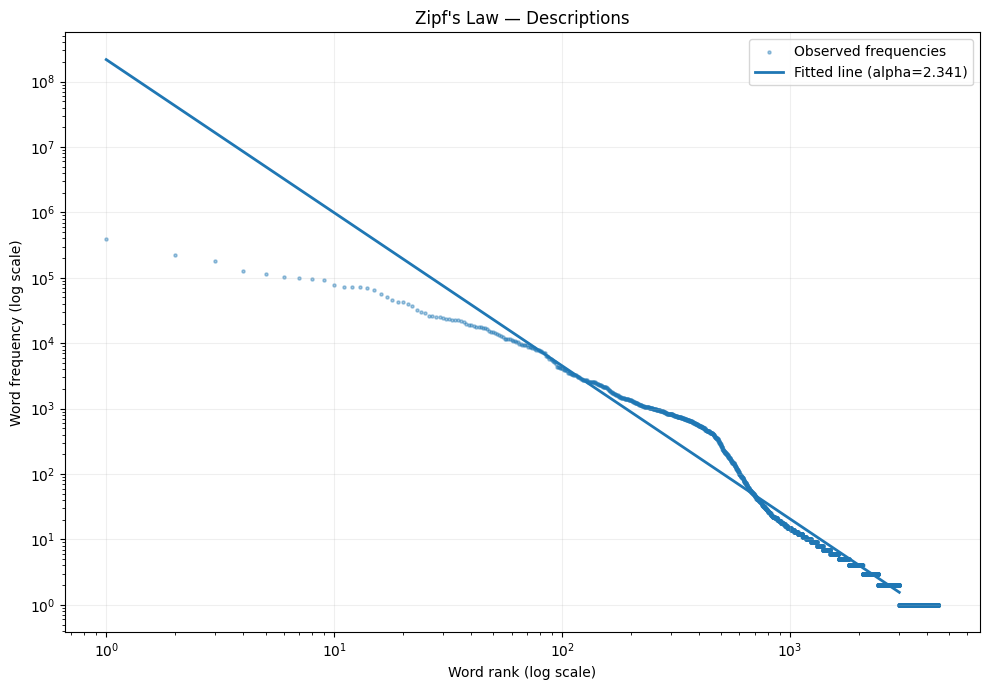

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/zipf_descriptions.png

ZIPF'S LAW COMPARISON


,corpus,alpha,r_squared,vocabulary_size,regression_words
0,Titles,1.685462,0.978605,34361,22923
1,Descriptions,2.340591,0.961689,4476,3015



ZIPF ANALYSIS COMPLETED


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/outputs/figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def analyze_zipf(counter, corpus_name, filename):

    frequencies = np.array(
        sorted(counter.values(), reverse=True),
        dtype=float
    )

    ranks = np.arange(1, len(frequencies) + 1)

    mask = frequencies >= 2

    log_ranks = np.log10(ranks[mask])
    log_frequencies = np.log10(frequencies[mask])

    slope, intercept, r_value, p_value, std_err = (
        linregress(log_ranks, log_frequencies)
    )

    alpha = -slope
    r_squared = r_value ** 2

    print(f"\n{corpus_name.upper()}")
    print("=" * 55)
    print("Total unique tokens:", len(frequencies))
    print("Tokens used in regression:", mask.sum())
    print("Zipf exponent (alpha):", round(alpha, 4))
    print("R-squared:", round(r_squared, 4))
    print("Regression slope:", round(slope, 4))

    plt.figure(figsize=(10, 7))

    plt.scatter(
        ranks,
        frequencies,
        s=5,
        alpha=0.4,
        label="Observed frequencies"
    )

    predicted = 10 ** (
        intercept + slope * np.log10(ranks[mask])
    )

    plt.plot(
        ranks[mask],
        predicted,
        linewidth=2,
        label=f"Fitted line (alpha={alpha:.3f})"
    )

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel("Word rank (log scale)")
    plt.ylabel("Word frequency (log scale)")
    plt.title(f"Zipf's Law — {corpus_name}")
    plt.legend()
    plt.grid(alpha=0.2)

    plt.tight_layout()

    save_path = OUTPUT_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", save_path)

    return {
        "corpus": corpus_name,
        "alpha": alpha,
        "r_squared": r_squared,
        "vocabulary_size": len(frequencies),
        "regression_words": int(mask.sum())
    }


zipf_title = analyze_zipf(
    title_counter,
    "Titles",
    "zipf_titles.png"
)

zipf_description = analyze_zipf(
    description_counter,
    "Descriptions",
    "zipf_descriptions.png"
)

zipf_results = pd.DataFrame(
    [zipf_title, zipf_description]
)

print("\n" + "=" * 65)
print("ZIPF'S LAW COMPARISON")
print("=" * 65)

display(zipf_results)

print("\nZIPF ANALYSIS COMPLETED")

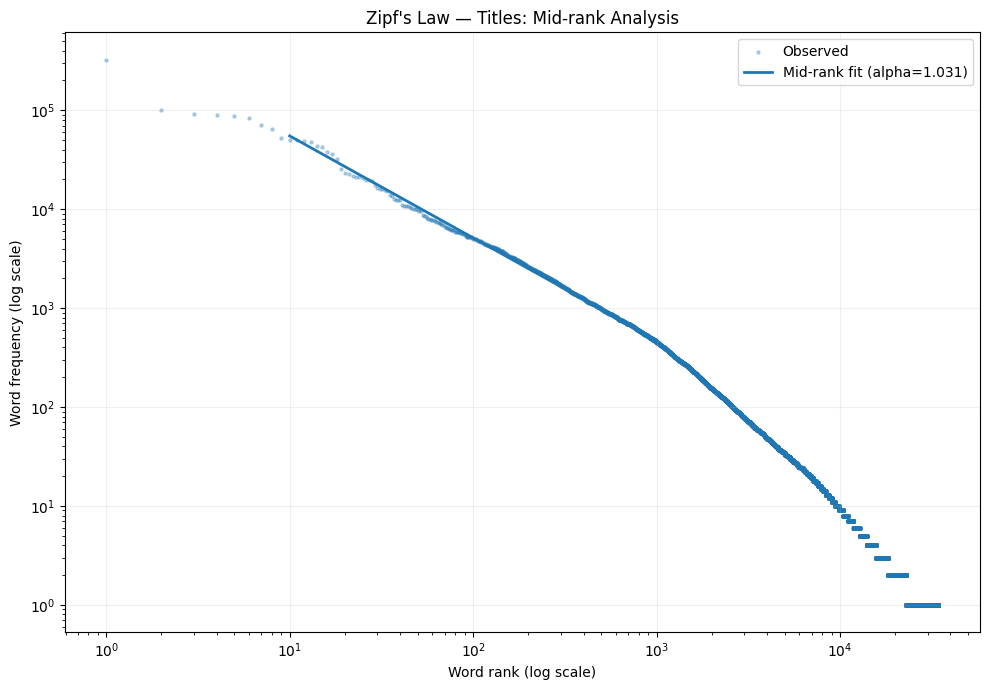

Titles | Full range: alpha=1.6855, R²=0.9786, words=22923
Titles | Ranks 10-1000: alpha=1.0308, R²=0.9983, words=991


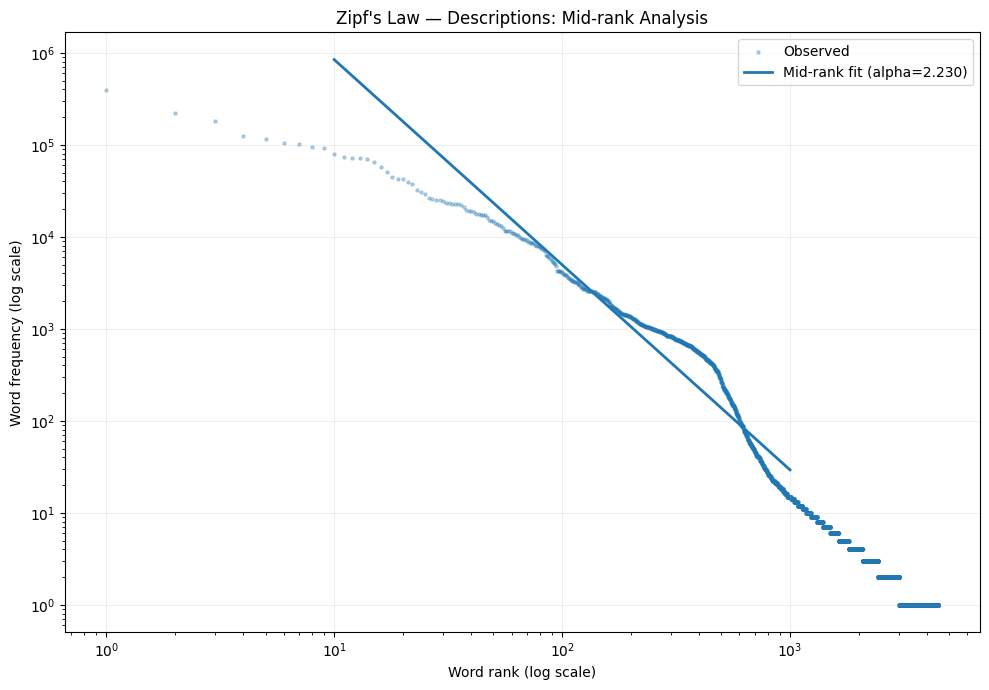

Descriptions | Full range: alpha=2.3406, R²=0.9617, words=3015
Descriptions | Ranks 10-1000: alpha=2.2298, R²=0.9162, words=991

MID-RANK ZIPF COMPARISON COMPLETED


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

def compare_zipf_ranges(counter, name):

    frequencies = np.array(
        sorted(counter.values(), reverse=True),
        dtype=float
    )

    ranks = np.arange(1, len(frequencies) + 1)

    full_mask = frequencies >= 2

    mid_mask = (
        (ranks >= 10) &
        (ranks <= 1000) &
        (frequencies >= 2)
    )

    results = {}

    for label, mask in [
        ("Full range", full_mask),
        ("Ranks 10-1000", mid_mask)
    ]:

        x = np.log10(ranks[mask])
        y = np.log10(frequencies[mask])

        slope, intercept, r_value, _, _ = linregress(x, y)

        results[label] = {
            "alpha": -slope,
            "r_squared": r_value ** 2,
            "n_words": int(mask.sum()),
            "intercept": intercept,
            "mask": mask
        }

    plt.figure(figsize=(10, 7))

    plt.scatter(
        ranks,
        frequencies,
        s=5,
        alpha=0.3,
        label="Observed"
    )

    mid = results["Ranks 10-1000"]
    mask = mid["mask"]

    predicted = 10 ** (
        mid["intercept"]
        - mid["alpha"] * np.log10(ranks[mask])
    )

    plt.plot(
        ranks[mask],
        predicted,
        linewidth=2,
        label=f"Mid-rank fit (alpha={mid['alpha']:.3f})"
    )

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel("Word rank (log scale)")
    plt.ylabel("Word frequency (log scale)")
    plt.title(f"Zipf's Law — {name}: Mid-rank Analysis")

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    for label, result in results.items():
        print(
            f"{name} | {label}: "
            f"alpha={result['alpha']:.4f}, "
            f"R²={result['r_squared']:.4f}, "
            f"words={result['n_words']}"
        )

    return results


title_zipf_comparison = compare_zipf_ranges(
    title_counter, "Titles"
)

description_zipf_comparison = compare_zipf_ranges(
    description_counter, "Descriptions"
)

print("\nMID-RANK ZIPF COMPARISON COMPLETED")


In [55]:
import sys
import platform
import importlib.util
import subprocess

print("=" * 60)
print("KAZAKH STEMMING ENVIRONMENT CHECK")
print("=" * 60)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

packages = [
    "nltk",
    "snowballstemmer",
    "qazmorph",
    "turkicnlp"
]

print("\nAVAILABLE PACKAGES")

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'INSTALLED' if installed else 'NOT INSTALLED'}")

print("\nEXISTING VOCABULARY")
print("Title unique tokens:", len(title_counter))
print("Description unique tokens:", len(description_counter))

print("\nENVIRONMENT CHECK COMPLETED")

KAZAKH STEMMING ENVIRONMENT CHECK
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

AVAILABLE PACKAGES
nltk: INSTALLED
snowballstemmer: INSTALLED
qazmorph: INSTALLED
turkicnlp: NOT INSTALLED

EXISTING VOCABULARY
Title unique tokens: 34361
Description unique tokens: 4476

ENVIRONMENT CHECK COMPLETED


## 7. KazStem setup


In [56]:
import json
import os
import subprocess
import pandas as pd

print("=" * 65)
print("KAZSTEM — LEMMA AMBIGUITY ANALYSIS")
print("=" * 65)

sample_words = [
    word for word, count
    in title_counter.most_common(100)
]

env = os.environ.copy()
env["QAZMORPH_RESOURCE_DIR"] = str(resource_dir)

result = subprocess.run(
    [
        "kazstem",
        "--resource-dir",
        str(resource_dir),
        "--format", "json",
        "-"
    ],
    input="\n".join(sample_words) + "\n",
    capture_output=True,
    text=True,
    env=env,
    timeout=120
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

data = json.loads(result.stdout)

records = []

for item in data:

    word = item.get("text", "")

    analyses = item.get("analysis", [])

    lemmas = sorted({
        analysis.get("lex")
        for analysis in analyses
        if analysis.get("lex")
    })

    records.append({
        "word": word,
        "frequency": title_counter.get(word, 0),
        "number_of_lemmas": len(lemmas),
        "possible_lemmas": ", ".join(lemmas)
    })

ambiguity_df = pd.DataFrame(records)

print("\nTOTAL WORDS:", len(ambiguity_df))

print(
    "WORDS WITH ONE LEMMA:",
    (ambiguity_df["number_of_lemmas"] == 1).sum()
)

print(
    "WORDS WITH MULTIPLE LEMMAS:",
    (ambiguity_df["number_of_lemmas"] > 1).sum()
)

print(
    "WORDS WITHOUT LEMMAS:",
    (ambiguity_df["number_of_lemmas"] == 0).sum()
)

print("\nAMBIGUOUS WORDS:")
display(
    ambiguity_df[
        ambiguity_df["number_of_lemmas"] > 1
    ].sort_values(
        "frequency",
        ascending=False
    ).head(30)
)

print("\nLEMMA AMBIGUITY ANALYSIS COMPLETED")

KAZSTEM — LEMMA AMBIGUITY ANALYSIS

TOTAL WORDS: 100
WORDS WITH ONE LEMMA: 74
WORDS WITH MULTIPLE LEMMAS: 26
WORDS WITHOUT LEMMAS: 0

AMBIGUOUS WORDS:


,word,frequency,number_of_lemmas,possible_lemmas
0,туралы,324798,2,"тура, туралы"
4,қазақстан,88012,2,"қазақс, қазақст"
5,бекіту,83459,2,"бекіт, бекіту"
7,арналған,64971,2,"арна, арналған"
25,бойынша,19792,2,"бой, бойынша"
26,толықтырулар,19597,2,"толықтыр, толықтыру"
28,үшін,17527,2,"үш, үшін"
31,белгілеу,15983,2,"белгіле, белгілеу"
32,өзгеріс,15590,2,"өзгер, өзгеріс"
41,тану,10832,2,"тан, таны"



LEMMA AMBIGUITY ANALYSIS COMPLETED


In [57]:
import json
import os
import subprocess
import pandas as pd

print("=" * 65)
print("CONSERVATIVE LEMMATIZATION — PILOT TEST")
print("=" * 65)

sample_words = [
    word for word, count
    in title_counter.most_common(100)
]

env = os.environ.copy()
env["QAZMORPH_RESOURCE_DIR"] = str(resource_dir)

result = subprocess.run(
    [
        "kazstem",
        "--resource-dir",
        str(resource_dir),
        "--no-guesser",
        "--format", "json",
        "-"
    ],
    input="\n".join(sample_words) + "\n",
    capture_output=True,
    text=True,
    env=env,
    timeout=120
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

data = json.loads(result.stdout)

records = []

for item in data:

    word = item.get("text", "")

    lemmas = sorted({
        analysis.get("lex")
        for analysis in item.get("analysis", [])
        if analysis.get("lex")
    })

    if len(lemmas) == 1:
        selected_lemma = lemmas[0]
        status = "unique_lemma"

    elif len(lemmas) > 1:
        selected_lemma = word
        status = "ambiguous_kept_original"

    else:
        selected_lemma = word
        status = "unknown_kept_original"

    records.append({
        "word": word,
        "frequency": title_counter.get(word, 0),
        "selected_lemma": selected_lemma,
        "status": status,
        "possible_lemmas": ", ".join(lemmas)
    })

pilot_df = pd.DataFrame(records)

print("\nSTATUS DISTRIBUTION")
print(pilot_df["status"].value_counts())

print("\nVOCABULARY COMPARISON")
print("Original unique words:", pilot_df["word"].nunique())
print("Unique selected lemmas:", pilot_df["selected_lemma"].nunique())

reduction = (
    1 -
    pilot_df["selected_lemma"].nunique()
    / pilot_df["word"].nunique()
) * 100

print("Vocabulary reduction:", round(reduction, 2), "%")

print("\nEXAMPLES OF NORMALIZATION")

display(
    pilot_df[
        pilot_df["word"] != pilot_df["selected_lemma"]
    ].head(25)
)

print("\nCONSERVATIVE LEMMATIZATION PILOT COMPLETED")

CONSERVATIVE LEMMATIZATION — PILOT TEST

STATUS DISTRIBUTION
status
unique_lemma               75
ambiguous_kept_original    25
Name: count, dtype: int64

VOCABULARY COMPARISON
Original unique words: 100
Unique selected lemmas: 93
Vocabulary reduction: 7.0 %

EXAMPLES OF NORMALIZATION


,word,frequency,selected_lemma,status,possible_lemmas
2,енгізу,92170,енгіз,unique_lemma,енгіз
6,өзгерістер,71554,өзгеріс,unique_lemma,өзгеріс
8,жылдарға,51984,жыл,unique_lemma,жыл
9,республикасы,50044,республика,unique_lemma,республика
10,шешіміне,49950,шешім,unique_lemma,шешім
13,мәслихатының,43617,мәслихат,unique_lemma,мәслихат
14,желтоқсандағы,42310,желтоқсан,unique_lemma,желтоқсан
17,ауданы,31978,аудан,unique_lemma,аудан
18,бюджеті,25261,бюджет,unique_lemma,бюджет
19,республикасының,23328,республика,unique_lemma,республика



CONSERVATIVE LEMMATIZATION PILOT COMPLETED


## 8. Morphological normalization


In [58]:
import json
import os
import subprocess
import pandas as pd
from pathlib import Path

print("=" * 65)
print("FULL VOCABULARY LEMMATIZATION")
print("=" * 65)

all_unique_words = sorted(
    set(title_counter) | set(description_counter)
)

print("Unique words across both fields:", len(all_unique_words))

env = os.environ.copy()
env["QAZMORPH_RESOURCE_DIR"] = str(resource_dir)

batch_size = 1000
records = []

for start in range(0, len(all_unique_words), batch_size):

    batch = all_unique_words[start:start + batch_size]

    result = subprocess.run(
        [
            "kazstem",
            "--resource-dir",
            str(resource_dir),
            "--no-guesser",
            "--format",
            "json",
            "-"
        ],
        input="\n".join(batch) + "\n",
        capture_output=True,
        text=True,
        env=env,
        timeout=180
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"Batch {start} failed:\n{result.stderr[:2000]}"
        )

    data = json.loads(result.stdout)

    if len(data) != len(batch):
        raise ValueError(
            f"Batch {start}: Expected {len(batch)} "
            f"items, received {len(data)}"
        )

    for word, item in zip(batch, data):

        if item.get("text") != word:
            raise ValueError(
                f"Word mismatch: {word} != {item.get('text')}"
            )

        lemmas = sorted({
            analysis["lex"]
            for analysis in item.get("analysis", [])
            if analysis.get("lex")
        })

        if len(lemmas) == 1:
            lemma = lemmas[0]
            status = "unique_lemma"

        elif len(lemmas) > 1:
            lemma = word
            status = "ambiguous_kept_original"

        else:
            lemma = word
            status = "unknown_kept_original"

        records.append({
            "word": word,
            "lemma": lemma,
            "status": status,
            "number_of_lemmas": len(lemmas),
            "possible_lemmas": ", ".join(lemmas)
        })

    print(
        f"Processed {min(start + batch_size, len(all_unique_words))}"
        f"/{len(all_unique_words)} unique words"
    )

lemma_df = pd.DataFrame(records)

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "kazstem_lemma_mapping.parquet"

lemma_df.to_parquet(output_path, index=False)

print("\n" + "=" * 65)
print("LEMMATIZATION RESULTS")
print("=" * 65)

print("Total words processed:", len(lemma_df))
print("Unique normalized forms:", lemma_df["lemma"].nunique())

print("\nSTATUS DISTRIBUTION")
print(lemma_df["status"].value_counts())

print("\nSaved:", output_path)

print("\nFULL VOCABULARY LEMMATIZATION COMPLETED")

FULL VOCABULARY LEMMATIZATION
Unique words across both fields: 35523
Processed 1000/35523 unique words
Processed 2000/35523 unique words
Processed 3000/35523 unique words
Processed 4000/35523 unique words
Processed 5000/35523 unique words
Processed 6000/35523 unique words
Processed 7000/35523 unique words
Processed 8000/35523 unique words
Processed 9000/35523 unique words
Processed 10000/35523 unique words
Processed 11000/35523 unique words
Processed 12000/35523 unique words
Processed 13000/35523 unique words
Processed 14000/35523 unique words
Processed 15000/35523 unique words
Processed 16000/35523 unique words
Processed 17000/35523 unique words
Processed 18000/35523 unique words
Processed 19000/35523 unique words
Processed 20000/35523 unique words
Processed 21000/35523 unique words
Processed 22000/35523 unique words
Processed 23000/35523 unique words
Processed 24000/35523 unique words
Processed 25000/35523 unique words
Processed 26000/35523 unique words
Processed 27000/35523 unique w

VOCABULARY REDUCTION — TITLES VS DESCRIPTIONS

VOCABULARY COMPARISON


,Corpus,Original Vocabulary,Lemmatized Vocabulary,Reduction (%)
0,Titles,34361,22944,33.23
1,Descriptions,4476,3912,12.60
2,Combined,35523,23967,32.53


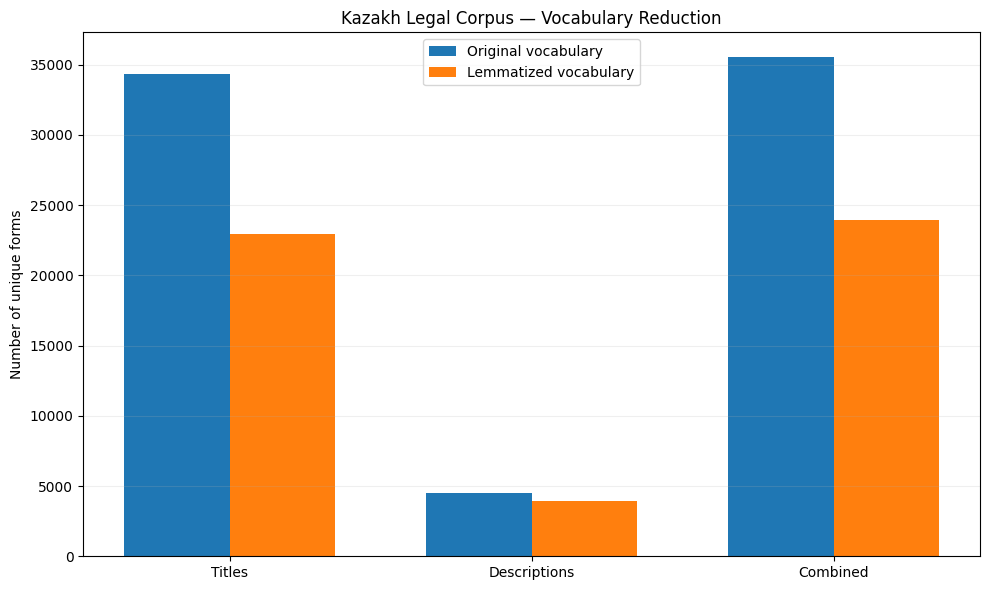


Saved figure: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/vocabulary_reduction.png

VOCABULARY REDUCTION COMPARISON COMPLETED


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 65)
print("VOCABULARY REDUCTION — TITLES VS DESCRIPTIONS")
print("=" * 65)

mapping_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_df = pd.read_parquet(mapping_path)

lemma_map = dict(
    zip(lemma_df["word"], lemma_df["lemma"])
)

def calculate_reduction(counter, corpus_name):

    original_words = set(counter.keys())

    missing = original_words - set(lemma_map)

    if missing:
        raise ValueError(
            f"{corpus_name}: {len(missing)} words missing"
        )

    normalized_words = {
        lemma_map[word]
        for word in original_words
    }

    original_size = len(original_words)
    normalized_size = len(normalized_words)

    reduction = (
        (original_size - normalized_size)
        / original_size * 100
    )

    return {
        "Corpus": corpus_name,
        "Original Vocabulary": original_size,
        "Lemmatized Vocabulary": normalized_size,
        "Reduction (%)": round(reduction, 2)
    }


results = [
    calculate_reduction(title_counter, "Titles"),
    calculate_reduction(description_counter, "Descriptions"),
    calculate_reduction(
        dict.fromkeys(
            set(title_counter) | set(description_counter)
        ),
        "Combined"
    )
]

vocabulary_comparison_df = pd.DataFrame(results)

print("\nVOCABULARY COMPARISON")
display(vocabulary_comparison_df)

fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(vocabulary_comparison_df))
bar_width = 0.35

original = vocabulary_comparison_df[
    "Original Vocabulary"
]

lemmatized = vocabulary_comparison_df[
    "Lemmatized Vocabulary"
]

ax.bar(
    [i - bar_width / 2 for i in x],
    original,
    width=bar_width,
    label="Original vocabulary"
)

ax.bar(
    [i + bar_width / 2 for i in x],
    lemmatized,
    width=bar_width,
    label="Lemmatized vocabulary"
)

ax.set_xticks(list(x))
ax.set_xticklabels(
    vocabulary_comparison_df["Corpus"]
)

ax.set_ylabel("Number of unique forms")
ax.set_title(
    "Kazakh Legal Corpus — Vocabulary Reduction"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/outputs/figures"
)

output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "vocabulary_reduction.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:", figure_path)
print("\nVOCABULARY REDUCTION COMPARISON COMPLETED")

In [60]:
import pandas as pd
from pathlib import Path

print("=" * 65)
print("LEMMATIZATION QUALITY AUDIT")
print("=" * 65)

mapping_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_df = pd.read_parquet(mapping_path)

changed_df = lemma_df[
    lemma_df["word"] != lemma_df["lemma"]
].copy()

print("Total changed word forms:", len(changed_df))

audit_sample = changed_df.sample(
    n=min(50, len(changed_df)),
    random_state=42
).copy()

audit_sample["title_frequency"] = (
    audit_sample["word"]
    .map(title_counter)
    .fillna(0)
    .astype(int)
)

audit_sample["description_frequency"] = (
    audit_sample["word"]
    .map(description_counter)
    .fillna(0)
    .astype(int)
)

audit_sample["manual_correct"] = pd.NA
audit_sample["correct_lemma"] = pd.NA
audit_sample["notes"] = pd.NA

audit_sample = audit_sample[
    [
        "word",
        "lemma",
        "title_frequency",
        "description_frequency",
        "status",
        "manual_correct",
        "correct_lemma",
        "notes"
    ]
]

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

audit_path = output_dir / "lemma_quality_audit_50.csv"

audit_sample.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nAUDIT SAMPLE")
display(audit_sample)

print("\nSaved:", audit_path)
print("Sample size:", len(audit_sample))
print("\nLEMMATIZATION QUALITY AUDIT SAMPLE CREATED")

LEMMATIZATION QUALITY AUDIT
Total changed word forms: 12894

AUDIT SAMPLE


,word,lemma,title_frequency,description_frequency,status,manual_correct,correct_lemma,notes
14056,курсынан,курс,3,0,unique_lemma,<NA>,<NA>,<NA>
12836,кешендердің,кешен,24,0,unique_lemma,<NA>,<NA>,<NA>
43,абоненттер,абонент,6,0,unique_lemma,<NA>,<NA>,<NA>
10087,жылдарында,жыл,4,0,unique_lemma,<NA>,<NA>,<NA>
1826,аспаптарын,аспап,25,0,unique_lemma,<NA>,<NA>,<NA>
16539,мерзімнен,мерзім,2,0,unique_lemma,<NA>,<NA>,<NA>
13028,киімнің,киім,13,0,unique_lemma,<NA>,<NA>,<NA>
26495,тізілімін,тізілім,548,0,unique_lemma,<NA>,<NA>,<NA>
6603,даңғылында,даңғыл,1,0,unique_lemma,<NA>,<NA>,<NA>
27625,уланулар,улану,2,0,unique_lemma,<NA>,<NA>,<NA>



Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/lemma_quality_audit_50.csv
Sample size: 50

LEMMATIZATION QUALITY AUDIT SAMPLE CREATED


In [61]:
import pandas as pd
import re
from pathlib import Path

print("=" * 65)
print("CONTEXTUAL LEMMA QUALITY AUDIT")
print("=" * 65)

audit_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/lemma_quality_audit_50.csv"
)

audit_df = pd.read_csv(audit_path)

target_words = set(audit_df["word"])

contexts = {}
source_fields = {}

pattern = re.compile(
    r"(?<![а-яёәғқңөұүһі])("
    + "|".join(
        re.escape(word)
        for word in sorted(target_words, key=len, reverse=True)
    )
    + r")(?![а-яёәғқңөұүһі])",
    re.IGNORECASE
)

for row in nlp_df[["title", "description"]].itertuples(index=False):

    for field, value in [
        ("title", row.title),
        ("description", row.description)
    ]:

        if not isinstance(value, str):
            continue

        for match in pattern.finditer(value):

            word = match.group().lower()

            if word not in contexts:
                contexts[word] = value
                source_fields[word] = field

    if len(contexts) == len(target_words):
        break

audit_df["context"] = audit_df["word"].map(contexts)
audit_df["source_field"] = audit_df["word"].map(source_fields)

output_path = audit_path.with_name(
    "lemma_quality_audit_50_with_context.csv"
)

audit_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nTOTAL AUDIT WORDS:", len(audit_df))
print("WORDS WITH CONTEXT:", audit_df["context"].notna().sum())

print("\nCONTEXTUAL AUDIT SAMPLE")

display(
    audit_df[
        ["word", "lemma", "source_field", "context"]
    ].head(15)
)

print("\nSaved:", output_path)
print("\nCONTEXTUAL AUDIT PREPARATION COMPLETED")

CONTEXTUAL LEMMA QUALITY AUDIT

TOTAL AUDIT WORDS: 50
WORDS WITH CONTEXT: 50

CONTEXTUAL AUDIT SAMPLE


,word,lemma,source_field,context
0,курсынан,курс,title,"Стационарлық емдеу-алдын алу, оңалту және басқа денсаулық сақтау ұйымдарында емдеу курсынан өтіп жатқан мүгедек балалар үшін оқу сабақтарын ұйымдастыру, оқу-тәрбие ұйымдарының мүгедек балаларды үйде оқытуда ата-аналарға көмек көрсету тәртібі туралы ережелерді бекіту туралы"
1,кешендердің,кешен,title,Салынып жатқан (салынуы белгіленген) объектілер мен кешендердің мониторингін жүргізу қағидаларын бекіту туралы
2,абоненттер,абонент,title,"""Жедел-іздестіру іс-шараларын өткізуді, абоненттер туралы қызметтік ақпараттарды жинауды және сақтауды қамтамасыз ету бойынша телекоммуникациялық жабдықтарға қойылатын жалпы талаптар"" техникалық регламентін бекіту туралы"" Қазақстан Республикасы Ұлттық қауіпсіздік комитеті Төрағасының 2021 жылғы 27 шiлдедегі № 85/қе бұйрығына өзгерістер енгізу туралы"
3,жылдарында,жыл,title,"1941-1945 жылдары Ұлы Отан соғысына қатысушылар және мүгедектер, 1941-1945 жылы Ұлы Отан соғысы жылдарында Кеңес Армиясының қатарына шақырылған бұрынғы әскери қызметкерлер және ішкі істер органдарының қызметкерлері ""1941-1945 Ұлы Отан соғысы жылдарында Германияны жеңгені үшін"" медалімен марапатталғандар, Ұлы Отан соғысында қаза болған жауынгерлердің \r\nжесірлерінің коммуналдық қызметтері (жылу, су, көгілдір отын, электрмен қамту) және байланыс қызметтері үшін (абоненттік төлемақы) жеңілдіктер беру туралы"
4,аспаптарын,аспап,title,"""Уәкілетті органға мұнай өнімдерін өткізу мен өндірудің көлемдері туралы ақпаратты автоматты түрде беруді қамтамасыз ететін бақылаушы есептеу аспаптарын қолдану ережелерін бекіту туралы"" Қазақстан Республикасы Индустрия және сауда министрінің 2003 жылғы 17 қыркүйектегі № 277 бұйрығының күші жойылды деп тану туралы"
5,мерзімнен,мерзім,title,Жазаны өтеуден мерзімнен бұрын шартты түрде босату және жазаның өтелмеген бөлігін неғұрлым жеңіл жаза түріне ауыстыру туралы
6,киімнің,киім,title,"""Нысанды киімнің үлгілерін, нысанды киім киюге құқығы бар мемлекеттік кірістер органдары жұмыскерлерінің тізбесін, онымен қамтамасыз етудің заттай нормаларын және айырым белгілерін, сондай-ақ оны тағып жүру қағидаларын бекіту туралы"" Қазақстан Республикасы Қаржы министрінің 2018 жылғы 12 ақпандағы № 168 бұйрығына өзгерістер енгізу туралы"
7,тізілімін,тізілім,title,"""Үкіметтік сыртқы қарыздар, байланысты гранттар қаражаттары мен республикалық бюджеттен қоса қаржыландыру қаражаттары есебінен қаржыландырылатын инвестициялық жобаларды басқару мәселелері бойынша жергілікті консультанттардың лауазымдар тізілімін және лауазымдық коэффициенттерінің кестесін бекіту туралы"" Қазақстан Республикасы Қаржы министрінің 2005 жылғы 7 қазандағы N 359 бұйрығының күші жойылды деп тану туралы"
8,даңғылында,даңғыл,title,"""Атырау облысы Атырау қаласы Сәтпаев даңғылында әкімшілік ғимарат салу"" аяқталмаған құрылыс объектісін республикалық меншіктен Атырау облысының коммуналдық меншігіне беру туралы"
9,уланулар,улану,title,"Инфекциялық, паразиттік, кәсіптік аурулар мен уланулар жағдайларын тіркеу, есепке алуды жүргізу қағидаларын және олар бойынша есептілікті жүргізу қағидаларын бекіту туралы"



Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/lemma_quality_audit_50_with_context.csv

CONTEXTUAL AUDIT PREPARATION COMPLETED


In [62]:
import pandas as pd
import re

print("=" * 65)
print("REMAINING 35 LEMMA AUDIT EXAMPLES")
print("=" * 65)

remaining_audit = audit_df.iloc[15:].copy()

def extract_context_snippet(row, window=65):
    context = str(row["context"])
    word = str(row["word"])

    match = re.search(
        rf"(?<!\w){re.escape(word)}(?!\w)",
        context,
        flags=re.IGNORECASE
    )

    if not match:
        return context[:150]

    start = max(0, match.start() - window)
    end = min(len(context), match.end() + window)

    snippet = context[start:end].replace("\n", " ")

    return (
        ("..." if start > 0 else "")
        + snippet
        + ("..." if end < len(context) else "")
    )

remaining_audit["short_context"] = remaining_audit.apply(
    extract_context_snippet,
    axis=1
)

remaining_audit = remaining_audit[
    ["word", "lemma", "short_context"]
].reset_index(drop=True)

display(
    remaining_audit.style.set_properties(
        **{"text-align": "left"}
    )
)

print("\nREMAINING EXAMPLES READY FOR REVIEW")

REMAINING 35 LEMMA AUDIT EXAMPLES


,word,lemma,short_context
0,типтердегі,тип,"Тиісті типтердегі және түрлердегі мектепке дейінгі, орта, техникалық және кәсіптік..."
1,өндірісшілерінен,өндірісші,"""Ауылшаруашылық тауар өндірісшілерінен 2000 жылғы егін астығын мемлекеттік сатып алу туралы"" облыс әкім..."
2,ұясымен,ұя,"...н ұрықтандыру жөніндегі шығындарды 100%-ға дейін өтеуді, бал ара ұясымен селекциялық және асыл тұқымды жұмыстарды жүргізу субсидиялау бағ..."
3,бақтарының,бақ,"""Қазақстан Республикасының мемлекеттік хайуанаттар бақтарының жануарлармен импорттық және экспорттық операциялар жасауды және ..."
4,тасқынының,тасқын,Оңтүстік Қазақстан облысындағы су тасқынының салдарларын жою және әлеуметтік мақсаттағы объектілерді және тұр...
5,селосынан,село,"Қызылөзен ауылы әкімінің 2008 жылғы 16 маусымдағы №11 ""Қызылөзен селосынан жаңадан пайда болған көшелерге есімдер беру туралы"" шешімінің кү..."
6,депутаттың,депутат,6-сайлау округі бойынша шығып қалған депутаттың орнына ІV cайланған Алматы қаласы мәслихатының депутатын cайлау ...
7,ниетке,ниет,...рациясы арасындағы мемлекеттiк шекараны делимитациялау жөнiндегi ниетке қатысты ХАТТАМА
8,перспективалы,перспектива,Қазақстан Республикасында радиожиілік спектрді перспективалы пайдаланудың 2024-2029 жылдарға арналған жоспарын бекіту туралы
9,шешіміме,шешім,...ысы Мұғалжар аудандық мәслихатының 2010 жылғы 16 ақпандағы N 176 шешіміме



REMAINING EXAMPLES READY FOR REVIEW


## 9. N-grams


In [63]:
from collections import Counter
import pandas as pd
from pathlib import Path

print("=" * 65)
print("KAZAKH LEGAL LANGUAGE — N-GRAM ANALYSIS")
print("=" * 65)

def count_ngrams(token_series, n):

    counter = Counter()

    for tokens in token_series:

        if not isinstance(tokens, list):
            continue

        if len(tokens) < n:
            continue

        counter.update(
            tuple(tokens[i:i+n])
            for i in range(len(tokens) - n + 1)
        )

    return counter


print("\nProcessing title bigrams...")
title_bigrams = count_ngrams(
    nlp_df["title_tokens"], 2
)

print("Processing title trigrams...")
title_trigrams = count_ngrams(
    nlp_df["title_tokens"], 3
)

print("\nProcessing description bigrams...")
description_bigrams = count_ngrams(
    nlp_df["description_tokens"], 2
)

print("Processing description trigrams...")
description_trigrams = count_ngrams(
    nlp_df["description_tokens"], 3
)


def show_top_ngrams(counter, name, n=20):

    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    print("Unique n-grams:", len(counter))
    print("Total occurrences:", sum(counter.values()))

    top = pd.DataFrame(
        [
            (" ".join(ngram), frequency)
            for ngram, frequency in counter.most_common(n)
        ],
        columns=["N-gram", "Frequency"]
    )

    display(top)

    return top


title_bigram_df = show_top_ngrams(
    title_bigrams, "Top 20 Title Bigrams"
)

title_trigram_df = show_top_ngrams(
    title_trigrams, "Top 20 Title Trigrams"
)

description_bigram_df = show_top_ngrams(
    description_bigrams, "Top 20 Description Bigrams"
)

description_trigram_df = show_top_ngrams(
    description_trigrams, "Top 20 Description Trigrams"
)

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

for filename, df in [
    ("top_title_bigrams.csv", title_bigram_df),
    ("top_title_trigrams.csv", title_trigram_df),
    ("top_description_bigrams.csv", description_bigram_df),
    ("top_description_trigrams.csv", description_trigram_df)
]:
    df.to_csv(
        output_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )

print("\nN-GRAM ANALYSIS COMPLETED")

KAZAKH LEGAL LANGUAGE — N-GRAM ANALYSIS

Processing title bigrams...
Processing title trigrams...

Processing description bigrams...
Processing description trigrams...

TOP 20 TITLE BIGRAMS
Unique n-grams: 215621
Total occurrences: 3750069


,N-gram,Frequency
0,енгізу туралы,91058
1,бекіту туралы,82130
2,жылдарға арналған,51844
3,өзгерістер енгізу,51763
4,қазақстан республикасы,48945
5,шешіміне өзгерістер,43229
6,жылғы желтоқсандағы,42031
7,туралы шешіміне,38404
8,мәслихатының жылғы,38359
9,аудандық мәслихатының,30191



TOP 20 TITLE TRIGRAMS
Unique n-grams: 400443
Total occurrences: 3534187


,N-gram,Frequency
0,өзгерістер енгізу туралы,51440
1,шешіміне өзгерістер енгізу,35436
2,туралы шешіміне өзгерістер,33510
3,мәслихатының жылғы желтоқсандағы,27169
4,аудандық мәслихатының жылғы,26846
5,туралы қазақстан республикасы,22912
6,толықтырулар енгізу туралы,17102
7,қағидаларын бекіту туралы,16967
8,бекіту туралы қазақстан,15553
9,бюджеті туралы шешіміне,15019



TOP 20 DESCRIPTION BIGRAMS
Unique n-grams: 15842
Total occurrences: 3465151


,N-gram,Frequency
0,мәслихатының жылғы,102172
1,қазақстан республикасы,100882
2,болып тіркелді,90401
3,күші жойылды,72051
4,әділет департаментінде,70585
5,департаментінде жылғы,65886
6,аудандық мәслихатының,64327
7,облысының әділет,60068
8,әкімдігінің жылғы,56462
9,қазақстан облысы,54374



TOP 20 DESCRIPTION TRIGRAMS
Unique n-grams: 33033
Total occurrences: 3249281


,N-gram,Frequency
0,әділет департаментінде жылғы,65749
1,аудандық мәслихатының жылғы,63727
2,облысының әділет департаментінде,58420
3,тіркелді күші жойылды,47872
4,қазақстан республикасы үкіметінің,36832
5,болып тіркелді күші,33922
6,қазақстан республикасының әділет,33613
7,республикасының әділет министрлігінде,33441
8,республикасы үкіметінің жылғы,31322
9,әділет министрлігінде жылғы,29044



N-GRAM ANALYSIS COMPLETED


## 10. Temporal lexical analysis


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 65)
print("TEMPORAL LEXICAL ANALYSIS — CORPUS PREPARATION")
print("=" * 65)

nlp_df["date_adopted"] = pd.to_datetime(
    nlp_df["date_adopted"],
    errors="coerce"
)

nlp_df["year"] = nlp_df["date_adopted"].dt.year

nlp_df["decade"] = (
    nlp_df["year"] // 10 * 10
)

nlp_df["title_token_count"] = (
    nlp_df["title_tokens"].apply(len)
)

nlp_df["description_token_count"] = (
    nlp_df["description_tokens"].apply(len)
)

temporal_summary = (
    nlp_df.dropna(subset=["decade"])
    .groupby("decade")
    .agg(
        documents=("year", "size"),
        title_tokens=("title_token_count", "sum"),
        description_tokens=("description_token_count", "sum")
    )
    .reset_index()
)

temporal_summary["decade"] = (
    temporal_summary["decade"].astype(int)
)

temporal_summary["avg_title_tokens"] = (
    temporal_summary["title_tokens"]
    / temporal_summary["documents"]
)

temporal_summary["avg_description_tokens"] = (
    temporal_summary["description_tokens"]
    / temporal_summary["documents"]
)

print("\nTEMPORAL CORPUS SUMMARY")

display(temporal_summary)

print("\nTOTAL DOCUMENTS:",
      temporal_summary["documents"].sum())

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "temporal_corpus_summary.csv"

temporal_summary.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:", output_path)
print("\nTEMPORAL CORPUS PREPARATION COMPLETED")

TEMPORAL LEXICAL ANALYSIS — CORPUS PREPARATION

TEMPORAL CORPUS SUMMARY


,decade,documents,title_tokens,description_tokens,avg_title_tokens,avg_description_tokens
0,1940,2,12,12,6.000000,6.000000
1,1950,1,8,25,8.000000,25.000000
2,1960,4,52,109,13.000000,27.250000
3,1970,6,65,80,10.833333,13.333333
4,1980,40,579,627,14.475000,15.675000
5,1990,9455,141374,124536,14.952300,13.171444
6,2000,28302,487776,452422,17.234683,15.985513
7,2010,91706,1667133,1908629,18.179105,20.812477
8,2020,86373,1668958,1194600,19.322682,13.830711



TOTAL DOCUMENTS: 215889

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/temporal_corpus_summary.csv

TEMPORAL CORPUS PREPARATION COMPLETED


TEMPORAL LEXICAL ANALYSIS — LEGAL TERMS

NORMALIZED TERM FREQUENCIES


term,бекіту,бюджет,енгізу,шешім,қаулы,өзгерістер
decade,,,,,,
1990,47.11,6.01,45.34,0.07,0.14,29.50
2000,135.10,17.14,167.86,0.04,0.10,107.49
2010,228.23,43.28,216.99,0.64,0.02,166.33
2020,228.61,25.99,282.61,0.16,0.05,228.68


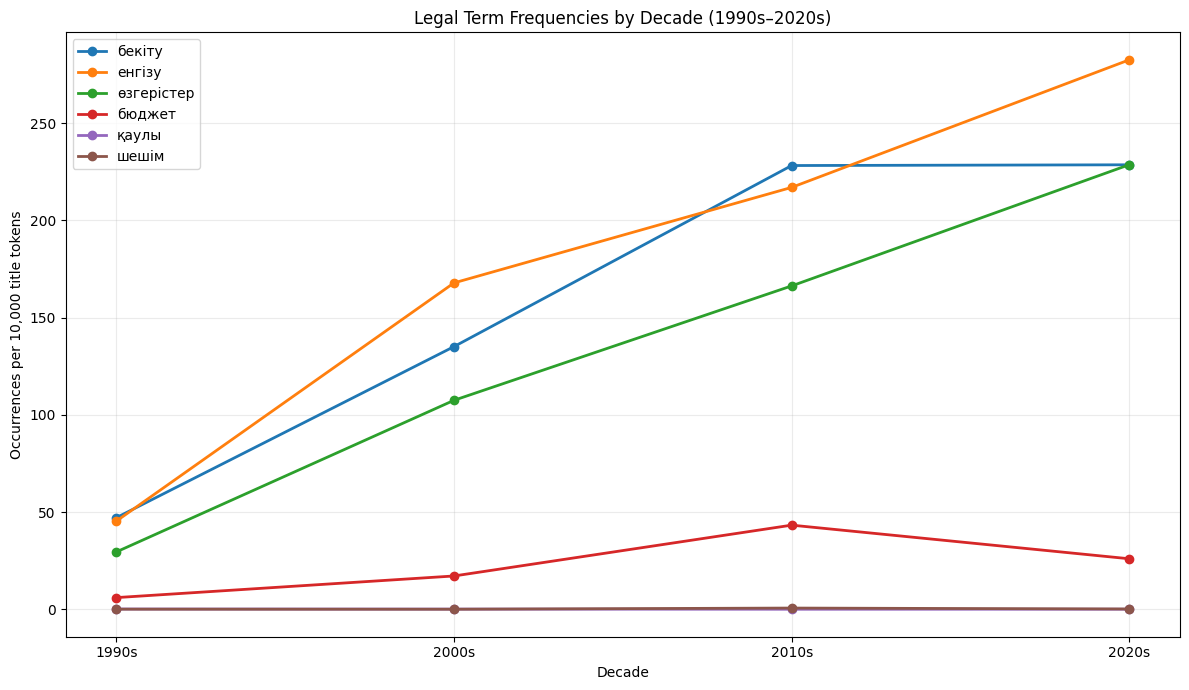


Saved figure: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/temporal_legal_terms.png
Saved data: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/temporal_legal_terms.csv

TEMPORAL LEXICAL ANALYSIS COMPLETED


In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

print("=" * 65)
print("TEMPORAL LEXICAL ANALYSIS — LEGAL TERMS")
print("=" * 65)

legal_terms = [
    "бекіту",
    "енгізу",
    "өзгерістер",
    "бюджет",
    "қаулы",
    "шешім"
]

decades = [1990, 2000, 2010, 2020]

records = []

for decade in decades:

    subset = nlp_df[
        nlp_df["decade"] == decade
    ]

    token_counts = Counter(
        word
        for tokens in subset["title_tokens"]
        for word in tokens
    )

    total_tokens = sum(token_counts.values())

    for term in legal_terms:

        raw_count = token_counts[term]

        normalized = (
            raw_count / total_tokens * 10000
            if total_tokens > 0 else 0
        )

        records.append({
            "decade": decade,
            "term": term,
            "raw_frequency": raw_count,
            "per_10000_tokens": normalized,
            "documents": len(subset),
            "total_tokens": total_tokens
        })

temporal_terms_df = pd.DataFrame(records)

print("\nNORMALIZED TERM FREQUENCIES")

pivot_table = temporal_terms_df.pivot(
    index="decade",
    columns="term",
    values="per_10000_tokens"
)

display(pivot_table.round(2))

fig, ax = plt.subplots(figsize=(12, 7))

for term in legal_terms:

    term_data = temporal_terms_df[
        temporal_terms_df["term"] == term
    ].sort_values("decade")

    ax.plot(
        term_data["decade"],
        term_data["per_10000_tokens"],
        marker="o",
        linewidth=2,
        label=term
    )

ax.set_title(
    "Legal Term Frequencies by Decade (1990s–2020s)"
)
ax.set_xlabel("Decade")
ax.set_ylabel("Occurrences per 10,000 title tokens")
ax.set_xticks(decades)
ax.set_xticklabels(
    [f"{d}s" for d in decades]
)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

figure_dir = project_dir / "outputs/figures"
processed_dir = project_dir / "data/processed"

figure_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "temporal_legal_terms.png"
csv_path = processed_dir / "temporal_legal_terms.csv"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

temporal_terms_df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved figure:", figure_path)
print("Saved data:", csv_path)

print("\nTEMPORAL LEXICAL ANALYSIS COMPLETED")

TEMPORAL ANALYSIS — LEMMATIZED TERMS

LEMMA-NORMALIZED TERM FREQUENCIES


term,бекіту / бекіт,бюджет,енгіз,шешім,қаулы,өзгеріс
decade,,,,,,
1990,47.32,18.53,45.62,4.88,82.62,38.97
2000,135.33,36.47,168.31,35.34,109.56,133.77
2010,228.48,106.97,219.39,128.75,69.24,205.18
2020,228.80,206.52,283.42,208.08,44.55,275.72


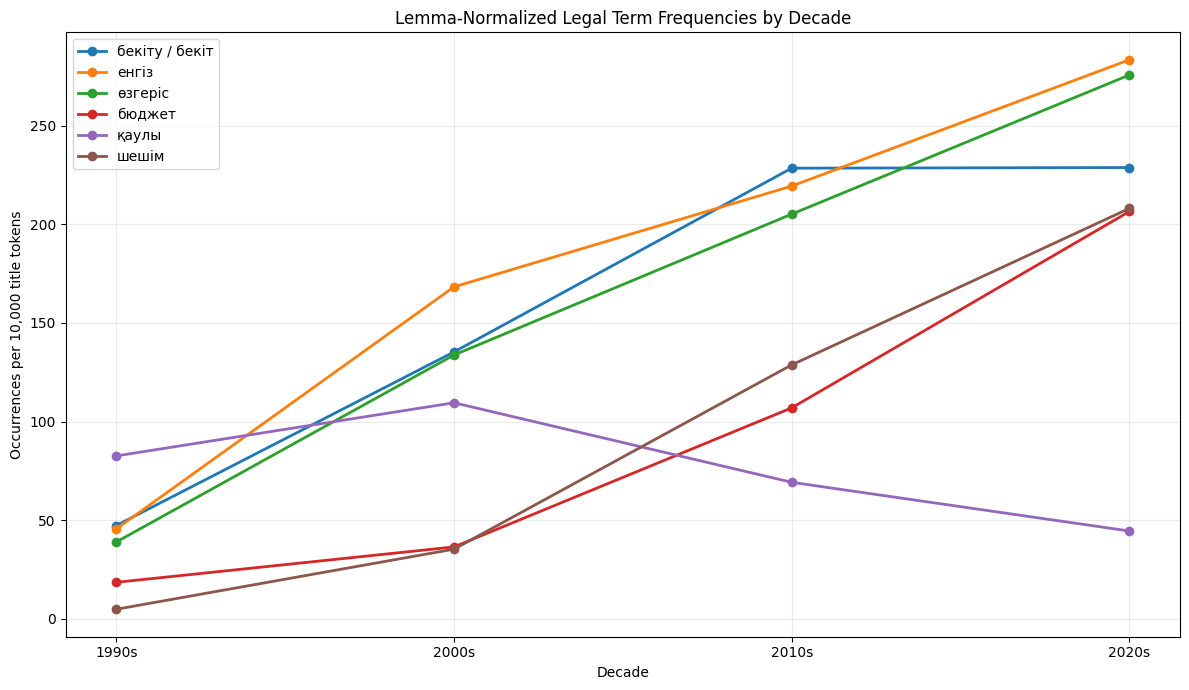


Saved figure: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/temporal_lemma_terms.png
Saved data: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/temporal_lemma_terms.csv

TEMPORAL LEMMA ANALYSIS COMPLETED


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

print("=" * 65)
print("TEMPORAL ANALYSIS — LEMMATIZED TERMS")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

lemma_df = pd.read_parquet(
    project_dir / "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_map = dict(zip(lemma_df["word"], lemma_df["lemma"]))

term_groups = {
    "бекіту / бекіт": {"бекіту", "бекіт"},
    "енгіз": {"енгіз"},
    "өзгеріс": {"өзгеріс"},
    "бюджет": {"бюджет"},
    "қаулы": {"қаулы"},
    "шешім": {"шешім"}
}

decades = [1990, 2000, 2010, 2020]
records = []

for decade in decades:

    subset = nlp_df[nlp_df["decade"] == decade]

    original_counter = Counter(
        token
        for tokens in subset["title_tokens"]
        for token in tokens
    )

    lemma_counter = Counter()

    for word, frequency in original_counter.items():
        lemma = lemma_map.get(word, word)
        lemma_counter[lemma] += frequency

    total_tokens = sum(original_counter.values())

    for term, accepted_lemmas in term_groups.items():

        count = sum(
            lemma_counter[lemma]
            for lemma in accepted_lemmas
        )

        normalized = (
            count / total_tokens * 10000
            if total_tokens else 0
        )

        records.append({
            "decade": decade,
            "term": term,
            "frequency": count,
            "per_10000_tokens": normalized
        })

lemma_temporal_df = pd.DataFrame(records)

print("\nLEMMA-NORMALIZED TERM FREQUENCIES")

pivot = lemma_temporal_df.pivot(
    index="decade",
    columns="term",
    values="per_10000_tokens"
)

display(pivot.round(2))

fig, ax = plt.subplots(figsize=(12, 7))

for term in term_groups:

    data = lemma_temporal_df[
        lemma_temporal_df["term"] == term
    ].sort_values("decade")

    ax.plot(
        data["decade"],
        data["per_10000_tokens"],
        marker="o",
        linewidth=2,
        label=term
    )

ax.set_title(
    "Lemma-Normalized Legal Term Frequencies by Decade"
)
ax.set_xlabel("Decade")
ax.set_ylabel("Occurrences per 10,000 title tokens")

ax.set_xticks(decades)
ax.set_xticklabels([f"{d}s" for d in decades])

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

figure_dir = project_dir / "outputs/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "temporal_lemma_terms.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

data_path = (
    project_dir / "data/processed/temporal_lemma_terms.csv"
)

lemma_temporal_df.to_csv(
    data_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved figure:", figure_path)
print("Saved data:", data_path)

print("\nTEMPORAL LEMMA ANALYSIS COMPLETED")

# SQL

## 11. SQLite database


In [67]:
import sqlite3
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path

print("=" * 65)
print("SQL DATABASE — INITIALIZATION")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

parquet_path = (
    project_dir / "data/processed/"
    "kazakhlawcorpus_optimized.parquet"
)

database_dir = project_dir / "data/database"
database_dir.mkdir(parents=True, exist_ok=True)

database_path = database_dir / "kazakh_legal_corpus.db"

conn = sqlite3.connect(database_path)

conn.execute("""
CREATE TABLE IF NOT EXISTS legal_documents (
    law_id TEXT PRIMARY KEY,
    source_id INTEGER,
    title TEXT,
    description TEXT,
    date_adopted TEXT,
    year INTEGER,
    decade INTEGER,
    legal_relation_area TEXT
)
""")

conn.execute("DELETE FROM legal_documents")
conn.commit()

parquet_file = pq.ParquetFile(parquet_path)

columns = [
    "law_id",
    "source_id",
    "title",
    "description",
    "date_adopted",
    "legal_relation_area"
]

insert_query = """
INSERT INTO legal_documents (
    law_id, source_id, title, description,
    date_adopted, year, decade, legal_relation_area
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?)
"""

total_inserted = 0

try:
    for batch in parquet_file.iter_batches(
        batch_size=5000,
        columns=columns
    ):

        df = batch.to_pandas()

        dates = pd.to_datetime(
            df["date_adopted"],
            errors="coerce"
        )

        df["year"] = dates.dt.year
        df["decade"] = (df["year"] // 10) * 10

        df["date_adopted"] = dates.dt.strftime("%Y-%m-%d")

        df["year"] = df["year"].astype("Int64")
        df["decade"] = df["decade"].astype("Int64")

        df = df.astype(object).where(pd.notna(df), None)

        rows = list(
            df[
                [
                    "law_id",
                    "source_id",
                    "title",
                    "description",
                    "date_adopted",
                    "year",
                    "decade",
                    "legal_relation_area"
                ]
            ].itertuples(index=False, name=None)
        )

        conn.executemany(insert_query, rows)

        total_inserted += len(rows)

    conn.execute("""
        CREATE INDEX IF NOT EXISTS idx_year
        ON legal_documents(year)
    """)

    conn.execute("""
        CREATE INDEX IF NOT EXISTS idx_decade
        ON legal_documents(decade)
    """)

    conn.commit()

    print("\nDATABASE CREATED SUCCESSFULLY")

    print("Rows inserted:", total_inserted)

    count = conn.execute(
        "SELECT COUNT(*) FROM legal_documents"
    ).fetchone()[0]

    print("Rows in SQLite:", count)

    assert count == 215889, "Unexpected document count"

    print("\nSAMPLE RECORDS")

    sample = pd.read_sql_query("""
        SELECT
            law_id,
            date_adopted,
            year,
            decade,
            SUBSTR(title, 1, 90) AS title_preview
        FROM legal_documents
        LIMIT 5
    """, conn)

    display(sample)

    print("\nSaved database:", database_path)

finally:
    conn.close()

print("\nSQL DATABASE INITIALIZATION COMPLETED")

SQL DATABASE — INITIALIZATION

DATABASE CREATED SUCCESSFULLY
Rows inserted: 215889
Rows in SQLite: 215889

SAMPLE RECORDS


,law_id,date_adopted,year,decade,title_preview
0,A04C0000417,2004-07-15,2004,2000,Қазақстан Республикасы Ішкі істер министрінің кейбір бұйрықтарының күшін жою туралы
1,A05I0001722,2005-04-18,2005,2000,"""Кеме қатынасы және теңізде жүзу қауіпсіздігі туралы"" Қазақстан Республикасы Көлік және ко"
2,A06C0001819,2006-12-30,2006,2000,1999 жылдан бастап 2005 жылдар аралығында Қазақстан Республикасы Ішкі істер министрілігіні
3,A06G0002831,2006-12-29,2006,2000,Қазақстан Республикасы Еңбек және халықты әлеуметтік қорғау министрінің кейбір бұйрықтарын
4,A07C0001814,2007-05-10,2007,2000,Экологиялық құқық бұзушылықтарға қарсы күрес және карантиндік іс-шараларға қатысу жөніндег



Saved database: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/database/kazakh_legal_corpus.db

SQL DATABASE INITIALIZATION COMPLETED


In [68]:
import sqlite3
import pandas as pd
from pathlib import Path

print("=" * 65)
print("SQL ANALYSIS — FIRST 5 QUERIES")
print("=" * 65)

database_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/database/kazakh_legal_corpus.db"
)

assert database_path.exists(), "Database not found"

conn = sqlite3.connect(database_path)

queries = {
    "Q1 — Documents by decade": """
        SELECT
            decade,
            COUNT(*) AS document_count
        FROM legal_documents
        WHERE decade >= 1990
        GROUP BY decade
        ORDER BY decade
    """,

    "Q2 — Top 10 years": """
        SELECT
            year,
            COUNT(*) AS document_count
        FROM legal_documents
        WHERE year IS NOT NULL
        GROUP BY year
        ORDER BY document_count DESC
        LIMIT 10
    """,

    "Q3 — Documents mentioning budget": """
        SELECT
            decade,
            COUNT(*) AS budget_documents
        FROM legal_documents
        WHERE LOWER(title) LIKE '%бюджет%'
          AND decade >= 1990
        GROUP BY decade
        ORDER BY decade
    """,

    "Q4 — Average title length by decade": """
        SELECT
            decade,
            COUNT(*) AS documents,
            ROUND(AVG(LENGTH(title)), 2)
                AS avg_title_characters
        FROM legal_documents
        WHERE decade >= 1990
        GROUP BY decade
        ORDER BY decade
    """,

    "Q5 — Recent documents about amendments": """
        SELECT
            law_id,
            date_adopted,
            SUBSTR(title, 1, 120) AS title_preview
        FROM legal_documents
        WHERE LOWER(title) LIKE '%өзгерістер енгізу%'
          AND year >= 2020
        ORDER BY date_adopted DESC, law_id
        LIMIT 10
    """
}

results = {}

try:
    for name, query in queries.items():

        print("\n" + "=" * 65)
        print(name)
        print("=" * 65)

        result_df = pd.read_sql_query(query, conn)
        results[name] = result_df

        display(result_df)

finally:
    conn.close()

print("\n" + "=" * 65)
print("FIRST 5 SQL QUERIES COMPLETED")
print("=" * 65)

SQL ANALYSIS — FIRST 5 QUERIES

Q1 — Documents by decade


,decade,document_count
0,1990,9455
1,2000,28302
2,2010,91706
3,2020,86373



Q2 — Top 10 years


,year,document_count
0,2023,15092
1,2022,14670
2,2024,14279
3,2020,14268
4,2025,13715
5,2015,13389
6,2021,12786
7,2016,11143
8,2018,10972
9,2019,10789



Q3 — Documents mentioning budget


,decade,budget_documents
0,1990,275
1,2000,2129
2,2010,17998
3,2020,34488



Q4 — Average title length by decade


,decade,documents,avg_title_characters
0,1990,9455,113.75
1,2000,28302,146.68
2,2010,91706,166.41
3,2020,86373,181.59



Q5 — Recent documents about amendments


,law_id,date_adopted,title_preview
0,R2600000117,2026-07-20,"""Қазақстан Республикасы Үкіметінің жанынан Отандық кәсіпкерлер кеңесін құру туралы"" Қазақстан Республикасы Премьер-Минис"
1,V2600039303,2026-07-15,"""Агроөнеркәсіптік кешен субъектілерінің қарыздарын кепілдендіру мен сақтандыру шеңберінде субсидиялау қағидаларын бекіту"
2,Z2600000347,2026-07-14,"2015 жылғы 15 қыркүйектегі Әскери және басқа да құралымдарды, олардың жылжымалы мүлкін, сондай-ақ әскери мақсаттағы өнім"
3,P2600000600,2026-07-09,Қазақстан Республикасы Үкіметінің кейбір шешімдеріне өзгерістер енгізу туралы
4,Z2600000344,2026-07-09,2010 жылғы 10 желтоқсандағы Ұжымдық қауіпсіздік туралы шарт ұйымы ұжымдық қауіпсіздік жүйесінің күштері мен құралдары құ
5,P2600000589,2026-07-08,"""Жер қойнауын пайдалану жөніндегі операцияларға және жер қойнауын пайдалану жөніндегі операцияларды қамтамасыз етуге тар"
6,P2600000564,2026-06-30,"""Азаматтық қызметшілерге, мемлекеттік бюджет қаражаты есебінен ұсталатын ұйымдардың қызметкерлеріне, қазыналық кәсіпорын"
7,G26NZA00015,2026-06-26,"""Ресми статистикалық ақпараттың сапасын бағалау әдістемесін бекіту туралы"" Қазақстан Республикасы Ұлттық экономика минис"
8,G26ZH00006B,2026-06-26,"Казталов ауданы әкiмiнiң ""Казталов ауданы аумағында сайлау учаскелерiн құру туралы"" 2013 жылғы 30 қаңтардағы № 1 шешімін"
9,G26KN000045,2026-06-25,"""Қазақстан Республикасы ұлттық қауіпсіздік органдарының жұмыскерлері еңбегінің кейбір мәселелері туралы"" Қазақстан Респу"



FIRST 5 SQL QUERIES COMPLETED


In [69]:
import sqlite3
import pandas as pd
from pathlib import Path

print("=" * 65)
print("SQL ANALYSIS — ADVANCED QUERIES")
print("=" * 65)

database_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/database/kazakh_legal_corpus.db"
)

conn = sqlite3.connect(database_path)

queries = {

    "Q6 — Legal title categories": """
        SELECT
            CASE
                WHEN LOWER(title) LIKE '%бюджет%'
                    THEN 'Budget-related'
                WHEN LOWER(title) LIKE '%өзгерістер енгізу%'
                    THEN 'Amendments'
                WHEN LOWER(title) LIKE '%бекіту%'
                    THEN 'Approval'
                ELSE 'Other'
            END AS title_category,
            COUNT(*) AS document_count
        FROM legal_documents
        GROUP BY title_category
        ORDER BY document_count DESC
    """,

    "Q7 — Budget documents percentage by decade": """
        WITH decade_summary AS (
            SELECT
                decade,
                COUNT(*) AS total_documents,
                SUM(
                    CASE
                        WHEN LOWER(title) LIKE '%бюджет%'
                        THEN 1 ELSE 0
                    END
                ) AS budget_documents
            FROM legal_documents
            WHERE decade >= 1990
            GROUP BY decade
        )
        SELECT
            decade,
            total_documents,
            budget_documents,
            ROUND(
                100.0 * budget_documents / total_documents,
                2
            ) AS budget_percentage
        FROM decade_summary
        ORDER BY decade
    """,

    "Q8 — Top years and their decade shares": """
        WITH yearly_counts AS (
            SELECT
                year,
                decade,
                COUNT(*) AS yearly_documents
            FROM legal_documents
            WHERE year >= 1990
            GROUP BY year, decade
        ),
        decade_counts AS (
            SELECT
                decade,
                COUNT(*) AS decade_documents
            FROM legal_documents
            WHERE decade >= 1990
            GROUP BY decade
        )
        SELECT
            y.year,
            y.decade,
            y.yearly_documents,
            d.decade_documents,
            ROUND(
                100.0 * y.yearly_documents
                / d.decade_documents,
                2
            ) AS share_of_decade_percent
        FROM yearly_counts AS y
        JOIN decade_counts AS d
            ON y.decade = d.decade
        ORDER BY y.yearly_documents DESC
        LIMIT 10
    """
}

sql_results = {}

try:
    for name, query in queries.items():

        print("\n" + "=" * 65)
        print(name)
        print("=" * 65)

        df = pd.read_sql_query(query, conn)

        sql_results[name] = df

        display(df)

finally:
    conn.close()

print("\nADVANCED SQL ANALYSIS COMPLETED")

SQL ANALYSIS — ADVANCED QUERIES

Q6 — Legal title categories


,title_category,document_count
0,Other,82281
1,Approval,57814
2,Budget-related,54890
3,Amendments,20904



Q7 — Budget documents percentage by decade


,decade,total_documents,budget_documents,budget_percentage
0,1990,9455,275,2.91
1,2000,28302,2129,7.52
2,2010,91706,17998,19.63
3,2020,86373,34488,39.93



Q8 — Top years and their decade shares


,year,decade,yearly_documents,decade_documents,share_of_decade_percent
0,2023,2020,15092,86373,17.47
1,2022,2020,14670,86373,16.98
2,2024,2020,14279,86373,16.53
3,2020,2020,14268,86373,16.52
4,2025,2020,13715,86373,15.88
5,2015,2010,13389,91706,14.60
6,2021,2020,12786,86373,14.80
7,2016,2010,11143,91706,12.15
8,2018,2010,10972,91706,11.96
9,2019,2010,10789,91706,11.76



ADVANCED SQL ANALYSIS COMPLETED


# TF IDF

## 12. TF-IDF retrieval


In [70]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path
import joblib

print("=" * 65)
print("TF-IDF DOCUMENT SEARCH — INDEX BUILDING")
print("=" * 65)

search_df = nlp_df[
    ["law_id", "title", "title_tokens"]
].copy().reset_index(drop=True)

search_df["search_text"] = search_df[
    "title_tokens"
].apply(lambda tokens: " ".join(tokens))

print("Documents to index:", len(search_df))

vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

tfidf_matrix = vectorizer.fit_transform(
    search_df["search_text"]
)

print("\nTF-IDF MATRIX")
print("Shape:", tfidf_matrix.shape)
print("Non-zero values:", tfidf_matrix.nnz)
print("Vocabulary size:", len(vectorizer.vocabulary_))

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    vectorizer,
    model_dir / "tfidf_vectorizer.joblib"
)

joblib.dump(
    tfidf_matrix,
    model_dir / "tfidf_matrix.joblib"
)

search_df[
    ["law_id", "title"]
].to_parquet(
    model_dir / "tfidf_documents.parquet",
    index=False
)

print("\nMODEL FILES SAVED")
print("- tfidf_vectorizer.joblib")
print("- tfidf_matrix.joblib")
print("- tfidf_documents.parquet")

print("\nTF-IDF INDEX BUILDING COMPLETED")

TF-IDF DOCUMENT SEARCH — INDEX BUILDING
Documents to index: 215889

TF-IDF MATRIX
Shape: (215889, 22732)
Non-zero values: 3367611
Vocabulary size: 22732

MODEL FILES SAVED
- tfidf_vectorizer.joblib
- tfidf_matrix.joblib
- tfidf_documents.parquet

TF-IDF INDEX BUILDING COMPLETED


In [71]:
import re
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

print("=" * 65)
print("TF-IDF DOCUMENT SEARCH — TESTING")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

model_dir = project_dir / "models"

vectorizer = joblib.load(
    model_dir / "tfidf_vectorizer.joblib"
)

tfidf_matrix = joblib.load(
    model_dir / "tfidf_matrix.joblib"
)

search_documents = pd.read_parquet(
    model_dir / "tfidf_documents.parquet"
)

assert tfidf_matrix.shape[0] == len(search_documents)

token_pattern = re.compile(
    r"[а-яёәғқңөұүһі]+",
    re.IGNORECASE
)

def preprocess_query(query):
    tokens = token_pattern.findall(query.lower())
    return " ".join(tokens)


def search_legal_documents(query, top_k=5):

    cleaned_query = preprocess_query(query)

    query_vector = vectorizer.transform(
        [cleaned_query]
    )

    if query_vector.nnz == 0:
        print("No matching vocabulary terms found.")
        return pd.DataFrame()

    scores = (
        tfidf_matrix @ query_vector.T
    ).toarray().ravel()

    candidate_indices = np.flatnonzero(scores > 0)

    if len(candidate_indices) == 0:
        return pd.DataFrame()

    k = min(top_k, len(candidate_indices))

    top_positions = np.argpartition(
        scores[candidate_indices], -k
    )[-k:]

    top_indices = candidate_indices[top_positions]

    top_indices = top_indices[
        np.argsort(scores[top_indices])[::-1]
    ]

    results = search_documents.iloc[
        top_indices
    ].copy()

    results["similarity"] = np.round(
        scores[top_indices], 4
    )

    return results.reset_index(drop=True)


test_queries = [
    "ауылдық округ бюджеті",
    "мемлекеттік сатып алу қағидалары",
    "қоршаған ортаны қорғау"
]

for query in test_queries:

    print("\n" + "=" * 65)
    print("QUERY:", query)
    print("=" * 65)

    results = search_legal_documents(
        query,
        top_k=5
    )

    display(results)

print("\nTF-IDF SEARCH TEST COMPLETED")

TF-IDF DOCUMENT SEARCH — TESTING

QUERY: ауылдық округ бюджеті


,law_id,title,similarity
0,V17KB004518,2018-2020 жылдарға арналған ауылдық округ бюджеті туралы,0.9020
1,V20CB006722,2020–2022 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
2,G22CB00149M,2022–2024 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
3,V21CB007971,2021-2023 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
4,G21CI00134M,2022-2024 жылдарға арналған Еңбек ауылдық округ бюджетін бекіту туралы,0.5316



QUERY: мемлекеттік сатып алу қағидалары


,law_id,title,similarity
0,Z070000303_,Мемлекеттік сатып алу туралы,0.7611
1,Z020000321_,Мемлекеттік сатып алу туралы,0.7611
2,P1400001412,"""Мемлекеттік сатып алу туралы"" Қазақстан Республикасы Заңының жобасы туралы",0.5174
3,P990000304_,Қазақстан Республикасының Мемлекеттік сатып алу жөніндегі агенттігі туралы,0.5108
4,Z1500000434,Мемлекеттiк сатып алу туралы,0.4993



QUERY: қоршаған ортаны қорғау


,law_id,title,similarity
0,Z970000160_,Қоршаған ортаны қорғау туралы,1.0000
1,P070001201_,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің мәселелері,0.8239
2,P000000260_,Қазақстан Республикасының Табиғи ресурстар және қоршаған ортаны қорғау министрлігі Қоршаған ортаны қорғау комитетінің мәселелері,0.7974
3,P080000236_,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің кейбір мәселелері,0.7934
4,P1200000656,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің кейбір мәселелері туралы,0.7934



TF-IDF SEARCH TEST COMPLETED


In [72]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer

print("=" * 65)
print("LEMMA-BASED TF-IDF — INDEX BUILDING")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

lemma_df = pd.read_parquet(
    project_dir / "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_map = dict(
    zip(lemma_df["word"], lemma_df["lemma"])
)

print("Lemma mappings:", len(lemma_map))

def normalize_tokens(tokens):
    return [
        lemma_map.get(token, token)
        for token in tokens
    ]

lemma_search_df = nlp_df[
    ["law_id", "title", "title_tokens"]
].copy().reset_index(drop=True)

lemma_search_df["lemma_text"] = (
    lemma_search_df["title_tokens"]
    .apply(
        lambda tokens: " ".join(
            normalize_tokens(tokens)
        )
    )
)

print("Documents:", len(lemma_search_df))

lemma_vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

lemma_tfidf_matrix = (
    lemma_vectorizer.fit_transform(
        lemma_search_df["lemma_text"]
    )
)

print("\nLEMMA TF-IDF MATRIX")
print("Shape:", lemma_tfidf_matrix.shape)
print("Non-zero values:", lemma_tfidf_matrix.nnz)
print(
    "Vocabulary size:",
    len(lemma_vectorizer.vocabulary_)
)

joblib.dump(
    lemma_vectorizer,
    model_dir / "lemma_tfidf_vectorizer.joblib"
)

joblib.dump(
    lemma_tfidf_matrix,
    model_dir / "lemma_tfidf_matrix.joblib"
)

lemma_search_df[
    ["law_id", "title"]
].to_parquet(
    model_dir / "lemma_tfidf_documents.parquet",
    index=False
)

baseline_vectorizer = joblib.load(
    model_dir / "tfidf_vectorizer.joblib"
)

baseline_size = len(baseline_vectorizer.vocabulary_)
lemma_size = len(lemma_vectorizer.vocabulary_)

reduction = (
    (baseline_size - lemma_size)
    / baseline_size * 100
)

print("\n" + "=" * 65)
print("TF-IDF VOCABULARY COMPARISON")
print("=" * 65)

print("Baseline features:", baseline_size)
print("Lemma-based features:", lemma_size)
print("Feature reduction:", round(reduction, 2), "%")

print("\nMODEL FILES SAVED")
print("LEMMA TF-IDF INDEX BUILDING COMPLETED")

LEMMA-BASED TF-IDF — INDEX BUILDING
Lemma mappings: 35523
Documents: 215889

LEMMA TF-IDF MATRIX
Shape: (215889, 14535)
Non-zero values: 3318200
Vocabulary size: 14535

TF-IDF VOCABULARY COMPARISON
Baseline features: 22732
Lemma-based features: 14535
Feature reduction: 36.06 %

MODEL FILES SAVED
LEMMA TF-IDF INDEX BUILDING COMPLETED


In [73]:
import re
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("TF-IDF SEARCH MODEL COMPARISON")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

model_dir = project_dir / "models"

baseline_vectorizer = joblib.load(
    model_dir / "tfidf_vectorizer.joblib"
)

baseline_matrix = joblib.load(
    model_dir / "tfidf_matrix.joblib"
)

lemma_vectorizer = joblib.load(
    model_dir / "lemma_tfidf_vectorizer.joblib"
)

lemma_matrix = joblib.load(
    model_dir / "lemma_tfidf_matrix.joblib"
)

baseline_docs = pd.read_parquet(
    model_dir / "tfidf_documents.parquet"
)

lemma_docs = pd.read_parquet(
    model_dir / "lemma_tfidf_documents.parquet"
)

assert baseline_docs["law_id"].equals(
    lemma_docs["law_id"]
), "Document ordering differs between models!"

lemma_mapping_df = pd.read_parquet(
    project_dir / "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_map = dict(
    zip(
        lemma_mapping_df["word"],
        lemma_mapping_df["lemma"]
    )
)

token_pattern = re.compile(
    r"[а-яёәғқңөұүһі]+",
    re.IGNORECASE
)

def preprocess_search_query(query, use_lemmas=False):

    tokens = token_pattern.findall(query.lower())

    if use_lemmas:
        tokens = [
            lemma_map.get(token, token)
            for token in tokens
        ]

    return " ".join(tokens)


def retrieve_documents(
    query,
    vectorizer,
    matrix,
    documents,
    use_lemmas=False,
    top_k=5
):

    cleaned = preprocess_search_query(
        query,
        use_lemmas=use_lemmas
    )

    query_vector = vectorizer.transform([cleaned])

    if query_vector.nnz == 0:
        return pd.DataFrame(
            columns=["law_id", "title", "similarity"]
        )

    scores = (matrix @ query_vector.T).toarray().ravel()

    candidates = np.flatnonzero(scores > 0)

    if len(candidates) == 0:
        return pd.DataFrame(
            columns=["law_id", "title", "similarity"]
        )

    k = min(top_k, len(candidates))

    top_positions = np.argpartition(
        scores[candidates], -k
    )[-k:]

    top_indices = candidates[top_positions]

    top_indices = sorted(
        top_indices,
        key=lambda i: (
            -scores[i],
            documents.iloc[i]["law_id"]
        )
    )

    results = documents.iloc[
        top_indices
    ][["law_id", "title"]].copy()

    results["similarity"] = [
        round(float(scores[i]), 4)
        for i in top_indices
    ]

    return results.reset_index(drop=True)


test_queries = [
    "ауылдық округ бюджеті",
    "мемлекеттік сатып алу қағидалары",
    "қоршаған ортаны қорғау",
    "мәслихат шешіміне өзгерістер енгізу",
    "жер учаскелерін беру"
]

for query in test_queries:

    print("\n" + "=" * 65)
    print("QUERY:", query)
    print("=" * 65)

    baseline_results = retrieve_documents(
        query,
        baseline_vectorizer,
        baseline_matrix,
        baseline_docs,
        use_lemmas=False,
        top_k=5
    )

    lemma_results = retrieve_documents(
        query,
        lemma_vectorizer,
        lemma_matrix,
        lemma_docs,
        use_lemmas=True,
        top_k=5
    )

    print("\nBASELINE TF-IDF")
    display(baseline_results)

    print("\nLEMMA-BASED TF-IDF")
    display(lemma_results)

print("\nTF-IDF MODEL COMPARISON COMPLETED")

TF-IDF SEARCH MODEL COMPARISON

QUERY: ауылдық округ бюджеті

BASELINE TF-IDF


,law_id,title,similarity
0,V17KB004518,2018-2020 жылдарға арналған ауылдық округ бюджеті туралы,0.9020
1,G22CB00149M,2022–2024 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
2,V20CB006722,2020–2022 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
3,V21CB007971,2021-2023 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,0.5457
4,G21CI00134M,2022-2024 жылдарға арналған Еңбек ауылдық округ бюджетін бекіту туралы,0.5316



LEMMA-BASED TF-IDF


,law_id,title,similarity
0,G21TC00101M,2022-2024 жылдарға арналған ауылдық округтердің бюджеттері туралы,0.8197
1,G24TC00174M,2025-2027 жылдарға арналған ауылдық округтердің бюджеттері туралы,0.8197
2,G25UF37220M,2026-2028 жылдарға арналған ауылдық округтердің бюджеті туралы,0.8197
3,G25UI32183M,2026-2028 жылдарға арналған ауылдық округтердің бюджеттері туралы,0.8197
4,V18TC004321,2019–2021 жылдарға арналған ауылдық округтердің бюджеттері туралы,0.8197



QUERY: мемлекеттік сатып алу қағидалары

BASELINE TF-IDF


,law_id,title,similarity
0,Z020000321_,Мемлекеттік сатып алу туралы,0.7611
1,Z070000303_,Мемлекеттік сатып алу туралы,0.7611
2,P1400001412,"""Мемлекеттік сатып алу туралы"" Қазақстан Республикасы Заңының жобасы туралы",0.5174
3,P990000304_,Қазақстан Республикасының Мемлекеттік сатып алу жөніндегі агенттігі туралы,0.5108
4,Z1500000434,Мемлекеттiк сатып алу туралы,0.4993


... (11 outputs left out)

,law_id,title,similarity
0,P1000001214,Жер учаскелерін ауыстыру туралы,0.6464
1,P1200000575,Жер учаскелерін ауыстыру туралы,0.6464
2,U950002717_,Жер туралы,0.5869
3,Z010000152_,Жер туралы,0.5869
4,R2400000144,Жер учаскелерін берудің кейбір мәселелері туралы,0.5699



LEMMA-BASED TF-IDF


,law_id,title,similarity
0,R2400000144,Жер учаскелерін берудің кейбір мәселелері туралы,0.7987
1,P1000001397,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,0.6528
2,P1100000548,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,0.6528
3,P1100001361,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,0.6528
4,P1700000235,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,0.6528



TF-IDF MODEL COMPARISON COMPLETED


In [74]:
import pandas as pd
from pathlib import Path

print("=" * 65)
print("TF-IDF SEARCH EVALUATION — PREPARATION")
print("=" * 65)

evaluation_queries = [
    "ауылдық округ бюджеті",
    "мемлекеттік сатып алу қағидалары",
    "қоршаған ортаны қорғау",
    "мәслихат шешіміне өзгерістер енгізу",
    "жер учаскелерін беру"
]

records = []

for query in evaluation_queries:

    for model_name, vectorizer, matrix, documents, use_lemmas in [
        (
            "baseline",
            baseline_vectorizer,
            baseline_matrix,
            baseline_docs,
            False
        ),
        (
            "lemma_based",
            lemma_vectorizer,
            lemma_matrix,
            lemma_docs,
            True
        )
    ]:

        results = retrieve_documents(
            query,
            vectorizer,
            matrix,
            documents,
            use_lemmas=use_lemmas,
            top_k=5
        )

        for rank, row in enumerate(
            results.itertuples(index=False),
            start=1
        ):

            records.append({
                "query": query,
                "model": model_name,
                "rank": rank,
                "law_id": row.law_id,
                "title": row.title,
                "similarity": row.similarity,
                "relevant": pd.NA,
                "notes": pd.NA
            })

evaluation_df = pd.DataFrame(records)

output_dir = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed"
)

output_dir.mkdir(parents=True, exist_ok=True)

evaluation_path = (
    output_dir / "tfidf_precision_at_5_review.csv"
)

evaluation_df.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

print("Total evaluation rows:", len(evaluation_df))
print("Queries:", evaluation_df["query"].nunique())
print("Models:", evaluation_df["model"].unique())

print("\nRESULTS FOR LAND ALLOCATION QUERY")

display(
    evaluation_df[
        evaluation_df["query"] == "жер учаскелерін беру"
    ][
        ["model", "rank", "title", "relevant"]
    ]
)

print("\nSaved:", evaluation_path)
print("\nEVALUATION DATASET CREATED")

TF-IDF SEARCH EVALUATION — PREPARATION
Total evaluation rows: 50
Queries: 5
Models: ['baseline' 'lemma_based']

RESULTS FOR LAND ALLOCATION QUERY


,model,rank,title,relevant
40,baseline,1,Жер учаскелерін ауыстыру туралы,<NA>
41,baseline,2,Жер учаскелерін ауыстыру туралы,<NA>
42,baseline,3,Жер туралы,<NA>
43,baseline,4,Жер туралы,<NA>
44,baseline,5,Жер учаскелерін берудің кейбір мәселелері туралы,<NA>
45,lemma_based,1,Жер учаскелерін берудің кейбір мәселелері туралы,<NA>
46,lemma_based,2,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,<NA>
47,lemma_based,3,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,<NA>
48,lemma_based,4,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,<NA>
49,lemma_based,5,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,<NA>



Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/tfidf_precision_at_5_review.csv

EVALUATION DATASET CREATED


In [75]:
import pandas as pd
from pathlib import Path

print("=" * 65)
print("PRECISION@5 — LAND ALLOCATION EVALUATION")
print("=" * 65)

evaluation_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/tfidf_precision_at_5_review.csv"
)

evaluation_df = pd.read_csv(evaluation_path)

query = "жер учаскелерін беру"

baseline_labels = [0, 0, 0, 0, 1]
lemma_labels = [1, 1, 1, 1, 1]

for model, labels in [
    ("baseline", baseline_labels),
    ("lemma_based", lemma_labels)
]:

    mask = (
        (evaluation_df["query"] == query)
        & (evaluation_df["model"] == model)
    )

    indices = (
        evaluation_df.loc[mask]
        .sort_values("rank")
        .index
    )

    assert len(indices) == 5, "Expected 5 results"

    evaluation_df.loc[indices, "relevant"] = labels

evaluation_df.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

land_results = evaluation_df[
    evaluation_df["query"] == query
].copy()

land_results["relevant"] = (
    land_results["relevant"].astype(int)
)

precision_results = (
    land_results.groupby("model")["relevant"]
    .mean()
    .reset_index()
    .rename(columns={"relevant": "precision_at_5"})
)

print("\nPRECISION@5 RESULTS")
display(precision_results)

print("\nREVIEWED DOCUMENTS")
display(
    land_results[
        ["model", "rank", "title", "relevant"]
    ]
)

print("\nSaved:", evaluation_path)
print("\nLAND ALLOCATION EVALUATION COMPLETED")

PRECISION@5 — LAND ALLOCATION EVALUATION

PRECISION@5 RESULTS


,model,precision_at_5
0,baseline,0.2
1,lemma_based,1.0



REVIEWED DOCUMENTS


,model,rank,title,relevant
40,baseline,1,Жер учаскелерін ауыстыру туралы,0
41,baseline,2,Жер учаскелерін ауыстыру туралы,0
42,baseline,3,Жер туралы,0
43,baseline,4,Жер туралы,0
44,baseline,5,Жер учаскелерін берудің кейбір мәселелері туралы,1
45,lemma_based,1,Жер учаскелерін берудің кейбір мәселелері туралы,1
46,lemma_based,2,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,1
47,lemma_based,3,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,1
48,lemma_based,4,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,1
49,lemma_based,5,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,1



Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/processed/tfidf_precision_at_5_review.csv

LAND ALLOCATION EVALUATION COMPLETED


In [76]:
import pandas as pd
from pathlib import Path

print("=" * 65)
print("TF-IDF RELEVANCE REVIEW — QUERIES 2 AND 3")
print("=" * 65)

evaluation_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/tfidf_precision_at_5_review.csv"
)

evaluation_df = pd.read_csv(evaluation_path)

review_queries = [
    "мемлекеттік сатып алу қағидалары",
    "қоршаған ортаны қорғау"
]

for query in review_queries:

    print("\n" + "=" * 65)
    print("QUERY:", query)
    print("=" * 65)

    subset = evaluation_df[
        evaluation_df["query"] == query
    ].copy()

    subset = subset.sort_values(
        ["model", "rank"]
    )

    display(
        subset[
            [
                "model",
                "rank",
                "law_id",
                "title",
                "relevant"
            ]
        ].reset_index(drop=True)
    )

print("\nRELEVANCE REVIEW TABLES READY")

TF-IDF RELEVANCE REVIEW — QUERIES 2 AND 3

QUERY: мемлекеттік сатып алу қағидалары


,model,rank,law_id,title,relevant
0,baseline,1,Z020000321_,Мемлекеттік сатып алу туралы,NaN
1,baseline,2,Z070000303_,Мемлекеттік сатып алу туралы,NaN
2,baseline,3,P1400001412,"""Мемлекеттік сатып алу туралы"" Қазақстан Республикасы Заңының жобасы туралы",NaN
3,baseline,4,P990000304_,Қазақстан Республикасының Мемлекеттік сатып алу жөніндегі агенттігі туралы,NaN
4,baseline,5,Z1500000434,Мемлекеттiк сатып алу туралы,NaN
5,lemma_based,1,Z020000321_,Мемлекеттік сатып алу туралы,NaN
6,lemma_based,2,Z070000303_,Мемлекеттік сатып алу туралы,NaN
7,lemma_based,3,Z050000035_,"""Мемлекеттік сатып алу туралы"" Қазақстан Республикасының Заңына толықтыру енгізу туралы",NaN
8,lemma_based,4,P1400001412,"""Мемлекеттік сатып алу туралы"" Қазақстан Республикасы Заңының жобасы туралы",NaN
9,lemma_based,5,P990000304_,Қазақстан Республикасының Мемлекеттік сатып алу жөніндегі агенттігі туралы,NaN



QUERY: қоршаған ортаны қорғау


,model,rank,law_id,title,relevant
0,baseline,1,Z970000160_,Қоршаған ортаны қорғау туралы,NaN
1,baseline,2,P070001201_,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің мәселелері,NaN
2,baseline,3,P000000260_,Қазақстан Республикасының Табиғи ресурстар және қоршаған ортаны қорғау министрлігі Қоршаған ортаны қорғау комитетінің мәселелері,NaN
3,baseline,4,P080000236_,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің кейбір мәселелері,NaN
4,baseline,5,P1200000656,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің кейбір мәселелері туралы,NaN
5,lemma_based,1,Z970000160_,Қоршаған ортаны қорғау туралы,NaN
6,lemma_based,2,P070001201_,Қазақстан Республикасы Қоршаған ортаны қорғау министрлігінің мәселелері,NaN
7,lemma_based,3,P000000260_,Қазақстан Республикасының Табиғи ресурстар және қоршаған ортаны қорғау министрлігі Қоршаған ортаны қорғау комитетінің мәселелері,NaN
8,lemma_based,4,V1600013435,Қазақстан Республикасы Қоршаған ортаны қорғау министрінің кейбір бұйрықтарына өзгерістер енгізу туралы,NaN
9,lemma_based,5,Z010000205_,"""Қоршаған ортаны қорғау туралы"" Қазақстан Республикасының Заңына өзгерістер мен толықтырулар енгізу туралы",NaN



RELEVANCE REVIEW TABLES READY


In [77]:
import pandas as pd
from pathlib import Path

evaluation_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/tfidf_precision_at_5_review.csv"
)

evaluation_df = pd.read_csv(evaluation_path)

labels = {
    "мемлекеттік сатып алу қағидалары": {
        "baseline": [0, 0, 0, 0, 0],
        "lemma_based": [0, 0, 0, 0, 0]
    },
    "қоршаған ортаны қорғау": {
        "baseline": [1, 1, 1, 1, 1],
        "lemma_based": [1, 1, 1, 1, 1]
    }
}

for query, models in labels.items():
    for model, relevance_labels in models.items():

        mask = (
            (evaluation_df["query"] == query) &
            (evaluation_df["model"] == model)
        )

        indices = (
            evaluation_df.loc[mask]
            .sort_values("rank")
            .index
        )

        assert len(indices) == 5

        evaluation_df.loc[
            indices, "relevant"
        ] = relevance_labels

        evaluation_df.loc[
            indices, "notes"
        ] = "Provisional title-based assessment"

evaluation_df.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

print("LABELED RESULTS:", evaluation_df["relevant"].notna().sum())
print("REMAINING:", evaluation_df["relevant"].isna().sum())

print("\nEVALUATION PROGRESS")

display(
    evaluation_df.groupby(
        ["query", "model"]
    )["relevant"].apply(
        lambda x: x.notna().sum()
    ).reset_index(name="labeled_results")
)

print("\nEVALUATION LABELS SAVED")

LABELED RESULTS: 30
REMAINING: 20

EVALUATION PROGRESS


/tmp/ipykernel_485/911845793.py:43: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Provisional title-based assessment' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  evaluation_df.loc[


,query,model,labeled_results
0,ауылдық округ бюджеті,baseline,0
1,ауылдық округ бюджеті,lemma_based,0
2,жер учаскелерін беру,baseline,5
3,жер учаскелерін беру,lemma_based,5
4,мемлекеттік сатып алу қағидалары,baseline,5
5,мемлекеттік сатып алу қағидалары,lemma_based,5
6,мәслихат шешіміне өзгерістер енгізу,baseline,0
7,мәслихат шешіміне өзгерістер енгізу,lemma_based,0
8,қоршаған ортаны қорғау,baseline,5
9,қоршаған ортаны қорғау,lemma_based,5



EVALUATION LABELS SAVED


In [78]:
import pandas as pd
from pathlib import Path

print("=" * 65)
print("TF-IDF EVALUATION — FINAL TWO QUERIES")
print("=" * 65)

evaluation_path = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project/"
    "data/processed/tfidf_precision_at_5_review.csv"
)

evaluation_df = pd.read_csv(evaluation_path)

evaluation_df["relevant"] = pd.to_numeric(
    evaluation_df["relevant"],
    errors="coerce"
).astype("Int64")

evaluation_df["notes"] = (
    evaluation_df["notes"].astype("string")
)

remaining_queries = [
    "ауылдық округ бюджеті",
    "мәслихат шешіміне өзгерістер енгізу"
]

for query in remaining_queries:

    print("\n" + "=" * 65)
    print("QUERY:", query)
    print("=" * 65)

    subset = evaluation_df[
        evaluation_df["query"] == query
    ].sort_values(["model", "rank"])

    display(
        subset[
            ["model", "rank", "law_id", "title", "relevant"]
        ].reset_index(drop=True)
    )

print("\nLABELED:", evaluation_df["relevant"].notna().sum())
print("REMAINING:", evaluation_df["relevant"].isna().sum())

print("\nFINAL REVIEW TABLES READY")

TF-IDF EVALUATION — FINAL TWO QUERIES

QUERY: ауылдық округ бюджеті


,model,rank,law_id,title,relevant
0,baseline,1,V17KB004518,2018-2020 жылдарға арналған ауылдық округ бюджеті туралы,<NA>
1,baseline,2,G22CB00149M,2022–2024 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,<NA>
2,baseline,3,V20CB006722,2020–2022 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,<NA>
3,baseline,4,V21CB007971,2021-2023 жылдарға арналған Жамбыл ауылдық округ бюджетін бекіту туралы,<NA>
4,baseline,5,G21CI00134M,2022-2024 жылдарға арналған Еңбек ауылдық округ бюджетін бекіту туралы,<NA>
5,lemma_based,1,G21TC00101M,2022-2024 жылдарға арналған ауылдық округтердің бюджеттері туралы,<NA>
6,lemma_based,2,G24TC00174M,2025-2027 жылдарға арналған ауылдық округтердің бюджеттері туралы,<NA>
7,lemma_based,3,G25UF37220M,2026-2028 жылдарға арналған ауылдық округтердің бюджеті туралы,<NA>
8,lemma_based,4,G25UI32183M,2026-2028 жылдарға арналған ауылдық округтердің бюджеттері туралы,<NA>
9,lemma_based,5,V18TC004321,2019–2021 жылдарға арналған ауылдық округтердің бюджеттері туралы,<NA>



QUERY: мәслихат шешіміне өзгерістер енгізу


,model,rank,law_id,title,relevant
0,baseline,1,V10NJ000141,"""2010-2012 жылдарға арналған жітіқара ауданының бюджеті туралы"" 2009 жылғы 25 желтоқсандағы № 226 мәслихат шешіміне өзгерістер енгізу туралы",<NA>
1,baseline,2,V10NJ000145,"""2010-2012 жылдарға арналған Жітіқара ауданының бюджеті туралы"" 2009 жылғы 25 желтоқсандағы № 226 мәслихат шешіміне өзгерістер енгізу туралы",<NA>
2,baseline,3,V09NJ000128,"""2009 жылға арналған Жітіқара ауданының бюджеті туралы"" 2008 жылғы 25 желтоқсандағы № 127 мәслихат шешіміне өзгерістер енгізу туралы",<NA>
3,baseline,4,V10NJ000131,"""2010-2012 жылдарға арналған Жітіқара ауданының бюджеті туралы"" 2009 жылғы 25 желтоқсандағы № 226 мәслихат шешіміне өзгерістер мен толықтырулар енгізу туралы",<NA>
4,baseline,5,V10NJ000135,"""2010-2012 жылдарға арналған Жітіқара ауданының бюджеті туралы"" 2009 жылғы 25 желтоқсандағы № 226 мәслихат шешіміне өзгерістер мен толықтырулар енгізу туралы",<NA>
5,lemma_based,1,V09SK000158,Аудандық мәслихаттың кейбір шешімдеріне өзгерістер енгізу туралы,<NA>
6,lemma_based,2,V12LH000173,Аудандық мәслихаттың кейбір шешімдеріне өзгеріс енгізу туралы,<NA>
7,lemma_based,3,V12LH000176,Аудандық мәслихаттың кейбір шешімдеріне өзгерістер енгізу туралы,<NA>
8,lemma_based,4,V10NR000124,"""2010-2012 жылдарға арналған бюджеті туралы"" мәслихаттың 2009 жылғы 25 желтоқсандағы № 233 шешіміне өзгерістер енгізу туралы",<NA>
9,lemma_based,5,V10NS000126,"""2010-2012 жылдарға арналған бюджеті туралы"" мәслихаттың 2009 жылғы 22 желтоқсандағы № 230 шешіміне өзгерістер енгізу туралы",<NA>



LABELED: 30
REMAINING: 20

FINAL REVIEW TABLES READY


## 13. Retrieval evaluation


FINAL TF-IDF PRECISION@5 EVALUATION

PRECISION@5 BY QUERY


model,baseline,lemma_based
query,,
ауылдық округ бюджеті,1.0,1.0
жер учаскелерін беру,0.2,1.0
мемлекеттік сатып алу қағидалары,0.0,0.0
мәслихат шешіміне өзгерістер енгізу,1.0,1.0
қоршаған ортаны қорғау,1.0,1.0



MEAN PRECISION@5


,model,mean_precision_at_5
0,baseline,0.64
1,lemma_based,0.80


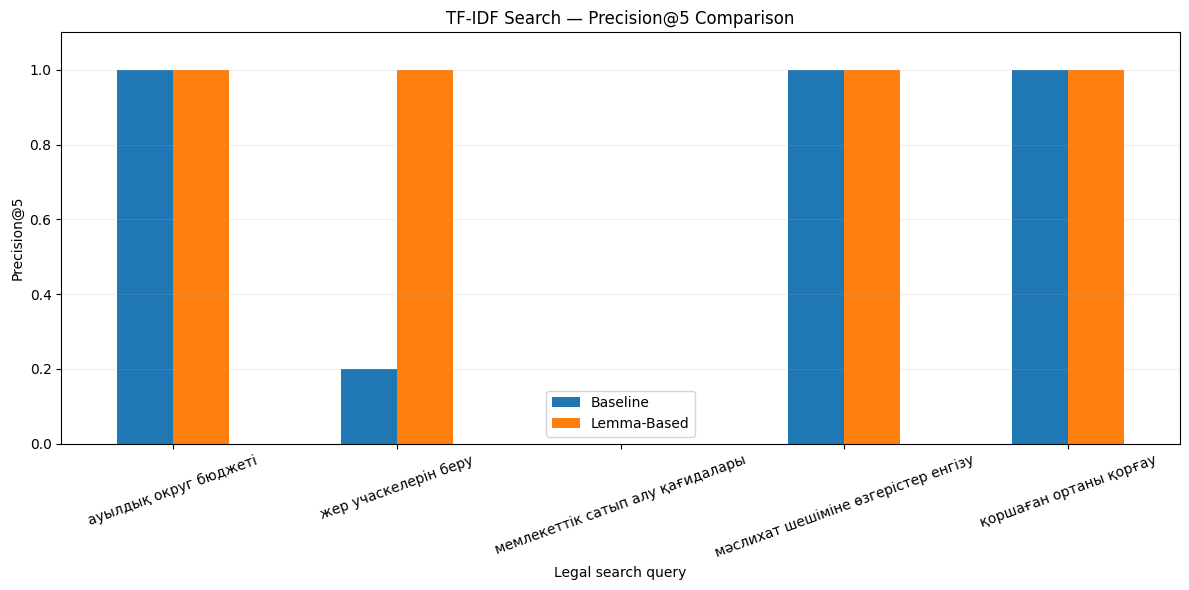


Total evaluated results: 50
Saved figure: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/tfidf_precision_comparison.png

FINAL PRECISION@5 EVALUATION COMPLETED


In [79]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 65)
print("FINAL TF-IDF PRECISION@5 EVALUATION")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

evaluation_path = (
    project_dir /
    "data/processed/tfidf_precision_at_5_review.csv"
)

evaluation_df = pd.read_csv(evaluation_path)

evaluation_df["relevant"] = pd.to_numeric(
    evaluation_df["relevant"], errors="coerce"
).astype("Int64")

evaluation_df["notes"] = (
    evaluation_df["notes"].astype("string")
)

remaining_queries = [
    "ауылдық округ бюджеті",
    "мәслихат шешіміне өзгерістер енгізу"
]

mask = evaluation_df["query"].isin(remaining_queries)

assert mask.sum() == 20, (
    "Expected 20 remaining evaluation rows"
)

evaluation_df.loc[mask, "relevant"] = 1
evaluation_df.loc[mask, "notes"] = (
    "Provisional title-based assessment"
)

assert len(evaluation_df) == 50
assert evaluation_df["relevant"].notna().all()
assert set(evaluation_df["relevant"].astype(int)).issubset({0, 1})

group_sizes = evaluation_df.groupby(
    ["query", "model"]
).size()

assert (group_sizes == 5).all(), (
    "Each query-model group must contain 5 results"
)

precision_df = (
    evaluation_df.groupby(["query", "model"])["relevant"]
    .mean()
    .reset_index(name="precision_at_5")
)

precision_df["precision_at_5"] = (
    precision_df["precision_at_5"].astype(float)
)

print("\nPRECISION@5 BY QUERY")

comparison = precision_df.pivot(
    index="query",
    columns="model",
    values="precision_at_5"
)

display(comparison)

mean_precision = (
    precision_df.groupby("model")["precision_at_5"]
    .mean()
    .reset_index(name="mean_precision_at_5")
)

print("\nMEAN PRECISION@5")
display(mean_precision)

processed_dir = project_dir / "data/processed"
figure_dir = project_dir / "outputs/figures"

figure_dir.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

precision_df.to_csv(
    processed_dir / "tfidf_precision_at_5_results.csv",
    index=False,
    encoding="utf-8-sig"
)

mean_precision.to_csv(
    processed_dir / "tfidf_mean_precision_at_5.csv",
    index=False,
    encoding="utf-8-sig"
)

ax = comparison.plot(
    kind="bar",
    figsize=(12, 6),
    rot=20
)

ax.set_title("TF-IDF Search — Precision@5 Comparison")
ax.set_ylabel("Precision@5")
ax.set_xlabel("Legal search query")
ax.set_ylim(0, 1.1)
ax.legend(["Baseline", "Lemma-Based"])
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

figure_path = figure_dir / "tfidf_precision_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTotal evaluated results:", len(evaluation_df))
print("Saved figure:", figure_path)
print("\nFINAL PRECISION@5 EVALUATION COMPLETED")

In [80]:
from pathlib import Path
import pandas as pd

print("=" * 65)
print("FINAL PROJECT — ARTIFACT AUDIT")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

required_files = {
    "Optimized corpus": "data/processed/kazakhlawcorpus_optimized.parquet",
    "Language classification": "data/processed/kazakhlawcorpus_language_classified.parquet",
    "Lemma mapping": "data/processed/kazstem_lemma_mapping.parquet",
    "SQLite database": "data/database/kazakh_legal_corpus.db",
    "Baseline vectorizer": "models/tfidf_vectorizer.joblib",
    "Baseline matrix": "models/tfidf_matrix.joblib",
    "Baseline documents": "models/tfidf_documents.parquet",
    "Lemma vectorizer": "models/lemma_tfidf_vectorizer.joblib",
    "Lemma matrix": "models/lemma_tfidf_matrix.joblib",
    "Lemma documents": "models/lemma_tfidf_documents.parquet",
    "Precision evaluation": "data/processed/tfidf_precision_at_5_review.csv",
    "Precision results": "data/processed/tfidf_precision_at_5_results.csv",
    "Mean precision": "data/processed/tfidf_mean_precision_at_5.csv",
    "Vocabulary figure": "outputs/figures/vocabulary_reduction.png",
    "TF-IDF comparison figure": "outputs/figures/tfidf_precision_comparison.png"
}

records = []

for label, relative_path in required_files.items():

    path = project_dir / relative_path

    records.append({
        "Artifact": label,
        "Exists": path.is_file(),
        "Size (MB)": (
            round(path.stat().st_size / 1024**2, 2)
            if path.is_file()
            else None
        ),
        "Path": relative_path
    })

artifact_df = pd.DataFrame(records)

display(artifact_df)

print("\nFILES FOUND:", artifact_df["Exists"].sum())
print("TOTAL CHECKED:", len(artifact_df))
print(
    "MISSING FILES:",
    (~artifact_df["Exists"]).sum()
)

print("\nARTIFACT AUDIT COMPLETED")

FINAL PROJECT — ARTIFACT AUDIT


,Artifact,Exists,Size (MB),Path
0,Optimized corpus,True,37.22,data/processed/kazakhlawcorpus_optimized.parquet
1,Language classification,True,38.12,data/processed/kazakhlawcorpus_language_classified.parquet
2,Lemma mapping,True,0.81,data/processed/kazstem_lemma_mapping.parquet
3,SQLite database,True,220.52,data/database/kazakh_legal_corpus.db
4,Baseline vectorizer,True,0.61,models/tfidf_vectorizer.joblib
5,Baseline matrix,True,26.52,models/tfidf_matrix.joblib
6,Baseline documents,True,15.91,models/tfidf_documents.parquet
7,Lemma vectorizer,True,0.37,models/lemma_tfidf_vectorizer.joblib
8,Lemma matrix,True,26.14,models/lemma_tfidf_matrix.joblib
9,Lemma documents,True,15.91,models/lemma_tfidf_documents.parquet



FILES FOUND: 15
TOTAL CHECKED: 15
MISSING FILES: 0

ARTIFACT AUDIT COMPLETED


In [81]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("=" * 65)
print("FINAL PROJECT — REQUIREMENTS")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

packages = [
    "pandas",
    "numpy",
    "pyarrow",
    "matplotlib",
    "scipy",
    "scikit-learn",
    "joblib",
    "langid",
    "kazstem"
]

requirements = []

for package in packages:
    try:
        installed_version = version(package)
        requirements.append(
            f"{package}=={installed_version}"
        )
        print(f"[FOUND] {package}=={installed_version}")

    except PackageNotFoundError:
        print(f"[MISSING] {package}")

requirements_path = project_dir / "requirements.txt"

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("REQUIREMENTS.TXT CONTENT")
print("=" * 65)

print(requirements_path.read_text())

print("Saved:", requirements_path)
print("\nREQUIREMENTS FILE CREATED")

FINAL PROJECT — REQUIREMENTS
[FOUND] pandas==2.2.3
[FOUND] numpy==2.4.6
[FOUND] pyarrow==23.0.1
[FOUND] matplotlib==3.10.0
[FOUND] scipy==1.16.3
[FOUND] scikit-learn==1.6.1
[FOUND] joblib==1.6.0
[FOUND] langid==1.1.6
[FOUND] kazstem==0.2.1

REQUIREMENTS.TXT CONTENT
pandas==2.2.3
numpy==2.4.6
pyarrow==23.0.1
matplotlib==3.10.0
scipy==1.16.3
scikit-learn==1.6.1
joblib==1.6.0
langid==1.1.6
kazstem==0.2.1

Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/requirements.txt

REQUIREMENTS FILE CREATED


In [82]:
import joblib
import pandas as pd
import numpy as np
import re
from pathlib import Path

print("=" * 65)
print("FINAL PROJECT — MODEL REPRODUCIBILITY TEST")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

model_dir = project_dir / "models"

baseline_vectorizer_test = joblib.load(
    model_dir / "tfidf_vectorizer.joblib"
)

baseline_matrix_test = joblib.load(
    model_dir / "tfidf_matrix.joblib"
)

lemma_vectorizer_test = joblib.load(
    model_dir / "lemma_tfidf_vectorizer.joblib"
)

lemma_matrix_test = joblib.load(
    model_dir / "lemma_tfidf_matrix.joblib"
)

baseline_docs_test = pd.read_parquet(
    model_dir / "tfidf_documents.parquet"
)

lemma_docs_test = pd.read_parquet(
    model_dir / "lemma_tfidf_documents.parquet"
)

lemma_mapping_test = pd.read_parquet(
    project_dir / "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_map_test = dict(
    zip(
        lemma_mapping_test["word"],
        lemma_mapping_test["lemma"]
    )
)

assert baseline_matrix_test.shape[0] == 215889
assert lemma_matrix_test.shape[0] == 215889

assert baseline_docs_test["law_id"].equals(
    lemma_docs_test["law_id"]
)

assert baseline_matrix_test.shape[1] == len(
    baseline_vectorizer_test.vocabulary_
)

assert lemma_matrix_test.shape[1] == len(
    lemma_vectorizer_test.vocabulary_
)

print("[PASSED] Model and document integrity checks")

pattern = re.compile(
    r"[а-яёәғқңөұүһі]+",
    re.IGNORECASE
)

test_query = "жер учаскелерін беру"

tokens = pattern.findall(test_query.lower())

lemma_tokens = [
    lemma_map_test.get(token, token)
    for token in tokens
]

query_text = " ".join(lemma_tokens)

query_vector = lemma_vectorizer_test.transform(
    [query_text]
)

scores = (
    lemma_matrix_test @ query_vector.T
).toarray().ravel()

top_indices = np.argsort(scores)[-5:][::-1]

results = lemma_docs_test.iloc[
    top_indices
][["law_id", "title"]].copy()

results["similarity"] = scores[top_indices]

print("\nTEST QUERY:", test_query)
print("NORMALIZED QUERY:", query_text)

print("\nTOP 5 RESULTS")
display(results.reset_index(drop=True))

assert scores[top_indices[0]] > 0, (
    "Search returned no positive similarity"
)

print("\n[PASSED] Saved TF-IDF model works")
print("\nMODEL REPRODUCIBILITY TEST COMPLETED")

FINAL PROJECT — MODEL REPRODUCIBILITY TEST
[PASSED] Model and document integrity checks

TEST QUERY: жер учаскелерін беру
NORMALIZED QUERY: жер учаске бер

TOP 5 RESULTS


,law_id,title,similarity
0,R2400000144,Жер учаскелерін берудің кейбір мәселелері туралы,0.798725
1,P1700000235,Қорғаныс мұқтажы үшін жер учаскесін беру туралы,0.652825
2,P1300000638,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,0.652825
3,P1100000548,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,0.652825
4,P1600000220,Қорғаныс мұқтажы үшін жер учаскелерін беру туралы,0.652825



[PASSED] Saved TF-IDF model works

MODEL REPRODUCIBILITY TEST COMPLETED


In [83]:
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

readme_content = """# Lexical Profile of Kazakh Legal Language

## Project Overview

This project explores the lexical and morphological
characteristics of Kazakh legal document metadata
using Python, Natural Language Processing (NLP),
SQL, and information retrieval techniques.

The analysis uses titles and descriptions of legal
documents, rather than full legislative texts.

## Dataset

- Documents: 215,889
- Source file: kazakhlawcorpus_kk_only.csv
- Original format: CSV
- Optimized format: Parquet
- Main text fields: title and description

The corpus contains legal document metadata
spanning multiple decades.

The dataset is predominantly Kazakh-language,
but some records may contain Russian or mixed-language
text. Language detection was preliminary and was
not fully manually validated.

## Technologies

- Python 3.13
- pandas and NumPy
- PyArrow and Parquet
- SQLite
- scikit-learn
- KazStem 0.2.1
- Matplotlib and SciPy

See requirements.txt for installed package versions.

## Methods

### 1. Data Preparation

- Dataset inspection
- Missing-value analysis
- Duplicate analysis
- Unicode normalization
- CSV-to-Parquet conversion
- Memory and reading performance comparison

### 2. Lexical Analysis

- Cyrillic tokenization
- Word frequency analysis
- Stopword analysis
- Zipf's Law
- Bigram and trigram analysis
- Temporal lexical analysis

### 3. Morphological Analysis

KazStem was used for conservative morphological
normalization.

When a token had one unique candidate lemma,
that lemma was selected.

When multiple candidate lemmas were returned,
the original token was retained.

### 4. SQL Analysis

A SQLite database was created containing
215,889 legal documents.

Eight SQL queries demonstrate filtering,
aggregation, conditional classification,
common table expressions, and joins.

### 5. TF-IDF Information Retrieval

Two search models were developed:

- Baseline TF-IDF
- Lemma-based TF-IDF

Both models index legal document titles.

Retrieval uses cosine similarity.

## Main Results

### Tokenization

- Title tokens: 3,965,957
- Description tokens: 3,681,040
- Combined occurrences: 7,646,997

### Vocabulary Reduction

| Corpus | Original | Normalized | Reduction |
|---|---:|---:|---:|
| Titles | 34,361 | 22,944 | 33.23% |
| Descriptions | 4,476 | 3,912 | 12.60% |
| Combined | 35,523 | 23,967 | 32.53% |

### TF-IDF Features

- Baseline: 22,732 features
- Lemma-based: 14,535 features
- Feature reduction: 36.06%

### Search Evaluation

Preliminary mean Precision@5 across five
selected legal queries:

- Baseline TF-IDF: 0.64
- Lemma-based TF-IDF: 0.80

The reported relevance judgments were based
primarily on document titles.

## Limitations

1. The dataset contains document titles and
   descriptions, not full legislative texts.

2. Language classification has not undergone
   complete manual verification.

3. Cyrillic tokenization removes digits and
   punctuation, which can affect n-grams.

4. Morphological normalization can introduce
   errors, especially for proper names and
   ambiguous word forms.

5. The 50-form lemmatization audit was prepared,
   but its formal accuracy metric has not been
   finalized.

6. Search evaluation uses only five queries and
   preliminary title-based relevance judgments.

7. Temporal patterns may reflect changes in
   corpus composition and document coverage.

## Reproducibility

Python dependencies are listed in requirements.txt.

The optimized dataset, SQLite database, TF-IDF
models, lemma mapping, and evaluation results
are stored in the project directory.

The saved TF-IDF models were successfully
reloaded and tested in the existing Colab
environment.

KazStem requires additional FST resources
not installed through pip alone.

For KazStem 0.2.1, the matching Ubuntu 24.04
release bundle was downloaded and its SHA-256
checksum verified before resource extraction.

A complete fresh-environment reproduction
test has not yet been performed.

## Project Structure

data/
  raw/
  processed/
  database/

models/

outputs/
  figures/

requirements.txt
README.md

## Conclusion

Morphological normalization substantially
reduces the feature space of Kazakh legal
document representations.

In the preliminary search evaluation,
lemma-based TF-IDF achieved higher mean
Precision@5 than the baseline model.

These findings motivate further evaluation
with more queries, independent relevance
judgments, and additional linguistic validation.
"""

readme_path = project_dir / "README.md"

readme_path.write_text(
    readme_content,
    encoding="utf-8"
)

print("=" * 60)
print("README CREATED")
print("=" * 60)

print("Path:", readme_path)
print("Characters:", len(readme_content))
print("Exists:", readme_path.is_file())

print("\nREADME PREVIEW:")
print(readme_content[:1200])

README CREATED
Path: /content/drive/MyDrive/Kazakh_Legal_Language_Project/README.md
Characters: 4421
Exists: True

README PREVIEW:
# Lexical Profile of Kazakh Legal Language

## Project Overview

This project explores the lexical and morphological
characteristics of Kazakh legal document metadata
using Python, Natural Language Processing (NLP),
SQL, and information retrieval techniques.

The analysis uses titles and descriptions of legal
documents, rather than full legislative texts.

## Dataset

- Documents: 215,889
- Source file: kazakhlawcorpus_kk_only.csv
- Original format: CSV
- Optimized format: Parquet
- Main text fields: title and description

The corpus contains legal document metadata
spanning multiple decades.

The dataset is predominantly Kazakh-language,
but some records may contain Russian or mixed-language
text. Language detection was preliminary and was
not fully manually validated.

## Technologies

- Python 3.13
- pandas and NumPy
- PyArrow and Parquet
- SQLite
- scik

In [84]:
from pathlib import Path
import pandas as pd
import sqlite3

print("=" * 65)
print("FINAL PROJECT — POST-RUN VALIDATION")
print("=" * 65)

project = Path(
    "/content/drive/MyDrive/"
    "Kazakh_Legal_Language_Project"
)

required_files = [
    "data/processed/kazakhlawcorpus_optimized.parquet",
    "data/processed/kazakhlawcorpus_language_classified.parquet",
    "data/processed/kazstem_lemma_mapping.parquet",
    "data/database/kazakh_legal_corpus.db",
    "models/tfidf_vectorizer.joblib",
    "models/tfidf_matrix.joblib",
    "models/lemma_tfidf_vectorizer.joblib",
    "models/lemma_tfidf_matrix.joblib",
    "data/processed/tfidf_precision_at_5_results.csv",
    "outputs/figures/tfidf_precision_comparison.png",
    "requirements.txt",
    "README.md"
]

missing = []

print("\nREQUIRED ARTIFACTS")

for relative_path in required_files:
    path = project / relative_path

    if path.is_file() and path.stat().st_size > 0:
        print("[PASSED]", relative_path)
    else:
        print("[MISSING]", relative_path)
        missing.append(relative_path)

parquet_path = (
    project / "data/processed/"
    "kazakhlawcorpus_optimized.parquet"
)

if parquet_path.is_file():
    import pyarrow.parquet as pq

    rows = pq.ParquetFile(parquet_path).metadata.num_rows
    print("\nPARQUET DOCUMENTS:", rows)
    assert rows == 215889

db_path = project / "data/database/kazakh_legal_corpus.db"

if db_path.is_file():
    conn = sqlite3.connect(db_path)

    try:
        count = conn.execute(
            "SELECT COUNT(*) FROM legal_documents"
        ).fetchone()[0]
    finally:
        conn.close()

    print("SQLITE DOCUMENTS:", count)
    assert count == 215889

evaluation_path = (
    project / "data/processed/"
    "tfidf_mean_precision_at_5.csv"
)

if evaluation_path.is_file():
    print("\nMEAN PRECISION@5 RESULTS")
    display(pd.read_csv(evaluation_path))

print("\nMISSING ARTIFACTS:", len(missing))

if not missing:
    print("[PASSED] ALL REQUIRED ARTIFACTS PRESENT")
else:
    print("[WARNING] Some artifacts are missing")

print("\nPOST-RUN VALIDATION COMPLETED")

FINAL PROJECT — POST-RUN VALIDATION

REQUIRED ARTIFACTS
[PASSED] data/processed/kazakhlawcorpus_optimized.parquet
[PASSED] data/processed/kazakhlawcorpus_language_classified.parquet
[PASSED] data/processed/kazstem_lemma_mapping.parquet
[PASSED] data/database/kazakh_legal_corpus.db
[PASSED] models/tfidf_vectorizer.joblib
[PASSED] models/tfidf_matrix.joblib
[PASSED] models/lemma_tfidf_vectorizer.joblib
[PASSED] models/lemma_tfidf_matrix.joblib
[PASSED] data/processed/tfidf_precision_at_5_results.csv
[PASSED] outputs/figures/tfidf_precision_comparison.png
[PASSED] requirements.txt
[PASSED] README.md

PARQUET DOCUMENTS: 215889
SQLITE DOCUMENTS: 215889

MEAN PRECISION@5 RESULTS


,model,mean_precision_at_5
0,baseline,0.64
1,lemma_based,0.80



MISSING ARTIFACTS: 0
[PASSED] ALL REQUIRED ARTIFACTS PRESENT

POST-RUN VALIDATION COMPLETED


In [85]:
import re
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("KAZAKH LEGAL DOCUMENT SEARCH SYSTEM")
print("=" * 65)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

MODEL_DIR = PROJECT_DIR / "models"

pattern = re.compile(
    r"[а-яёәғқңөұүһі]+",
    re.IGNORECASE
)

models = {}

for name, prefix in [
    ("Baseline", "tfidf"),
    ("Lemma-based", "lemma_tfidf")
]:
    models[name] = {
        "vectorizer": joblib.load(
            MODEL_DIR / f"{prefix}_vectorizer.joblib"
        ),
        "matrix": joblib.load(
            MODEL_DIR / f"{prefix}_matrix.joblib"
        ),
        "documents": pd.read_parquet(
            MODEL_DIR / f"{prefix}_documents.parquet"
        )
    }

lemma_df = pd.read_parquet(
    PROJECT_DIR / "data/processed/kazstem_lemma_mapping.parquet"
)

lemma_map = dict(zip(lemma_df["word"], lemma_df["lemma"]))


def preprocess_query(query, use_lemmas=False):
    tokens = pattern.findall(query.lower())

    if use_lemmas:
        tokens = [lemma_map.get(t, t) for t in tokens]

    return " ".join(tokens)


def search_legal_documents(query, model_name="Lemma-based", top_k=5):
    model = models[model_name]

    cleaned = preprocess_query(
        query,
        use_lemmas=(model_name == "Lemma-based")
    )

    query_vector = model["vectorizer"].transform([cleaned])

    if query_vector.nnz == 0:
        print("No matching terms in the model vocabulary.")
        return pd.DataFrame()

    scores = (
        model["matrix"] @ query_vector.T
    ).toarray().ravel()

    candidates = np.flatnonzero(scores > 0)

    if len(candidates) == 0:
        print("No matching documents found.")
        return pd.DataFrame()

    k = min(top_k, len(candidates))

    positions = np.argpartition(
        scores[candidates], -k
    )[-k:]

    indices = candidates[positions]
    indices = indices[np.argsort(-scores[indices], kind="stable")]

    results = model["documents"].iloc[indices].copy()
    results["similarity"] = np.round(scores[indices], 4)

    return results.reset_index(drop=True)


def display_search_results(query, model_name, top_k=5):
    results = search_legal_documents(query, model_name, top_k)

    if not results.empty:
        print(f"\nQuery: {query}")
        print(f"Model: {model_name}")
        print(f"Documents found: {len(results)}")
        display(results)

    return results


def main():
    while True:
        print("\n" + "=" * 55)
        print("KAZAKH LEGAL DOCUMENT SEARCH")
        print("=" * 55)
        print("1. Search with Baseline TF-IDF")
        print("2. Search with Lemma-based TF-IDF")
        print("3. Compare both models")
        print("4. Exit")

        choice = input("\nChoose an option (1-4): ").strip()

        if choice == "4":
            print("Search session finished.")
            break

        if choice not in ["1", "2", "3"]:
            print("Invalid option. Choose 1, 2, 3 or 4.")
            continue

        query = input("Enter a legal search query: ").strip()

        if not query:
            print("Query cannot be empty.")
            continue

        try:
            k_text = input(
                "Number of results (1-20, default 5): "
            ).strip()

            top_k = int(k_text) if k_text else 5

            if not 1 <= top_k <= 20:
                print("Number must be between 1 and 20.")
                continue

            if choice == "1":
                display_search_results(query, "Baseline", top_k)

            elif choice == "2":
                display_search_results(query, "Lemma-based", top_k)

            elif choice == "3":
                print("\nBASELINE RESULTS")
                display_search_results(query, "Baseline", top_k)

                print("\nLEMMA-BASED RESULTS")
                display_search_results(query, "Lemma-based", top_k)

        except ValueError:
            print("Please enter a valid number.")

        except (OSError, FileNotFoundError) as e:
            print("File access error:", e)

    return None


print("\n[PASSED] Search system loaded")
print("Models:", list(models.keys()))
print("Indexed documents:", len(models["Baseline"]["documents"]))

main()

KAZAKH LEGAL DOCUMENT SEARCH SYSTEM

[PASSED] Search system loaded
Models: ['Baseline', 'Lemma-based']
Indexed documents: 215889

KAZAKH LEGAL DOCUMENT SEARCH
1. Search with Baseline TF-IDF
2. Search with Lemma-based TF-IDF
3. Compare both models
4. Exit

Choose an option (1-4): 2
Enter a legal search query: Қазақстан
Number of results (1-20, default 5): 5

Query: Қазақстан
Model: Lemma-based
Documents found: 5


,law_id,title,similarity
0,U2300000158,Қазақстан Республикасының Үкіметі туралы,0.4337
1,U2200000728,Қазақстан Республикасының Үкіметі туралы,0.4337
2,U2100000491,Қазақстан Республикасының Үкіметі туралы,0.4337
3,U1900000845,Қазақстан Республикасының Үкіметі туралы,0.4337
4,U1500000001,Қазақстан Республикасының Үкіметі туралы,0.4337



KAZAKH LEGAL DOCUMENT SEARCH
1. Search with Baseline TF-IDF
2. Search with Lemma-based TF-IDF
3. Compare both models
4. Exit

Choose an option (1-4): 3
Enter a legal search query: Қазақстан
Number of results (1-20, default 5): 5

BASELINE RESULTS

Query: Қазақстан
Model: Baseline
Documents found: 5


,law_id,title,similarity
0,U2100000491,Қазақстан Республикасының Үкіметі туралы,0.3183
1,U2400000446,Қазақстан Республикасының Үкіметі туралы,0.3183
2,Z950002688_,Қазақстан Республикасының Үкіметі туралы,0.3183
3,U2200000728,Қазақстан Республикасының Үкіметі туралы,0.3183
4,U1900000845,Қазақстан Республикасының Үкіметі туралы,0.3183



LEMMA-BASED RESULTS

Query: Қазақстан
Model: Lemma-based
Documents found: 5


,law_id,title,similarity
0,U2300000158,Қазақстан Республикасының Үкіметі туралы,0.4337
1,U2200000728,Қазақстан Республикасының Үкіметі туралы,0.4337
2,U2100000491,Қазақстан Республикасының Үкіметі туралы,0.4337
3,U1900000845,Қазақстан Республикасының Үкіметі туралы,0.4337
4,U1500000001,Қазақстан Республикасының Үкіметі туралы,0.4337



KAZAKH LEGAL DOCUMENT SEARCH
1. Search with Baseline TF-IDF
2. Search with Lemma-based TF-IDF
3. Compare both models
4. Exit

Choose an option (1-4): 4
Search session finished.


In [86]:
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

src = project / "src"
src.mkdir(parents=True, exist_ok=True)

search_code = r'''
import re
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

PATTERN = re.compile(r"[а-яёәғқңөұүһі]+", re.IGNORECASE)


def load_search_system(project_dir):
    project_dir = Path(project_dir)
    model_dir = project_dir / "models"

    models = {}

    for name, prefix in [
        ("Baseline", "tfidf"),
        ("Lemma-based", "lemma_tfidf")
    ]:
        models[name] = {
            "vectorizer": joblib.load(
                model_dir / f"{prefix}_vectorizer.joblib"
            ),
            "matrix": joblib.load(
                model_dir / f"{prefix}_matrix.joblib"
            ),
            "documents": pd.read_parquet(
                model_dir / f"{prefix}_documents.parquet"
            )
        }

    mapping = pd.read_parquet(
        project_dir / "data/processed/kazstem_lemma_mapping.parquet"
    )

    lemma_map = dict(zip(mapping["word"], mapping["lemma"]))

    return models, lemma_map


def preprocess_query(query, lemma_map, use_lemmas=False):
    tokens = PATTERN.findall(query.lower())

    if use_lemmas:
        tokens = [lemma_map.get(token, token) for token in tokens]

    return " ".join(tokens)


def search_documents(query, models, lemma_map,
                     model_name="Lemma-based", top_k=5):

    if model_name not in models:
        raise ValueError("Unknown model")

    if not 1 <= top_k <= 20:
        raise ValueError("top_k must be between 1 and 20")

    model = models[model_name]

    cleaned = preprocess_query(
        query,
        lemma_map,
        model_name == "Lemma-based"
    )

    query_vector = model["vectorizer"].transform([cleaned])

    if query_vector.nnz == 0:
        return pd.DataFrame()

    scores = (model["matrix"] @ query_vector.T).toarray().ravel()
    candidates = np.flatnonzero(scores > 0)

    if len(candidates) == 0:
        return pd.DataFrame()

    k = min(top_k, len(candidates))

    selected = np.argpartition(
        scores[candidates], -k
    )[-k:]

    indices = candidates[selected]
    indices = indices[np.argsort(-scores[indices], kind="stable")]

    results = model["documents"].iloc[indices].copy()
    results["similarity"] = np.round(scores[indices], 4)

    return results.reset_index(drop=True)
'''

main_code = r'''
from pathlib import Path
from search import load_search_system, search_documents

PROJECT_DIR = Path(__file__).resolve().parent.parent


def main():
    models, lemma_map = load_search_system(PROJECT_DIR)

    while True:
        print("\nKAZAKH LEGAL DOCUMENT SEARCH")
        print("1. Baseline TF-IDF")
        print("2. Lemma-based TF-IDF")
        print("3. Compare both models")
        print("4. Exit")

        choice = input("Choose option (1-4): ").strip()

        if choice == "4":
            print("Goodbye!")
            break

        if choice not in ("1", "2", "3"):
            print("Invalid option")
            continue

        query = input("Enter legal search query: ").strip()

        if not query:
            print("Query cannot be empty")
            continue

        try:
            value = input("Top K (1-20, default 5): ").strip()
            top_k = int(value) if value else 5

            if not 1 <= top_k <= 20:
                raise ValueError("Top K out of range")

            names = (
                ["Baseline", "Lemma-based"]
                if choice == "3"
                else ["Baseline" if choice == "1" else "Lemma-based"]
            )

            for name in names:
                result = search_documents(
                    query, models, lemma_map, name, top_k
                )

                print(f"\n{name} RESULTS")
                print(result.to_string(index=False)
                      if not result.empty else "No matches")

        except ValueError as exc:
            print("Input error:", exc)

        except (OSError, FileNotFoundError) as exc:
            print("File access error:", exc)


if __name__ == "__main__":
    main()
'''

files = {
    "search.py": search_code,
    "main.py": main_code
}

for filename, content in files.items():
    path = src / filename

    if path.exists():
        raise FileExistsError(
            f"{filename} already exists. No file overwritten."
        )

for filename, content in files.items():
    path = src / filename
    path.write_text(content.lstrip(), encoding="utf-8")
    print("[PASSED]", path)

print("\nSEARCH MODULES CREATED")

[PASSED] /content/drive/MyDrive/Kazakh_Legal_Language_Project/src/search.py
[PASSED] /content/drive/MyDrive/Kazakh_Legal_Language_Project/src/main.py

SEARCH MODULES CREATED


In [87]:
import subprocess
import sys
from pathlib import Path

print("=" * 65)
print("FINAL PROJECT — PYTHON MODULE TEST")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

main_path = project_dir / "src/main.py"
search_path = project_dir / "src/search.py"

assert main_path.is_file(), "main.py not found"
assert search_path.is_file(), "search.py not found"

print("[PASSED] Python modules found")

result = subprocess.run(
    [sys.executable, str(main_path)],
    input="3\nжер учаскелерін беру\n5\n4\n",
    text=True,
    capture_output=True,
    timeout=180,
    cwd=str(project_dir)
)

print("\nPROGRAM OUTPUT")
print(result.stdout[-10000:])

if result.stderr:
    print("\nERROR OUTPUT")
    print(result.stderr[-4000:])

assert result.returncode == 0, (
    f"Program failed with exit code {result.returncode}"
)

assert "Baseline RESULTS" in result.stdout
assert "Lemma-based RESULTS" in result.stdout
assert "Goodbye!" in result.stdout

print("\n[PASSED] Both search models executed")
print("[PASSED] Interactive menu completed")
print("[PASSED] Python modules work independently")

print("\nPYTHON MODULE TEST COMPLETED")

FINAL PROJECT — PYTHON MODULE TEST
[PASSED] Python modules found

PROGRAM OUTPUT

KAZAKH LEGAL DOCUMENT SEARCH
1. Baseline TF-IDF
2. Lemma-based TF-IDF
3. Compare both models
4. Exit
Choose option (1-4): Enter legal search query: Top K (1-20, default 5): 
Baseline RESULTS
     law_id                                            title  similarity
P1200000575                  Жер учаскелерін ауыстыру туралы      0.6464
P1000001214                  Жер учаскелерін ауыстыру туралы      0.6464
U950002717_                                       Жер туралы      0.5869
Z010000152_                                       Жер туралы      0.5869
R2400000144 Жер учаскелерін берудің кейбір мәселелері туралы      0.5699

Lemma-based RESULTS
     law_id                                             title  similarity
R2400000144  Жер учаскелерін берудің кейбір мәселелері туралы      0.7987
P1100001361   Қорғаныс мұқтажы үшін жер учаскесін беру туралы      0.6528
P1100000548 Қорғаныс мұқтажы үшін жер учаскеле

In [88]:
import pandas as pd
import sqlite3
from pathlib import Path

print("=" * 65)
print("FINAL PROJECT — DATABASE NORMALIZATION INSPECTION")
print("=" * 65)

project = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

parquet_path = (
    project / "data/processed/kazakhlawcorpus_optimized.parquet"
)

db_path = (
    project / "data/database/kazakh_legal_corpus.db"
)

assert parquet_path.is_file()
assert db_path.is_file()

df = pd.read_parquet(
    parquet_path,
    columns=[
        "law_id",
        "source_id",
        "legal_relation_area"
    ]
)

print("\nDATASET SHAPE:", df.shape)

print("\nLEGAL RELATION AREA — SAMPLE VALUES")
display(
    df[["law_id", "legal_relation_area"]]
    .dropna()
    .head(15)
)

print("\nAREA DATA TYPES")
print(
    df["legal_relation_area"]
    .map(lambda x: type(x).__name__)
    .value_counts()
)

print("\nMISSING AREA VALUES")
print(df["legal_relation_area"].isna().sum())

print("\nMOST FREQUENT AREA VALUES")
display(
    df["legal_relation_area"]
    .astype(str)
    .value_counts()
    .head(15)
)

print("\nSOURCE ID")
print("Unique:", df["source_id"].nunique())
print("Missing:", df["source_id"].isna().sum())

with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master "
        "WHERE type='table' ORDER BY name",
        conn
    )

print("\nEXISTING SQLITE TABLES")
display(tables)

print("\nDATABASE NORMALIZATION INSPECTION COMPLETED")

FINAL PROJECT — DATABASE NORMALIZATION INSPECTION

DATASET SHAPE: (215889, 3)

LEGAL RELATION AREA — SAMPLE VALUES


,law_id,legal_relation_area
0,A04C0000417,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
1,A05I0001722,"Су көлігі, Көліктегі қауіпсіздік, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
2,A06C0001819,Ішкі істер органдары. Жол полициясы
3,A06G0002831,"Зейнетақы қорлары. Әлеуметтік қорғау қорлары, Зейнетақымен қамсыздандыру. Мемлекеттік әлеуметтік жәрдемақылар. Мемлекеттік арнаулы жәрдемақылар, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
4,A07C0001814,"Қоғамдық тәртіпті қорғау және құқық бұзушылыққа қарсы күрес, Табиғи ортаны қорғаудың жалпы мәселелері. Экологиялық бақылау. Экологиялық апат аймақтары, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
5,A07G0002789,"Зейнетақы қорлары. Әлеуметтік қорғау қорлары, Әлеуметтік қамсыздандыру бойынша жәрдемақылар (еңбекке уақытша жарамсыздығы бойынша, жүктілігі және босануы бойынша және т.б.). Арнаулы мемлекеттік жәрдемақылар, Республикалық және жергілікті бюджеттердің шығыстары, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
6,A07G0002825,Еңбек
7,A08D0000133,"Сот. Әділет. Прокуратура, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
8,A08KN001768,"Еңбек тәртібі, Нысандық киім, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"
9,A09B0001805,"Еңбек стажы, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу"



AREA DATA TYPES
legal_relation_area
str       215584
NAType       305
Name: count, dtype: int64

MISSING AREA VALUES
305

MOST FREQUENT AREA VALUES


,count
legal_relation_area,
"Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",20653
Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер,11306
"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер",7751
"Қаржы, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",4578
"Қаржы, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер",4207
"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",3490
Жергілікті өкілетті және атқарушы органдар,2938
Халықты жұмысқа орналастыру және жұмыспен қамту,2651
ЕурАзЭҚ. Кедендік одақ. ЕАЭО,2388



SOURCE ID
Unique: 215889
Missing: 0

EXISTING SQLITE TABLES


,name
0,legal_documents



DATABASE NORMALIZATION INSPECTION COMPLETED


In [89]:
import pandas as pd
import sqlite3
from pathlib import Path

print("=" * 65)
print("FINAL PROJECT — LEGAL AREA NORMALIZATION AUDIT")
print("=" * 65)

project = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

df = pd.read_parquet(
    project / "data/processed/kazakhlawcorpus_optimized.parquet",
    columns=["law_id", "legal_relation_area"]
)

areas = df["legal_relation_area"].dropna().astype(str).str.strip()

print("\nAREA STATISTICS")
print("Non-missing records:", len(areas))
print("Distinct raw area strings:", areas.nunique())
print("Records containing commas:", areas.str.contains(",", regex=False).sum())
print("Records containing semicolons:", areas.str.contains(";", regex=False).sum())

print("\nCOMMON INDIVIDUAL AREA STRINGS")

single_candidates = areas[
    ~areas.str.contains(",", regex=False)
]

display(single_candidates.value_counts().head(20).rename_axis("area").reset_index(name="count"))

print("\nCOMMON COMMA-CONTAINING STRINGS")

display(
    areas[areas.str.contains(",", regex=False)]
    .value_counts()
    .head(10)
    .rename_axis("raw_area")
    .reset_index(name="count")
)

print("\nEXISTING SQLITE TABLES")

db_path = project / "data/database/kazakh_legal_corpus.db"

with sqlite3.connect(db_path) as conn:
    existing_tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master "
        "WHERE type='table' ORDER BY name",
        conn
    )

display(existing_tables)

print("\nLEGAL AREA NORMALIZATION AUDIT COMPLETED")

FINAL PROJECT — LEGAL AREA NORMALIZATION AUDIT

AREA STATISTICS
Non-missing records: 215584
Distinct raw area strings: 25284
Records containing commas: 166658
Records containing semicolons: 0

COMMON INDIVIDUAL AREA STRINGS


,area,count
0,Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер,11306
1,Жергілікті өкілетті және атқарушы органдар,2938
2,Халықты жұмысқа орналастыру және жұмыспен қамту,2651
3,ЕурАзЭҚ. Кедендік одақ. ЕАЭО,2388
4,Конституциялық құрылыс және мемлекеттік басқару негіздері,1528
5,Өтемақылар және өзге әлеуметтік төлемдер,1494
6,Әлеуметтік қамсыздандыру. Сақтандыру,1366
7,Республикалық және жергілікті бюджеттердің кірістері. Салықтар,1255
8,Сайлау жүйесі. Сайлау,1226
9,Ауыл шаруашылығы,1131



COMMON COMMA-CONTAINING STRINGS


,raw_area,count
0,"Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",20653
1,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер",7751
2,"Қаржы, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",4578
3,"Қаржы, Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер",4207
4,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",3490
5,"Конституциялық құрылыс және мемлекеттік басқару негіздері, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",2361
6,"Әкімшілік-аумақтық бірліктердің, елді мекендердің құрама бөліктерінің атаулары, қайта атаулары",2130
7,"Халықаралық шарттар, келісімдер және конвенциялар",1454
8,"Жергілікті өкілетті және атқарушы органдар, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",1438
9,"Өтемақылар және өзге әлеуметтік төлемдер, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",1169



EXISTING SQLITE TABLES


,name
0,legal_documents



LEGAL AREA NORMALIZATION AUDIT COMPLETED


In [90]:
import sqlite3
import shutil
from pathlib import Path
from functools import lru_cache
from collections import Counter

print("=" * 65)
print("FINAL PROJECT — NORMALIZED SQLITE DATABASE")
print("=" * 65)

project = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

source_db = (
    project / "data/database/kazakh_legal_corpus.db"
)

output_db = (
    project / "data/database/kazakh_legal_corpus_normalized.db"
)

local_db = Path("/content/kazakh_legal_corpus_normalized.db")

assert source_db.is_file()
assert not output_db.exists(), "Normalized database already exists"
assert not local_db.exists(), "Temporary database already exists"

with sqlite3.connect(source_db) as source:
    with sqlite3.connect(local_db) as target:
        source.backup(target)

print("[PASSED] Original database copied locally")

conn = sqlite3.connect(local_db)

try:
    conn.execute("PRAGMA foreign_keys = ON")

    conn.executescript("""
    CREATE TABLE legal_areas (
        area_id INTEGER PRIMARY KEY,
        area_name TEXT NOT NULL UNIQUE
    );

    CREATE TABLE document_areas (
        law_id TEXT NOT NULL,
        area_id INTEGER NOT NULL,
        PRIMARY KEY (law_id, area_id),
        FOREIGN KEY (law_id)
            REFERENCES legal_documents(law_id),
        FOREIGN KEY (area_id)
            REFERENCES legal_areas(area_id)
    );

    CREATE TABLE unresolved_area_strings (
        law_id TEXT PRIMARY KEY,
        raw_area TEXT NOT NULL,
        reason TEXT NOT NULL,
        FOREIGN KEY (law_id)
            REFERENCES legal_documents(law_id)
    );
    """)

    records = conn.execute(
        "SELECT law_id, legal_relation_area "
        "FROM legal_documents"
    ).fetchall()

    raw_counts = Counter(
        str(area).strip()
        for _, area in records
        if area is not None and str(area).strip()
    )

    known_areas = {
        area for area in raw_counts
        if ", " not in area
    }

    known_areas.update({
        (
            "Нормативтік құқықтық актілер: дайындау, "
            "қабылдау, өзгерту, жариялау, түсіндіру, "
            "мемлекеттік есепке алу"
        ),
        (
            "Әкімшілік-аумақтық бірліктердің, "
            "елді мекендердің құрама бөліктерінің "
            "атаулары, қайта атаулары"
        ),
        "Халықаралық шарттар, келісімдер және конвенциялар"
    })

    @lru_cache(maxsize=None)
    def parse_areas(raw):
        if raw in known_areas:
            return (raw,)

        parts = raw.split(", ")
        n = len(parts)

        @lru_cache(maxsize=None)
        def solve(start):
            if start == n:
                return [()]

            solutions = []

            for end in range(start + 1, n + 1):
                candidate = ", ".join(parts[start:end])

                if candidate not in known_areas:
                    continue

                for remainder in solve(end):
                    solutions.append(
                        (candidate,) + remainder
                    )

                    if len(solutions) >= 2:
                        return solutions

            return solutions

        solutions = solve(0)

        if len(solutions) == 1:
            return solutions[0]

        return None

    parsed_documents = []
    unresolved = []
    status = Counter()

    for law_id, raw_area in records:

        if raw_area is None or not str(raw_area).strip():
            status["missing"] += 1
            continue

        raw = str(raw_area).strip()
        parsed = parse_areas(raw)

        if parsed is None:
            unresolved.append(
                (law_id, raw, "No unique exact segmentation")
            )
            status["unresolved"] += 1
        else:
            parsed_documents.append((law_id, parsed))
            status["resolved"] += 1

    used_areas = sorted({
        area
        for _, areas in parsed_documents
        for area in areas
    })

    conn.executemany(
        "INSERT INTO legal_areas(area_name) VALUES (?)",
        [(area,) for area in used_areas]
    )

    area_ids = dict(
        conn.execute(
            "SELECT area_name, area_id FROM legal_areas"
        ).fetchall()
    )

    links = [
        (law_id, area_ids[area])
        for law_id, areas in parsed_documents
        for area in set(areas)
    ]

    conn.executemany(
        "INSERT INTO document_areas(law_id, area_id) "
        "VALUES (?, ?)",
        links
    )

    conn.executemany(
        "INSERT INTO unresolved_area_strings "
        "(law_id, raw_area, reason) VALUES (?, ?, ?)",
        unresolved
    )

    conn.execute(
        "CREATE INDEX idx_document_areas_area "
        "ON document_areas(area_id)"
    )

    conn.commit()

    print("\nNORMALIZATION RESULTS")
    print("Total documents:", len(records))
    print("Resolved documents:", status["resolved"])
    print("Unresolved documents:", status["unresolved"])
    print("Missing area values:", status["missing"])
    print("Unique recognized areas:", len(used_areas))
    print("Document-area relationships:", len(links))

    assert sum(status.values()) == len(records)

    foreign_key_issues = conn.execute(
        "PRAGMA foreign_key_check"
    ).fetchall()

    assert not foreign_key_issues
    print("[PASSED] Foreign keys validated")

    print("\nDATABASE TABLES")
    for name, in conn.execute(
        "SELECT name FROM sqlite_master "
        "WHERE type='table' ORDER BY name"
    ):
        print("-", name)

finally:
    conn.close()

temporary_output = output_db.with_suffix(".pending")

assert not temporary_output.exists()

shutil.copy2(local_db, temporary_output)
temporary_output.rename(output_db)

print("\n[PASSED] Normalized database created")
print("Saved:", output_db)
print(
    "Size (MB):",
    round(output_db.stat().st_size / 1024**2, 2)
)

print("\nNORMALIZED SQLITE DATABASE COMPLETED")

FINAL PROJECT — NORMALIZED SQLITE DATABASE
[PASSED] Original database copied locally

NORMALIZATION RESULTS
Total documents: 215889
Resolved documents: 183159
Unresolved documents: 32425
Missing area values: 305
Unique recognized areas: 271
Document-area relationships: 352007
[PASSED] Foreign keys validated

DATABASE TABLES
- document_areas
- legal_areas
- legal_documents
- unresolved_area_strings

[PASSED] Normalized database created
Saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/data/database/kazakh_legal_corpus_normalized.db
Size (MB): 251.55

NORMALIZED SQLITE DATABASE COMPLETED


FINAL PROJECT — ER DIAGRAM AND SQL ANALYSIS

SQL QUERY RESULTS

------------------------------------------------------------
Q1 — Top legal areas


,area_name,documents
0,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",94812
1,Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер,52135
2,Қаржы,14016
3,Жергілікті өкілетті және атқарушы органдар,11905
4,Конституциялық құрылыс және мемлекеттік басқару негіздері,8859
5,Әлеуметтік қамсыздандыру. Сақтандыру,7193
6,Өтемақылар және өзге әлеуметтік төлемдер,6868
7,Халықты жұмысқа орналастыру және жұмыспен қамту,5589
8,Мемлекеттік қызметтер. Мемлекеттік қызметтер көрсетудің стандарттары,5267
9,Республикалық және жергілікті бюджеттердің кірістері. Салықтар,5023



------------------------------------------------------------
Q2 — Legal areas by decade


,decade,area_name,documents
0,2020,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",46023
1,2020,Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер,33375
2,2020,Қаржы,9480
3,2020,Жергілікті өкілетті және атқарушы органдар,5531
4,2020,Конституциялық құрылыс және мемлекеттік басқару негіздері,3983
5,2020,Әлеуметтік қамсыздандыру. Сақтандыру,3212
6,2020,Өтемақылар және өзге әлеуметтік төлемдер,2764
7,2020,Мемлекеттік басқарудың өзге мәселелері,2309
8,2020,Ауыл шаруашылығы,2037
9,2020,Республикалық және жергілікті бюджеттердің кірістері. Салықтар,2025



------------------------------------------------------------
Q3 — Areas with at least 100 documents


,area_name,documents
0,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",94812
1,Қазақстан Республикасының мемлекеттік бюджеті. Жергілікті бюджеттер,52135
2,Қаржы,14016
3,Жергілікті өкілетті және атқарушы органдар,11905
4,Конституциялық құрылыс және мемлекеттік басқару негіздері,8859
5,Әлеуметтік қамсыздандыру. Сақтандыру,7193
6,Өтемақылар және өзге әлеуметтік төлемдер,6868
7,Халықты жұмысқа орналастыру және жұмыспен қамту,5589
8,Мемлекеттік қызметтер. Мемлекеттік қызметтер көрсетудің стандарттары,5267
9,Республикалық және жергілікті бюджеттердің кірістері. Салықтар,5023


... (7 outputs left out)

,decade,distinct_areas,classified_documents
0,1990,253,7408
1,2000,265,22452
2,2010,269,76913
3,2020,255,76335



------------------------------------------------------------
Q8 — Top years for legal area links


,year,area_links
0,2023,27779
1,2022,27107
2,2024,26681
3,2025,25700
4,2020,24200
5,2021,22037
6,2015,19292
7,2019,17403
8,2016,16763
9,2018,16691



[PASSED] All 8 SQL queries executed
[PASSED] SQL queries saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/sql/normalized_analysis.sql


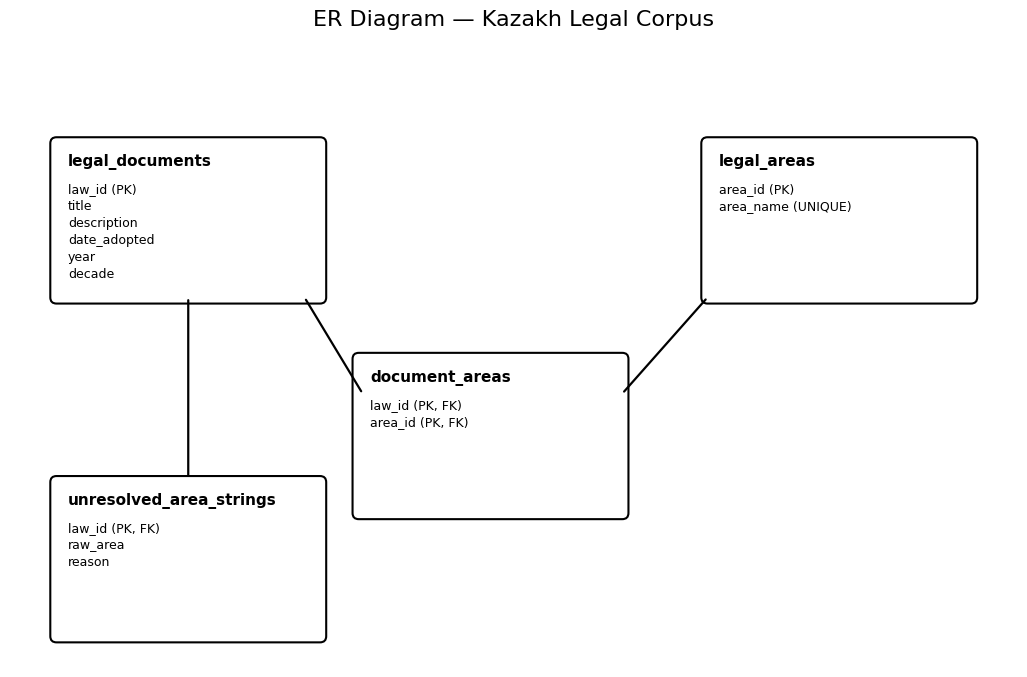


[PASSED] ER diagram saved: /content/drive/MyDrive/Kazakh_Legal_Language_Project/outputs/figures/normalized_database_er.png

ER DIAGRAM AND SQL ANALYSIS COMPLETED


In [91]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

print("=" * 65)
print("FINAL PROJECT — ER DIAGRAM AND SQL ANALYSIS")
print("=" * 65)

project = Path(
    "/content/drive/MyDrive/Kazakh_Legal_Language_Project"
)

db_path = (
    project / "data/database/"
    "kazakh_legal_corpus_normalized.db"
)

figure_dir = project / "outputs/figures"
sql_dir = project / "sql"

figure_dir.mkdir(parents=True, exist_ok=True)
sql_dir.mkdir(parents=True, exist_ok=True)

assert db_path.is_file()

queries = {
    "Q1 — Top legal areas": """
        SELECT a.area_name, COUNT(*) AS documents
        FROM legal_areas a
        JOIN document_areas da ON a.area_id = da.area_id
        GROUP BY a.area_id, a.area_name
        ORDER BY documents DESC
        LIMIT 10;
    """,

    "Q2 — Legal areas by decade": """
        SELECT d.decade, a.area_name,
               COUNT(*) AS documents
        FROM legal_documents d
        JOIN document_areas da ON d.law_id = da.law_id
        JOIN legal_areas a ON da.area_id = a.area_id
        WHERE d.decade >= 1990
        GROUP BY d.decade, a.area_id, a.area_name
        ORDER BY d.decade DESC, documents DESC
        LIMIT 15;
    """,

    "Q3 — Areas with at least 100 documents": """
        SELECT a.area_name, COUNT(*) AS documents
        FROM legal_areas a
        JOIN document_areas da ON a.area_id = da.area_id
        GROUP BY a.area_id, a.area_name
        HAVING COUNT(*) >= 100
        ORDER BY documents DESC
        LIMIT 10;
    """,

    "Q4 — Multi-area documents": """
        SELECT COUNT(*) AS multi_area_documents
        FROM (
            SELECT law_id
            FROM document_areas
            GROUP BY law_id
            HAVING COUNT(DISTINCT area_id) > 1
        );
    """,

    "Q5 — Ranked legal areas by decade": """
        WITH area_counts AS (
            SELECT d.decade, a.area_name,
                   COUNT(*) AS documents
            FROM legal_documents d
            JOIN document_areas da
                 ON d.law_id = da.law_id
            JOIN legal_areas a
                 ON da.area_id = a.area_id
            WHERE d.decade >= 1990
            GROUP BY d.decade, a.area_id, a.area_name
        ),
        ranked AS (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY decade
                       ORDER BY documents DESC, area_name
                   ) AS rank_in_decade
            FROM area_counts
        )
        SELECT *
        FROM ranked
        WHERE rank_in_decade <= 3
        ORDER BY decade, rank_in_decade;
    """,

    "Q6 — Unresolved categories by decade": """
        SELECT d.decade,
               COUNT(*) AS total_documents,
               COUNT(u.law_id) AS unresolved,
               ROUND(
                   100.0 * COUNT(u.law_id) /
                   NULLIF(COUNT(*), 0), 2
               ) AS unresolved_percent
        FROM legal_documents d
        LEFT JOIN unresolved_area_strings u
             ON d.law_id = u.law_id
        WHERE d.decade >= 1990
        GROUP BY d.decade
        ORDER BY d.decade;
    """,

    "Q7 — Category diversity by decade": """
        SELECT d.decade,
               COUNT(DISTINCT da.area_id)
                   AS distinct_areas,
               COUNT(DISTINCT d.law_id)
                   AS classified_documents
        FROM legal_documents d
        JOIN document_areas da
             ON d.law_id = da.law_id
        WHERE d.decade >= 1990
        GROUP BY d.decade
        ORDER BY d.decade;
    """,

    "Q8 — Top years for legal area links": """
        WITH yearly_counts AS (
            SELECT d.year,
                   COUNT(*) AS area_links
            FROM legal_documents d
            JOIN document_areas da
                 ON d.law_id = da.law_id
            WHERE d.year IS NOT NULL
            GROUP BY d.year
        )
        SELECT year, area_links
        FROM yearly_counts
        ORDER BY area_links DESC
        LIMIT 10;
    """
}

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA query_only = ON")

    print("\nSQL QUERY RESULTS")

    for name, query in queries.items():
        result = pd.read_sql_query(query, conn)
        print("\n" + "-" * 60)
        print(name)
        display(result.head(12))

print("\n[PASSED] All 8 SQL queries executed")

sql_path = sql_dir / "normalized_analysis.sql"

assert not sql_path.exists(), "SQL file already exists"

sql_content = "\n\n".join(
    f"-- {name}\n{query.strip()}"
    for name, query in queries.items()
)

sql_path.write_text(sql_content, encoding="utf-8")

print("[PASSED] SQL queries saved:", sql_path)

fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 8)
ax.axis("off")

tables = {
    "legal_documents": (
        0.6, 4.8,
        ["law_id (PK)", "title", "description",
         "date_adopted", "year", "decade"]
    ),
    "legal_areas": (
        9.0, 4.8,
        ["area_id (PK)", "area_name (UNIQUE)"]
    ),
    "document_areas": (
        4.5, 2.0,
        ["law_id (PK, FK)", "area_id (PK, FK)"]
    ),
    "unresolved_area_strings": (
        0.6, 0.4,
        ["law_id (PK, FK)", "raw_area", "reason"]
    )
}

width = 3.4
height = 2.0

for name, (x, y, fields) in tables.items():
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.08",
        facecolor="white",
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + 0.15, y + height - 0.3,
        name, fontsize=11, weight="bold"
    )

    for j, field in enumerate(fields):
        ax.text(
            x + 0.15,
            y + height - 0.65 - j * 0.22,
            field,
            fontsize=9
        )

ax.annotate(
    "", xy=(4.55, 3.55), xytext=(3.8, 4.8),
    arrowprops=dict(arrowstyle="-", lw=1.6)
)

ax.annotate(
    "", xy=(7.9, 3.55), xytext=(9.0, 4.8),
    arrowprops=dict(arrowstyle="-", lw=1.6)
)

ax.annotate(
    "", xy=(2.3, 2.45), xytext=(2.3, 4.8),
    arrowprops=dict(arrowstyle="-", lw=1.6)
)

ax.set_title(
    "ER Diagram — Kazakh Legal Corpus",
    fontsize=16,
    pad=18
)

figure_path = figure_dir / "normalized_database_er.png"

assert not figure_path.exists(), "ER diagram already exists"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n[PASSED] ER diagram saved:", figure_path)

print("\n" + "=" * 65)
print("ER DIAGRAM AND SQL ANALYSIS COMPLETED")
print("=" * 65)